# Normativa docente de Catamarca: del corpus a los fragmentos

Este notebook arma el corpus para un sistema de preguntas y respuestas sobre la normativa docente
de Catamarca y lo parte en fragmentos para la búsqueda. La idea es que un docente o alguien de la
administración escolar pueda preguntar, por ejemplo, cómo se cubre una suplencia o qué licencia le
corresponde, y reciba la norma y el artículo que lo regulan, siempre que esa norma siga vigente.

Se trabaja con 13 normas del Digesto de Catamarca, de 1976 a 2025. El trabajo se divide en las dos
etapas de un RAG: el **Pre-RAG** prepara el corpus antes de que llegue una consulta (limpieza,
análisis y fragmentos) y el **Post-RAG** responde a la consulta (búsqueda de los fragmentos y
generación de la respuesta), y ahí se mide con el conjunto de evaluación.

| Etapa | Secciones | Qué hacen |
|---|---|---|
| Pre-RAG | 1 a 4 | Instalan lo necesario, descargan las normas, extraen el texto y lo limpian, con los DNI ocultos |
| Pre-RAG | 5 | Análisis exploratorio del corpus (EDA) |
| Pre-RAG | 5b a 6 | Separan las normas que vienen juntas en la página del Estatuto, eliminan las copias y buscan entidades |
| Pre-RAG | 7 | Controles del corpus y de sus cifras |
| Pre-RAG | 8 y 9 | Parten el corpus en fragmentos de tres maneras: por artículo (E2) y en tramos de tamaño fijo (E0 y E1) |
| Pre-RAG | 10 y 11 | Análisis de los fragmentos y sus controles |
| Post-RAG | 12 | Conjunto de evaluación: las preguntas con las que se mide el sistema, con la evidencia que las responde |

Las tres maneras de fragmentar se van a comparar en la búsqueda con el mismo conjunto de preguntas (sección 12):
**E0** corta el corpus entero en tramos de 200 tokens, **E1** hace lo mismo norma por norma y **E2**
sigue la estructura de la norma (un artículo por fragmento).

**Fuente:** Digesto de Catamarca (`https://digesto.catamarca.gob.ar`), a partir de una copia
guardada el 10/11/2026 (sección 2).

**Cómo ejecutarlo:** en Google Colab, `Runtime → Run all`. Los resultados quedan en
`/content/normativa_docente/`, con una carpeta por etapa (sección 1.1).

**Cómo leerlo:** cada sección empieza con un diagrama de flujo con sus funciones y sus archivos, y
cada gráfico termina con su hallazgo y la decisión que se toma a partir de él. Al final están el
árbol de archivos y la lista de lo que hay que revisar después de ejecutar.

![Recorrido del notebook](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_b/diagramas/fig34_flujo_corte_b.png)


# Pre-RAG: preparar el corpus y sus fragmentos

Todo lo que se hace antes de que llegue una consulta: descargar las normas, extraer y limpiar su
texto, analizarlo, buscar entidades y partirlo en fragmentos (secciones 1 a 11). La calidad de esta
etapa limita a todo lo que sigue: si un fragmento corta la respuesta o mezcla dos normas, la
búsqueda no lo puede arreglar.

## 1. Setup

Todo lo que el notebook necesita se instala e importa en esta sección, que se corre una sola vez.
Ninguna otra celda importa librerías.

| Librería | Para qué se usa |
|---|---|
| `requests` | Descargar la instantánea desde GitHub y consultar el Digesto |
| `beautifulsoup4` | Leer las páginas HTML y la ficha de cada norma |
| `pdfplumber` | Extraer el texto de los PDF página por página |
| `pypdf` | Contar las páginas de cada PDF |
| `hashlib` (de Python) | Calcular la huella SHA-256 de cada archivo, para comprobar que es el mismo que se guardó |
| `re`, `unicodedata` (de Python) | Buscar patrones (artículos, DNI, encabezados) y normalizar caracteres |
| `pandas`, `numpy` | Tablas y cálculos |
| `matplotlib`, `seaborn` | Gráficos |
| `tiktoken` | Contar tokens como los cuenta un modelo de lenguaje |
| `scikit-learn` | Similitud coseno TF-IDF entre normas |
| `nltk` | Palabras vacías del español, n-gramas y reducción de las palabras a su raíz |
| `pprint` (de Python) | Mostrar registros de ejemplo de forma legible |

In [1]:
# pillow: pdfplumber 0.11.10 exige >=12.2 y el Gradio preinstalado en Colab exige <13
!pip install -q pdfplumber pypdf beautifulsoup4 requests tiktoken matplotlib seaborn pandas openpyxl pymupdf nltk "pillow>=12.2,<13" scikit-learn
print("Dependencias instaladas")

Dependencias instaladas


In [2]:
# Librerías de Python
import csv, difflib, hashlib, html, io, json, re, time, unicodedata
from collections import Counter, defaultdict
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

# Librerías instaladas
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
import nltk
import numpy as np
import pandas as pd
import pdfplumber
import requests
import seaborn as sns
import tiktoken
from bs4 import BeautifulSoup
from IPython.display import HTML, display
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.util import ngrams
from pypdf import PdfReader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download("stopwords", quiet=True)  # lista de palabras vacías del español
print("Librerías importadas")

Librerías importadas


### 1.1 Carpetas de trabajo

Todo se guarda bajo una carpeta raíz, con una subcarpeta por etapa. Cada etapa lee la carpeta de la
anterior y escribe en la suya, así se puede revisar qué salió de cada paso.

| Carpeta | Qué guarda | La escribe | La lee |
|---|---|---|---|
| `fuente_digesto/` (opcional) | Copia local de la instantánea del Digesto; si no está, se descarga de GitHub | — | 2. Adquisición |
| `conjunto_evaluacion.csv` (opcional) | Copia local del conjunto de evaluación; si no está, se descarga de GitHub | — | 13 |
| `raw/` | Los archivos tal como vienen del Digesto: 13 normas (HTML o PDF) y 8 fichas | 2. Adquisición | 3. Extracción |
| `text/` | Un JSON por norma, con el texto de cada página | 3. Extracción | 4. Limpieza y 9 (página de cada fragmento) |
| `clean/` | Un TXT por norma, limpio y con los DNI ocultos | 4. Limpieza | 5, 5b, 5c y 6 |
| `artifacts/` | Tablas (CSV), el corpus sin duplicados (`corpus_dedup.jsonl`), los fragmentos (`fragmentos_e0.jsonl`, `fragmentos_e1.jsonl`, `fragmentos_e2.jsonl`) y el conjunto de evaluación (`conjunto_evaluacion.csv`) | todas | 8 a 13 y la búsqueda |
| `figuras/` | Gráficos del EDA (`eda_*.png`) y de los fragmentos (`frag_*.png`) | 5 y 11 | el informe |

Al final del notebook se muestra el árbol con los archivos generados.


In [3]:
# Constantes y carpetas de trabajo
DIGESTO = "https://digesto.catamarca.gob.ar/"
# Instantánea del Digesto publicada en el repositorio del proyecto (archivos y manifiesto con SHA-256)
INSTANTANEA_URL = "https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_a/fuente_digesto/"
EXPECTED_DOCS = 13
ROOT = Path("/content/normativa_docente")
RAW = ROOT / "raw"
TEXT = ROOT / "text"
CLEAN = ROOT / "clean"
ART = ROOT / "artifacts"
FIGS = ROOT / "figuras"
INSTANTANEA_LOCAL = ROOT / "fuente_digesto"  # si existe (copia local del repositorio), se usa en lugar de la URL
for d in [RAW, TEXT, CLEAN, ART, FIGS]:
    d.mkdir(parents=True, exist_ok=True)

HEADERS = {"User-Agent": "TF-IA-Catamarca/1.0 (academic research)"}
stop_es = set(stopwords.words("spanish"))  # palabras vacías del español (NLTK)
NEGACIONES = {"no", "ni", "sin", "nunca", "tampoco"}  # cambian el sentido de una norma: se preservan siempre
FUENTE = "Fuente: Digesto de Catamarca (instantánea del 2026-11-10)"
print("Raíz:", ROOT)

Raíz: /content/normativa_docente


In [4]:
# Versiones de las librerías usadas en esta corrida
VERSIONS = {pkg: version(pkg) for pkg in [
    "requests", "beautifulsoup4", "pandas", "numpy", "matplotlib", "pdfplumber",
    "pypdf", "pymupdf", "tiktoken", "scikit-learn", "nltk",
]}
print("Versiones:", VERSIONS)

Versiones: {'requests': '2.32.4', 'beautifulsoup4': '4.13.5', 'pandas': '2.2.3', 'numpy': '2.4.6', 'matplotlib': '3.10.0', 'pdfplumber': '0.11.10', 'pypdf': '7.1.1', 'pymupdf': '2.2', 'tiktoken': '0.14.0', 'scikit-learn': '1.6.1', 'nltk': '3.9.1'}


## 2. Adquisición

Se trabaja con 13 normas. El estado que muestra la
ficha del Digesto se guarda en otra columna (`estado_digesto`), porque no siempre está al día: la
ficha del Decreto Acuerdo 2010/2013 dice “Vigente”, pero el artículo 4 del Decreto Acuerdo 533/2021
lo deroga.

El Digesto tiene una protección contra robots (Cloudflare) que bloquea las conexiones desde Colab
con un error 403, y tampoco deja guardar sus páginas en Wayback Machine. Por eso las normas se
descargaron desde una computadora personal el 10/11/2026 y se guardaron en la carpeta
`fuente_digesto` del repositorio, con un manifiesto que registra la URL de origen, la fecha y el
hash SHA-256 de cada archivo. El notebook baja esos archivos y se detiene si algún hash no
coincide.

Si se ejecuta en una máquina donde el Digesto sí responde, además compara cada norma con la versión
publicada ese día y avisa si alguna cambió.

### 2.1 Normas de entrada

La lista `NORMAS` es la **entrada** de todo el proceso: el notebook procesa las normas que están en
ella y nada más. Cada fila tiene:

| Columna | Qué es |
|---|---|
| `doc_id` | Nombre corto de la norma, que se usa en todos los archivos |
| `norma_id`, `tipo`, `numero` | Nombre, tipo y número de la norma |
| `ruta` | Dirección de la norma dentro del Digesto |
| `patron_titulo` | Patrón para comprobar que el archivo descargado es la norma esperada |
| `estado` | Estado que se usa en el corpus: Vigente o Derogado (decisión registrada) |
| `relacion_3122`, `articulo_3122` | Relación con el Estatuto: base, modifica, reglamenta o independiente, y el artículo que afecta |

**Para sumar una norma** no hace falta tocar el resto del notebook:
1. guardar el archivo y su ficha en `fuente_digesto/`, con su SHA-256 en `manifiesto_fuente.csv`;
2. agregar su fila a `NORMAS` y actualizar `EXPECTED_DOCS`;
3. ejecutar todo de nuevo.

In [5]:
# doc_id, norma_id, tipo, ruta del texto en el Digesto, número, patrón del título, estado decidido,
# relación con el Estatuto (Decreto Ley 3122) y artículo del Estatuto que afecta
NORMAS = [
    ("estatuto_dl3122", "Decreto Ley 3122", "Decreto Ley", "ley/ley_detail/713", "3122", r"Decreto Ley N[º°] ?3122", "Vigente", "base", ""),
    ("ley5301", "Ley 5301", "Ley", "ley/ley_detail/146", "5301", r"Ley N[º°] ?5301", "Vigente", "modifica", "3"),
    ("dl3267", "Decreto Ley 3267", "Decreto Ley", "ley/ley_detail/2541", "3267", r"LEY N[º°] ?3267", "Vigente", "modifica", "7"),
    ("ley5852", "Ley 5852", "Ley", "digesto/crearpdf/ley/4514", "5852", r"Ley N[º°] ?5852", "Vigente", "modifica", "74"),
    ("ley4789", "Ley 4789", "Ley", "digesto/crearpdf/ley/1819", "4789", r"Ley N[º°] ?4789", "Vigente", "modifica", "28"),
    ("ley5103", "Ley 5103", "Ley", "digesto/crearpdf/ley/355", "5103", r"Ley N[º°] ?5103", "Vigente", "independiente", ""),
    ("ley5381", "Ley 5381", "Ley", "digesto/crearpdf/ley/196", "5381", r"Ley N[º°] ?5381", "Vigente", "independiente", ""),
    ("da1385_92", "Decreto Acuerdo 1385/92", "Decreto Acuerdo", "digesto/crearpdf/decreto/5205", "1385", r"Decreto Acuerdo N[º°] ?1385", "Vigente", "reglamenta", ""),
    ("da1092_15", "Decreto Acuerdo 1092/2015", "Decreto Acuerdo", "decreto/decreto_detail/3678", "1092", r"Decreto Acuerdo N[º°] ?1092", "Vigente", "reglamenta", ""),
    ("da2010_13", "Decreto Acuerdo 2010/2013", "Decreto Acuerdo", "digesto/crearpdf/decreto/4404", "2010", r"Decreto Acuerdo N[º°] ?2010", "Derogado", "reglamenta", ""),
    ("da533_21", "Decreto Acuerdo 533/2021", "Decreto Acuerdo", "digesto/crearpdf/decreto/3874", "533", r"Decreto Acuerdo N[º°] ?533", "Vigente", "reglamenta", ""),
    ("da636_21", "Decreto Acuerdo 636/2021", "Decreto Acuerdo", "digesto/crearpdf/decreto/3867", "636", r"Decreto Acuerdo N[º°] ?636", "Vigente", "reglamenta", ""),
    ("d928_25", "Decreto 928/2025", "Decreto", "decreto/decreto_detail/5202", "928", r"N[º°] ?928", "Vigente", "reglamenta", ""),
]
df_normas = pd.DataFrame(NORMAS, columns=["doc_id", "norma_id", "tipo", "ruta", "numero", "patron_titulo",
                                          "estado", "relacion_3122", "articulo_3122"])
assert len(df_normas) == EXPECTED_DOCS and df_normas["doc_id"].is_unique
df_normas[["doc_id", "norma_id", "tipo", "estado", "relacion_3122", "articulo_3122"]]

,doc_id,norma_id,tipo,estado,relacion_3122,articulo_3122
0,estatuto_dl3122,Decreto Ley 3122,Decreto Ley,Vigente,base,
1,ley5301,Ley 5301,Ley,Vigente,modifica,3
2,dl3267,Decreto Ley 3267,Decreto Ley,Vigente,modifica,7
3,ley5852,Ley 5852,Ley,Vigente,modifica,74
4,ley4789,Ley 4789,Ley,Vigente,modifica,28
5,ley5103,Ley 5103,Ley,Vigente,independiente,
6,ley5381,Ley 5381,Ley,Vigente,independiente,
7,da1385_92,Decreto Acuerdo 1385/92,Decreto Acuerdo,Vigente,reglamenta,
8,da1092_15,Decreto Acuerdo 1092/2015,Decreto Acuerdo,Vigente,reglamenta,
9,da2010_13,Decreto Acuerdo 2010/2013,Decreto Acuerdo,Derogado,reglamenta,


### 2.2 Descarga y verificación

![Flujo de la adquisición](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_a/diagramas/fig20_flujo_adquisicion.png)

Cada archivo se lee de la instantánea y su huella SHA-256 se compara con la del manifiesto: si una
no coincide, el notebook se detiene. Después se lee el título y el estado de cada norma. Si el
Digesto responde (desde Colab no responde), se compara cada norma con la versión del día.

In [6]:
def sha256_bytes(b: bytes) -> str:
    """Calcula la huella SHA-256 de un archivo.

    La huella sirve para comprobar que un archivo es exactamente el que se guardó: si cambia un
    solo byte, cambia la huella. Así se verifica cada archivo de la instantánea contra el manifiesto.

    Args:
        b: contenido del archivo, en bytes.

    Returns:
        La huella en hexadecimal (64 caracteres).
    """
    return hashlib.sha256(b).hexdigest()


def leer_instantanea(nombre: str) -> bytes:
    """Lee un archivo de la instantánea del Digesto.

    Usa la copia local si existe; si no, lo descarga del repositorio publicado (hasta 3 intentos).

    Args:
        nombre: nombre del archivo dentro de la carpeta fuente_digesto.

    Returns:
        El contenido del archivo, en bytes.
    """
    local = INSTANTANEA_LOCAL / nombre
    if local.exists():
        return local.read_bytes()
    for intento in range(3):
        try:
            r = requests.get(INSTANTANEA_URL + nombre, headers=HEADERS, timeout=60)
            r.raise_for_status()
            return r.content
        except requests.RequestException as e:
            ultimo = e
            time.sleep(2 * (intento + 1))
    raise RuntimeError(f"No se pudo descargar {INSTANTANEA_URL + nombre}: {ultimo}. "
                       "¿Está publicado el repositorio del proyecto?")


def texto_norma(b: bytes) -> str:
    """Extrae el texto de una norma, sea PDF o página HTML del Digesto.

    Quita la línea con la fecha de impresión, que cambia cada día, para poder comparar dos versiones.

    Args:
        b: contenido del archivo, en bytes.

    Returns:
        El texto en una sola línea, con los espacios normalizados.
    """
    if b[:4] == b"%PDF":
        with pdfplumber.open(io.BytesIO(b)) as pdf:
            t = "\n".join(p.extract_text() or "" for p in pdf.pages)
    else:
        div = BeautifulSoup(b, "html.parser").find(id="desplegable")  # bloque del cuerpo de la norma
        t = div.get_text("\n") if div else ""
    t = re.sub(r"\*+\s*Esta normativa fue impresa desde el Digesto Catamarca[^\n]*", "", t)
    return re.sub(r"\s+", " ", t).strip()


def estado_ficha(b: bytes) -> str | None:
    """Lee el estado de una norma (“Vigente”, “Reducida”…) en su ficha del Digesto.

    Args:
        b: contenido de la ficha HTML, en bytes.

    Returns:
        El estado como texto, o None si la ficha no lo trae.
    """
    s = BeautifulSoup(b, "html.parser").find("strong", string=re.compile("Estado:"))
    return re.sub(r"\s+", " ", s.parent.get_text(" ")).replace("Estado:", "").strip() if s else None


# 1) Manifiesto de la instantánea y verificación de cada archivo por SHA-256
man_inst = pd.read_csv(io.BytesIO(leer_instantanea("manifiesto_fuente.csv")), dtype=str)
hash_inst = {}
for r in man_inst.itertuples():
    b = leer_instantanea(r.archivo)
    hash_inst[r.archivo] = sha256_bytes(b) == r.sha256
    if hash_inst[r.archivo]:
        (RAW / r.archivo).write_bytes(b)
malos = [a for a, ok in hash_inst.items() if not ok]
assert not malos, f"Archivos de la instantánea con hash distinto al del manifiesto: {malos}"
FECHA_INSTANTANEA = man_inst["fecha_descarga"].iloc[0]
print(f"Instantánea del {FECHA_INSTANTANEA}: {len(hash_inst)} archivos, todos con el SHA-256 del manifiesto.")

# 2) Control de vigencia de la instantánea: comparar con el Digesto si responde
def digesto_responde() -> bool:
    """Prueba si el Digesto responde desde este entorno.

    Desde Colab, la protección anti-robots del sitio devuelve 403 o una página de espera.

    Returns:
        True si el Digesto devuelve la norma; False si no responde o bloquea.
    """
    try:
        r = requests.get(DIGESTO + NORMAS[1][3], headers=HEADERS, timeout=30)
        return r.status_code == 200 and b"Just a moment" not in r.content[:3000]
    except requests.RequestException:
        return False


ACCESO_DIGESTO = digesto_responde()
print("El Digesto responde desde este entorno:" if ACCESO_DIGESTO else
      "El Digesto no responde desde este entorno (verificación anti-bots): no se puede comparar con el texto del día.",
      ACCESO_DIGESTO if ACCESO_DIGESTO else "")

# 3) Manifiesto del corpus
manifest = []
for n in df_normas.itertuples():
    fila_t = man_inst[(man_inst["doc_id"] == n.doc_id) & (man_inst["rol"] == "texto")].iloc[0]
    fila_f = man_inst[(man_inst["doc_id"] == n.doc_id) & (man_inst["rol"] == "ficha")]
    b = (RAW / fila_t["archivo"]).read_bytes()
    ficha = (RAW / fila_f.iloc[0]["archivo"]).read_bytes() if len(fila_f) else b
    texto = texto_norma(b)
    control = "sin acceso al Digesto"
    if ACCESO_DIGESTO:
        try:
            hoy = requests.get(DIGESTO + n.ruta, headers=HEADERS, timeout=60).content
            control = "igual" if texto_norma(hoy) == texto else "CAMBIÓ: revisar y renovar la instantánea"
        except requests.RequestException:
            control = "sin acceso al Digesto"
        time.sleep(1)
    formato = "pdf" if b[:4] == b"%PDF" else "html"
    manifest.append({
        "doc_id": n.doc_id, "norma_id": n.norma_id, "tipo": n.tipo, "titulo": texto[:120],
        "url_origen": DIGESTO + n.ruta, "fuente": "Digesto Catamarca", "fuente_descarga": "instantanea",
        "fecha_instantanea": FECHA_INSTANTANEA, "archivo": str(RAW / fila_t["archivo"]), "formato": formato,
        "bytes": len(b), "sha256": sha256_bytes(b),
        "paginas": len(PdfReader(io.BytesIO(b)).pages) if formato == "pdf" else None,
        "estado_digesto": estado_ficha(ficha), "estado": n.estado,
        "relacion_3122": n.relacion_3122, "articulo_3122": n.articulo_3122,
        "titulo_esperado": bool(re.search(n.patron_titulo, texto[:600], re.I)),
        "control_vigencia": control,
    })
df_manifest = pd.DataFrame(manifest)
df_manifest.to_csv(ART / "manifest.csv", index=False)
df_manifest.to_json(ART / "manifest.json", orient="records", force_ascii=False, indent=2)

assert df_manifest["titulo_esperado"].all(), df_manifest.loc[~df_manifest["titulo_esperado"], "doc_id"].tolist()
difieren = df_manifest[df_manifest["estado"] != df_manifest["estado_digesto"]]
print("Normas cuyo estado decidido difiere de la ficha del Digesto:")
print(difieren[["norma_id", "estado_digesto", "estado"]].to_string(index=False))
if ACCESO_DIGESTO:
    print("Control contra el Digesto:", df_manifest["control_vigencia"].value_counts().to_dict())
else:
    print(f"No se pudo comparar con el Digesto desde este entorno; se usan las {len(df_manifest)} normas "
          f"de la instantánea del {FECHA_INSTANTANEA[:10]}.")
df_manifest[["doc_id", "norma_id", "formato", "paginas", "estado_digesto", "estado", "relacion_3122", "control_vigencia"]]

Instantánea del 2026-11-10T18:20:12-03:00: 21 archivos, todos con el SHA-256 del manifiesto.
El Digesto no responde desde este entorno (verificación anti-bots): no se puede comparar con el texto del día. 
Normas cuyo estado decidido difiere de la ficha del Digesto:
                 norma_id estado_digesto   estado
         Decreto Ley 3267       Reducida  Vigente
                 Ley 4789       Reducida  Vigente
                 Ley 5103       Reducida  Vigente
Decreto Acuerdo 2010/2013        Vigente Derogado
No se pudo comparar con el Digesto desde este entorno; se usan las 13 normas de la instantánea del 2026-11-10.


,doc_id,norma_id,formato,paginas,estado_digesto,estado,relacion_3122,control_vigencia
0,estatuto_dl3122,Decreto Ley 3122,html,NaN,Vigente,Vigente,base,sin acceso al Digesto
1,ley5301,Ley 5301,html,NaN,Vigente,Vigente,modifica,sin acceso al Digesto
2,dl3267,Decreto Ley 3267,html,NaN,Reducida,Vigente,modifica,sin acceso al Digesto
3,ley5852,Ley 5852,pdf,1.0,Vigente,Vigente,modifica,sin acceso al Digesto
4,ley4789,Ley 4789,pdf,1.0,Reducida,Vigente,modifica,sin acceso al Digesto
5,ley5103,Ley 5103,pdf,7.0,Reducida,Vigente,independiente,sin acceso al Digesto
6,ley5381,Ley 5381,pdf,18.0,Vigente,Vigente,independiente,sin acceso al Digesto
7,da1385_92,Decreto Acuerdo 1385/92,pdf,6.0,Vigente,Vigente,reglamenta,sin acceso al Digesto
8,da1092_15,Decreto Acuerdo 1092/2015,html,NaN,Vigente,Vigente,reglamenta,sin acceso al Digesto
9,da2010_13,Decreto Acuerdo 2010/2013,pdf,1.0,Vigente,Derogado,reglamenta,sin acceso al Digesto


## 3. Extracción de texto

![Flujo de la extracción](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_a/diagramas/fig21_flujo_extraccion.png)

De las páginas HTML se toma solo el bloque con el texto de la norma, sin el menú ni el formulario
de comentarios del sitio. Los PDF se leen página por página con `pdfplumber`, para conservar el
número de página, que después sirve para citar. La celda controla que todas las normas tengan
texto.

In [7]:
def extract_pdf_pages(path: str | Path) -> list[dict]:
    """Extrae el texto de un PDF página por página.

    Args:
        path: ruta del PDF.

    Returns:
        Una lista con un diccionario por página: número de página, texto y cantidad de caracteres.
    """
    pages = []
    with pdfplumber.open(str(path)) as pdf:
        for i, page in enumerate(pdf.pages, 1):
            text = page.extract_text() or ""
            pages.append({"page": i, "text": text, "chars": len(text.strip())})
    return pages


def extract_html(path: str | Path) -> list[dict]:
    """Extrae el texto de una página HTML del Digesto.

    Toma solo el bloque con el cuerpo de la norma (id “desplegable”), sin el menú ni el formulario
    de comentarios del sitio.

    Args:
        path: ruta del archivo HTML.

    Returns:
        Una lista con un solo diccionario: página None, texto y cantidad de caracteres.
    """
    div = BeautifulSoup(Path(path).read_bytes(), "html.parser").find(id="desplegable")
    text = div.get_text("\n") if div else ""
    return [{"page": None, "text": text, "chars": len(text.strip())}]


INTERFAZ = ["envianos tu comentario", "captcha", "lo estamos haciendo entre todos"]
corpus = []
for row in df_manifest.itertuples():
    pages = extract_pdf_pages(row.archivo) if row.formato == "pdf" else extract_html(row.archivo)
    texto = "\n".join(p["text"] for p in pages)
    payload = {
        "doc_id": row.doc_id, "norma_id": row.norma_id, "titulo": row.titulo, "url": row.url_origen,
        "formato": row.formato, "pages": pages, "chars_total": sum(p["chars"] for p in pages),
        "pages_empty": sum(1 for p in pages if p["chars"] < 20),
        "restos_interfaz": sum(texto.lower().count(x) for x in INTERFAZ),
    }
    (TEXT / f"{row.doc_id}.json").write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
    corpus.append(payload)

df_text = pd.DataFrame([
    {"doc_id": p["doc_id"], "formato": p["formato"], "paginas": len(p["pages"]) if p["formato"] == "pdf" else None,
     "chars_total": p["chars_total"], "paginas_vacias": p["pages_empty"], "restos_interfaz": p["restos_interfaz"],
     "sin_texto": p["chars_total"] < 200}
    for p in corpus
])
df_text.to_csv(ART / "text_layer.csv", index=False)
print("Normas sin texto extraíble:", df_text.loc[df_text["sin_texto"], "doc_id"].tolist() or "ninguna")
print("Restos de la interfaz del sitio en el texto:", int(df_text["restos_interfaz"].sum()))
df_text

Normas sin texto extraíble: ninguna
Restos de la interfaz del sitio en el texto: 0


,doc_id,formato,paginas,chars_total,paginas_vacias,restos_interfaz,sin_texto
0,estatuto_dl3122,html,NaN,308949,0,0,False
1,ley5301,html,NaN,1281,0,0,False
2,dl3267,html,NaN,1474,0,0,False
3,ley5852,pdf,1.0,1440,0,0,False
4,ley4789,pdf,1.0,1324,0,0,False
5,ley5103,pdf,7.0,45611,0,0,False
6,ley5381,pdf,18.0,149243,0,0,False
7,da1385_92,pdf,6.0,31030,0,0,False
8,da1092_15,html,NaN,78288,0,0,False
9,da2010_13,pdf,1.0,3684,0,0,False


**Cómo queda una norma después de extraerla.** Primera página de `text/da533_21.json`
(Decreto Acuerdo 533/2021, PDF), con el texto recortado:

In [8]:
def recortar(registro: dict, largo: int = 300) -> dict:
    """Copia un registro con los textos largos recortados, para mostrarlo en pantalla.

    Args:
        registro: un diccionario de un JSON o JSONL del corpus.
        largo: cantidad máxima de caracteres de cada texto.

    Returns:
        Un diccionario nuevo: los textos largos terminan en “…” y de las listas queda el primer elemento.
    """
    corto = {}
    for clave, valor in registro.items():
        if isinstance(valor, str) and len(valor) > largo:
            valor = valor[:largo] + "…"
        elif isinstance(valor, list) and valor:
            primero = recortar(valor[0], largo) if isinstance(valor[0], dict) else valor[0]
            valor = [primero] + ([f"… y {len(valor) - 1} más"] if len(valor) > 1 else [])
        corto[clave] = valor
    return corto


ejemplo_text = json.loads((TEXT / "da533_21.json").read_text(encoding="utf-8"))
pprint(recortar(ejemplo_text), sort_dicts=False, width=110)

{'doc_id': 'da533_21',
 'norma_id': 'Decreto Acuerdo 533/2021',
 'titulo': 'Gobierno de Catamarca Asesoría General de Gobierno Decreto Acuerdo N° 533 DEROGANSE LOS DECRETOS '
           'ACUERDON° 1692/20; N° 2',
 'url': 'https://digesto.catamarca.gob.ar/digesto/crearpdf/decreto/3874',
 'formato': 'pdf',
 'pages': [{'page': 1,
            'text': 'Gobierno de Catamarca\n'
                    'Asesoría General de Gobierno\n'
                    'Decreto Acuerdo N° 533\n'
                    'DEROGANSE LOS DECRETOS ACUERDON° 1692/20; N° 2010/13;\n'
                    'N° 2452/19 Y LARESOLUCION E. N° 215/20 Y FACULTASE\n'
                    'AL MINISTERIO DE TRABAJO Y RECURSOS HUMANOS A IMPLEMENTAR LAS ALTAS,\n'
                    'BAJAS, CAMBIOS DE SITUACION DE REVISTA DE TODOS LOS …',
            'chars': 4650},
           '… y 3 más'],
 'chars_total': 15720,
 'pages_empty': 0,
 'restos_interfaz': 0}


## 4. Limpieza

![Flujo de la limpieza](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_a/diagramas/fig22_flujo_limpieza.png)

Los PDF del Digesto traen un encabezado (“Gobierno de Catamarca – Asesoría General de Gobierno”) y
un pie con la fecha de impresión que no son parte de la norma, así que se sacan. También se
normalizan los caracteres y se unen las palabras cortadas con guion al final de línea. Se mide
cuánto texto se pierde (no debería pasar del 5 %) y se controla que no desaparezcan negaciones,
números de artículo ni fechas.

Algunas normas nombran personas con su DNI. En esta misma etapa los números de DNI se reemplazan
por X, así ningún archivo que se genera después los contiene.

Después de limpiar se muestran, lado a lado, el principio y el final de una norma en PDF tal como
salieron de la extracción y ya limpios: en rojo y tachado lo que la limpieza quitó; en amarillo lo
que cambió. El ejemplo no incluye un DNI, para no mostrar sus números en el notebook.

In [9]:
HEADER_LINES = [
    r"^gobierno de catamarca\s*$",
    r"^asesor[ií]a general de gobierno\s*$",
    r"^\*+\s*esta normativa fue impresa desde el digesto catamarca.*$",
    r"^ministerio de planificaci[oó]n y modernizaci[oó]n\s*$",
    r"^secretar[ií]a de modernizaci[oó]n del estado.*$",
]

# DNI con o sin puntos, precedido de DNI, D.N.I., M.I. o L.C.
DNI_RE = re.compile(r"\b(?:D\.?\s?N\.?\s?I\.?|M\.?\s?I\.?|L\.?\s?C\.?)\s*(?:N[°º]\.?|Nro\.?)?\s*:?\s*\d{1,2}\.?\d{3}\.?\d{3}\b", re.I)


def ocultar_dni(text: str) -> tuple[str, int]:
    """Reemplaza por X los dígitos de cada número de DNI del texto.

    Args:
        text: texto de una norma.

    Returns:
        El texto con los DNI ocultos y la cantidad de DNI encontrados.
    """
    n = len(DNI_RE.findall(text))
    return DNI_RE.sub(lambda m: re.sub(r"\d", "X", m.group(0)), text), n


MAX_LOSS_PCT = 5.0  # la limpieza no debe perder más del 5 % del texto
PRESERVE = {
    "negaciones": r"\b(?:no|sin|nunca|ni)\b",
    "articulos": r"ART[IÍ]CULO\s+\d+",
    "fechas": r"\b\d{1,2}/\d{1,2}/\d{2,4}\b|\b\d{1,2}\s+de\s+[a-záéíóú]+\s+(?:de\s+)?\d\.?\d{3}\b",
}


def nonblank(s: str) -> int:
    """Cuenta los caracteres que no son espacios ni saltos de línea.

    Args:
        s: un texto.

    Returns:
        La cantidad de caracteres no blancos.
    """
    return len(re.sub(r"\s+", "", s))


BOILERPLATE = {"chars": 0}  # caracteres no blancos de membrete quitados en la última llamada


def clean_text(text: str) -> str:
    """Limpia el texto extraído de una norma.

    Normaliza los caracteres (NFC), une las palabras cortadas con guion al final de línea y quita
    las líneas de encabezado y pie del Digesto. Deja en BOILERPLATE cuántos caracteres de
    encabezado y pie sacó.

    Args:
        text: texto extraído (todas las páginas juntas).

    Returns:
        El texto limpio.
    """
    BOILERPLATE["chars"] = 0
    text = unicodedata.normalize("NFC", text or "")
    text = text.replace("\u00ad", "").replace("\u00a0", " ").replace("\u2003", " ").replace("\r", "")
    text = re.sub(r"(?<=\w)-\n(?=\w)", "", text)
    lines = []
    for line in text.splitlines():
        s = line.strip()
        if not s:
            lines.append("")
            continue
        if any(re.match(p, s, re.I) for p in HEADER_LINES):
            BOILERPLATE["chars"] += nonblank(s)
            continue
        lines.append(s)
    text = "\n".join(lines)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


corpus = [json.loads(p.read_text(encoding="utf-8")) for p in sorted(TEXT.glob("*.json"))]
clean_rows = []
for payload in corpus:
    doc_id = payload["doc_id"]
    raw_text = "\n".join(p["text"] for p in payload["pages"])
    cleaned, n_dni = ocultar_dni(clean_text(raw_text))
    (CLEAN / f"{doc_id}.txt").write_text(cleaned, encoding="utf-8")
    row = {
        "doc_id": doc_id,
        "chars_raw": len(raw_text),
        "dni_ocultos": n_dni,
        "chars_clean": len(cleaned),
        # Sobre caracteres no blancos (normalizar espacios no es pérdida):
        # - pct_boilerplate: membrete quitado a propósito (se informa, no es pérdida de información)
        # - pct_lost: pérdida residual, la que no se explica por el membrete (umbral ≤ 5 %)
        "pct_boilerplate": round(100 * BOILERPLATE["chars"] / max(1, nonblank(raw_text)), 2),
        "pct_lost": round(100 * (1 - (nonblank(cleaned) + BOILERPLATE["chars"]) / max(1, nonblank(raw_text))), 2),
    }
    # Lo que la limpieza NO debe perder: negaciones, artículos y fechas
    for name, pat in PRESERVE.items():
        row[f"{name}_antes"] = len(re.findall(pat, raw_text, re.I))
        row[f"{name}_despues"] = len(re.findall(pat, cleaned, re.I))
    clean_rows.append(row)

df_clean = pd.DataFrame(clean_rows)
df_clean["pierde_mas_5pct"] = df_clean["pct_lost"] > MAX_LOSS_PCT
df_clean["preserva_todo"] = [
    all(r[f"{n}_antes"] == r[f"{n}_despues"] for n in PRESERVE) for _, r in df_clean.iterrows()
]
print(f"Membrete quitado: {df_clean['pct_boilerplate'].min():.1f}–{df_clean['pct_boilerplate'].max():.1f} % por documento (intencional).")
print(f"Pérdida residual máxima: {df_clean['pct_lost'].max():.2f} % (umbral {MAX_LOSS_PCT} %)")
print("Documentos sobre el umbral:", df_clean.loc[df_clean["pierde_mas_5pct"], "doc_id"].tolist() or "ninguno")
print(f"DNI ocultos: {int(df_clean['dni_ocultos'].sum())} en "
      f"{df_clean.loc[df_clean['dni_ocultos'] > 0, 'doc_id'].tolist() or 'ninguna norma'}")
print("Documentos que pierden negaciones, artículos o fechas:",
      df_clean.loc[~df_clean["preserva_todo"], "doc_id"].tolist() or "ninguno")
df_clean.to_csv(ART / "cleaning_stats.csv", index=False)
df_clean

Membrete quitado: 0.0–25.0 % por documento (intencional).
Pérdida residual máxima: 0.08 % (umbral 5.0 %)
Documentos sobre el umbral: ninguno
DNI ocultos: 9 en ['estatuto_dl3122', 'ley5103']
Documentos que pierden negaciones, artículos o fechas: ninguno


,doc_id,chars_raw,dni_ocultos,chars_clean,pct_boilerplate,pct_lost,negaciones_antes,negaciones_despues,articulos_antes,articulos_despues,fechas_antes,fechas_despues,pierde_mas_5pct,preserva_todo
0,d928_25,11549,0,11426,0.00,0.00,11,11,12,12,29,29,False,True
1,da1092_15,78371,0,76723,0.00,0.00,123,123,115,115,6,6,False,True
2,da1385_92,31035,0,30718,1.05,0.00,31,31,38,38,16,16,False,True
3,da2010_13,3684,0,3367,8.94,0.00,1,1,6,6,6,6,False,True
4,da533_21,15723,0,15404,2.08,0.01,4,4,15,15,15,15,False,True
5,da636_21,54654,0,54335,0.60,0.00,43,43,13,13,18,18,False,True
6,dl3267,1503,0,1450,0.00,0.00,1,1,8,8,1,1,False,True
7,estatuto_dl3122,308990,4,301926,0.00,0.00,362,362,462,462,58,58,False,True
8,ley4789,1324,0,1007,24.96,0.00,1,1,5,5,0,0,False,True
9,ley5103,45617,5,45300,0.72,0.00,31,31,70,70,2,2,False,True


In [10]:
def lado_a_lado(antes: str, despues: str, desde: int, n: int, titulo: str) -> str:
    """Arma una tabla HTML con n líneas del texto extraído (a partir de la línea `desde`) y su versión limpia.

    Rojo y tachado: líneas que la limpieza quitó; amarillo: líneas que cambiaron; verde: líneas nuevas.
    Las líneas vacías que la limpieza junta no se muestran.

    Returns:
        La tabla, como texto HTML.
    """
    a, b = antes.split("\n"), despues.split("\n")
    filas = []
    ops = difflib.SequenceMatcher(None, [l.strip() for l in a], b, autojunk=False).get_opcodes()
    for op, i1, i2, j1, j2 in ops:
        if i2 <= desde or i1 >= desde + n:
            continue
        izq, der = a[i1:i2], b[j1:j2]
        for k in range(max(len(izq), len(der))):
            fila_antes = i1 + min(k, max(len(izq) - 1, 0))  # línea del texto extraído que ocupa esta fila
            if not desde <= fila_antes < desde + n:
                continue
            x = izq[k] if k < len(izq) else ""
            y = der[k] if k < len(der) else ""
            if x.strip() or y.strip():
                filas.append((op, x, y))
    color = {"equal": "#ffffff", "delete": "#fee2e2", "replace": "#fef3c7", "insert": "#dcfce7"}
    celda = "padding:2px 8px;border-bottom:1px solid #e5e7eb;vertical-align:top;color:#111827"
    html_filas = "".join(
        f'<tr style="background:{color[op]}">'
        f'<td style="{celda}{";text-decoration:line-through" if op == "delete" else ""}">{html.escape(x)}</td>'
        f'<td style="{celda}">{html.escape(y)}</td></tr>'
        for op, x, y in filas)
    return (f'<p style="margin:10px 0 4px"><b>{titulo}</b></p>'
            '<table style="border-collapse:collapse;font-family:monospace;font-size:12px;width:100%">'
            '<tr style="background:#f3f4f6"><th style="text-align:left;padding:4px 8px;color:#111827;width:50%">ANTES (texto extraído)</th>'
            '<th style="text-align:left;padding:4px 8px;color:#111827">DESPUÉS (texto limpio)</th></tr>'
            f"{html_filas}</table>")


# Una norma en PDF: trae el encabezado y el pie del Digesto en cada página
EJEMPLO = "ley5103"
ejemplo = next(p for p in corpus if p["doc_id"] == EJEMPLO)
raw = "\n".join(p["text"] for p in ejemplo["pages"])
clean = (CLEAN / f"{EJEMPLO}.txt").read_text(encoding="utf-8")
lineas = raw.split("\n")
pie = next(i for i, l in enumerate(lineas) if "impresa desde el Digesto" in l)
assert not any(DNI_RE.search(l) for l in lineas[:8] + lineas[pie - 5:pie + 3]), "El ejemplo mostraría un DNI"
display(HTML(lado_a_lado(raw, clean, 0, 8, f"{ejemplo['norma_id']}: principio (encabezado de la página)")
             + lado_a_lado(raw, clean, pie - 5, 8, f"{ejemplo['norma_id']}: final (pie de impresión del Digesto)")))


ANTES (texto extraído),DESPUÉS (texto limpio)
Gobierno de Catamarca,
Asesoría General de Gobierno,
Ley Nº 5103 - Decreto Nº 1220,Ley Nº 5103 - Decreto Nº 1220
CONCURSO PARA CARGOS DE CONDUCCIÓN Y SUPERVISIÓN,CONCURSO PARA CARGOS DE CONDUCCIÓN Y SUPERVISIÓN
DE LAS UNIDADES EDUCATIVAS DE LA PROVINCIA,DE LAS UNIDADES EDUCATIVAS DE LA PROVINCIA
EL SENADO Y LA CAMARA DE DIPUTADOS,EL SENADO Y LA CAMARA DE DIPUTADOS
DE LA PROVINCIA DE CATAMARCA,DE LA PROVINCIA DE CATAMARCA
SANCIONAN CON FUERZA DE,SANCIONAN CON FUERZA DE
ANTES (texto extraído),DESPUÉS (texto limpio)
modificada por Ley 5021 y Ley 5103.,modificada por Ley 5021 y Ley 5103.


## 5. Análisis exploratorio (EDA)

![Flujo del análisis exploratorio](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_a/diagramas/fig27_flujo_eda.png)

Un texto no se puede graficar: primero hay que medirlo. Por eso cada norma se describe con
variables que sí se cuentan o se comparan. Estas son las que usa el análisis, con su tipo:

| Variable | Tipo | Ejemplo |
|---|---|---|
| Tokens por norma y por artículo | numérica discreta | 108 tokens (mediana de los artículos) |
| Tokens por carácter, similitud coseno, TTR y MATTR | numérica continua | 0,30 tokens por carácter |
| Tipo de norma | categórica nominal | Ley, Decreto, Decreto Acuerdo, Decreto Ley |
| Relación con el Estatuto | categórica nominal | base, modifica, reglamenta, independiente |
| Tipo de entidad | categórica nominal | NORMA, ARTICULO, FECHA, CARGO… |
| Estado | binaria | Vigente o Derogado |
| Formato | binaria | página HTML o PDF |
| Tiene nota de modificación | binaria | sí o no |
| Texto de la norma | texto libre | “ARTÍCULO 1º.- Apruébase el Sistema de Asamblea Pública…” |

El análisis sigue los pasos del EDA de texto: tokens, largo de los artículos, palabras vacías,
frases repetidas, riqueza del vocabulario, caracteres especiales y similitud. Cada paso termina con
su hallazgo y la decisión que se toma.

Cuando los valores van de unas pocas decenas a varios miles (los tokens de un artículo, por ejemplo),
el eje usa escala logarítmica: cada marca vale varias veces la anterior, pero se escribe con el
número común (10, 100, 512, 1 000), no como potencia de 10.

Hay **cinco gráficos**, numerados en el orden en que aparecen. Tres son los principales, porque
deciden el diseño: el **gráfico 1** (tokens por artículo: el artículo sirve como fragmento), el
**gráfico 3** (vigencia: hay normas derogadas que el sistema tiene que poder excluir) y el
**gráfico 4** (la similitud sola no alcanza para detectar duplicados). Los **gráficos 2 y 5** son de
apoyo: el 2 cruza el largo con el tipo de norma y el 5 compara el texto antes y después de la
limpieza (sección 5c). Los gráficos 3 y 4 están en la sección 5b, porque necesitan
el corte de la página del Estatuto. Los demás análisis se muestran como tablas o cifras, porque se
leen mejor así. Cada gráfico tiene antes
una celda con seis campos: variables, pregunta, gráfico, por qué, hallazgo y “…y por eso
decidimos”. El hallazgo también se calcula y se imprime debajo del gráfico, para comprobarlo. No
se lematiza ni se sacan las negaciones; la reducción de las palabras a su raíz solo se mide (5c).

In [11]:
enc = tiktoken.get_encoding("cl100k_base")


def numeros_comunes(eje, con_512: bool = False) -> None:
    """En un eje con escala logarítmica, marca valores comunes (10, 50, 100, 512…) en lugar de 10¹, 10².

    Args:
        eje: ax.xaxis o ax.yaxis, después de dibujar (usa los límites del eje).
        con_512: marca 512 (el límite del modelo de embeddings) en lugar de 500.
    """
    lo, hi = eje.get_view_interval()
    valores = (1, 2, 5, 10, 20, 50, 100, 200, 512 if con_512 else 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000, 500000)
    eje.set_major_locator(FixedLocator([v for v in valores if lo <= v <= hi]))
    eje.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
    eje.set_minor_formatter(NullFormatter())


def count_articles(text: str) -> int:
    """Cuenta las apariciones de “ARTÍCULO <número>” en un texto.

    Args:
        text: texto limpio de una norma.

    Returns:
        La cantidad de artículos encontrados.
    """
    return len(re.findall(r"ART[IÍ]CULO\s+\d+", text, re.I))


eda_rows = []
for payload in corpus:
    doc_id = payload["doc_id"]
    text = (CLEAN / f"{doc_id}.txt").read_text(encoding="utf-8")
    eda_rows.append({
        "doc_id": doc_id,
        "norma_id": payload["norma_id"],
        "formato": payload["formato"],
        "chars": len(text),
        "tokens": len(enc.encode(text)),
        "articles": count_articles(text),
    })

df_eda = pd.DataFrame(eda_rows).merge(df_manifest[["doc_id", "estado"]], on="doc_id").sort_values("tokens", ascending=False)
df_eda["pct_corpus"] = (100 * df_eda["tokens"] / df_eda["tokens"].sum()).round(1)
df_eda.to_csv(ART / "eda_stats.csv", index=False)
df_eda

,doc_id,norma_id,formato,chars,tokens,articles,estado,pct_corpus
7,estatuto_dl3122,Decreto Ley 3122,html,301926,82589,462,Vigente,43.6
11,ley5381,Ley 5381,pdf,148939,38439,193,Vigente,20.3
1,da1092_15,Decreto Acuerdo 1092/2015,html,76723,21057,115,Vigente,11.1
5,da636_21,Decreto Acuerdo 636/2021,pdf,54335,14898,13,Vigente,7.9
9,ley5103,Ley 5103,pdf,45300,12692,70,Vigente,6.7
2,da1385_92,Decreto Acuerdo 1385/92,pdf,30718,9374,38,Vigente,4.9
4,da533_21,Decreto Acuerdo 533/2021,pdf,15404,4503,15,Vigente,2.4
0,d928_25,Decreto 928/2025,html,11426,3366,12,Vigente,1.8
3,da2010_13,Decreto Acuerdo 2010/2013,pdf,3367,1076,6,Derogado,0.6
6,dl3267,Decreto Ley 3267,html,1450,456,8,Vigente,0.2


### 5.1 Tokens por norma y por carácter

¿Cada norma entra entera en los 512 tokens que lee el modelo de embeddings? La tabla muestra los
tokens (numérica discreta), los artículos y el peso de cada norma en el corpus.

In [12]:
over_512 = int((df_eda["tokens"] > 512).sum())
tabla_tokens = df_eda[["norma_id", "formato", "estado", "tokens", "articles", "pct_corpus"]].rename(
    columns={"norma_id": "norma", "articles": "artículos", "pct_corpus": "% de los tokens"})
print(f"Hallazgo: {over_512} de {len(df_eda)} normas superan los 512 tokens: no entran enteras en el modelo.")
print(f"Hallazgo: {df_eda.iloc[0]['norma_id']} concentra el {df_eda.iloc[0]['pct_corpus']} % de los tokens.")
print("Decisión: dividir las normas en fragmentos y medir el tamaño con el tokenizador del modelo de embeddings; "
      "evaluar por norma para que la más grande no tape a las demás.")
tabla_tokens

Hallazgo: 9 de 13 normas superan los 512 tokens: no entran enteras en el modelo.
Hallazgo: Decreto Ley 3122 concentra el 43.6 % de los tokens.
Decisión: dividir las normas en fragmentos y medir el tamaño con el tokenizador del modelo de embeddings; evaluar por norma para que la más grande no tape a las demás.


,norma,formato,estado,tokens,artículos,% de los tokens
7,Decreto Ley 3122,html,Vigente,82589,462,43.6
11,Ley 5381,pdf,Vigente,38439,193,20.3
1,Decreto Acuerdo 1092/2015,html,Vigente,21057,115,11.1
5,Decreto Acuerdo 636/2021,pdf,Vigente,14898,13,7.9
9,Ley 5103,pdf,Vigente,12692,70,6.7
2,Decreto Acuerdo 1385/92,pdf,Vigente,9374,38,4.9
4,Decreto Acuerdo 533/2021,pdf,Vigente,4503,15,2.4
0,Decreto 928/2025,html,Vigente,3366,12,1.8
3,Decreto Acuerdo 2010/2013,pdf,Derogado,1076,6,0.6
6,Decreto Ley 3267,html,Vigente,456,8,0.2


In [13]:
# Caracteres vs. tokens: la correlación es trivial (r ≈ 1), por eso no se grafica.
# Lo útil es la razón tokens/carácter para estimar presupuestos de chunking.
valid = df_eda[df_eda["chars"] > 0]
ratio = (valid["tokens"] / valid["chars"]).round(3)
print(ratio.describe().round(3).to_string())
pal_total = sum(len((CLEAN / f"{d}.txt").read_text(encoding="utf-8").split()) for d in df_eda["doc_id"])
print(f"Tokens por palabra en todo el corpus: {df_eda['tokens'].sum() / pal_total:.2f}")
print(f"Hallazgo: la razón tokens/carácter es {ratio.median():.3f} (mediana) y varía poco entre documentos.")
print("Decisión: estimar tokens desde caracteres solo para presupuestos; el chunk final se mide con el "
      "tokenizador del modelo de embeddings. Por eso este cruce no se grafica.")

count    13.000
mean      0.299
std       0.028
min       0.258
25%       0.274
50%       0.295
75%       0.318
max       0.354
Tokens por palabra en todo el corpus: 1.80
Hallazgo: la razón tokens/carácter es 0.295 (mediana) y varía poco entre documentos.
Decisión: estimar tokens desde caracteres solo para presupuestos; el chunk final se mide con el tokenizador del modelo de embeddings. Por eso este cruce no se grafica.


### 5.2 Largo de los artículos

#### Gráfico 1 (principal) — Tokens por artículo

- **Variables:** tokens por artículo (numérica discreta).
- **Pregunta:** ¿los artículos entran en los 512 tokens que lee el modelo de embeddings?
- **Gráfico:** histograma + KDE, con líneas en la mediana, la media, 200 y 512 tokens.
- **Por qué:** es una sola variable numérica.
- **Hallazgo:** 784 artículos; mediana 108 tokens y media 223; el 6,5 % supera 512.
- **…y por eso decidimos:** un artículo por fragmento, y dividir solo los que superan 512 tokens.

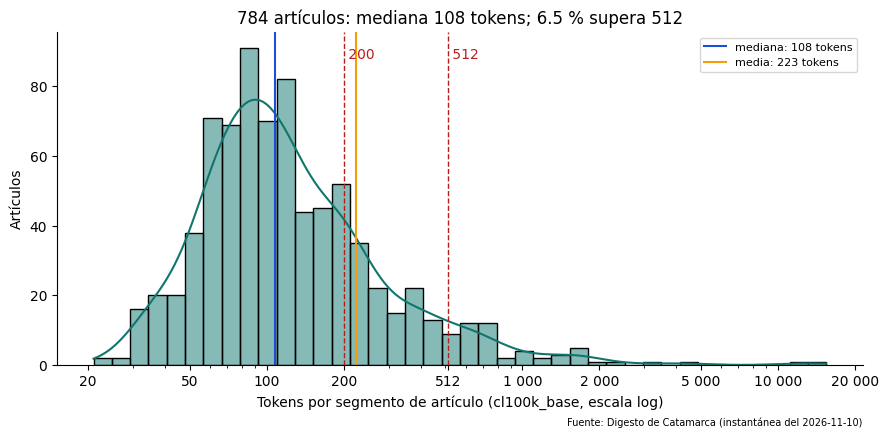

Segmentos de más de 1500 tokens (posibles fallas de segmentación o anexos):
         doc_id  tokens                                                                                     inicio
estatuto_dl3122   15454 * ARTICULO 87°: Deróguese cualquier norma que se oponga al régimen estatuido por el presen
       da636_21   11525 ARTÍCULO 6°.- Comuníquese, publíquese, dese al Registro Oficial y Archívese. ANEXO I Siste
estatuto_dl3122    4560  ARTICULO 18°.- El ejercicio de las facultades otorgadas por los artículos precedentes deb
      da1385_92    3414 ARTICULO 18°.- El ejercicio de las facultades otorgadas por los artículos precedentes debe
        ley5103    2230 ARTICULO 11 - Comuníquese, Publíquese y ARCHIVESE. DECRETO DE PROMULGACION: Nº 1220 (16/10
estatuto_dl3122    1996  ARTICULO 61°: Sin perjuicio de la aplicación de las Disposiciones normativas a que hace r
estatuto_dl3122    1728  ARTICULO 177.- Comuníquese, publíquese, dése al Registro Oficial y Archívese.  Decreto Ac
esta

In [14]:
# Unidad candidata de chunking: el artículo. Se mide su longitud en tokens.
ART_SPLIT = re.compile(r"(?m)^\*?\s*ART[IÍ]CULO\s+\d+")

art_rows = []
for payload in corpus:
    doc_id = payload["doc_id"]
    text = (CLEAN / f"{doc_id}.txt").read_text(encoding="utf-8")
    starts = [m.start() for m in ART_SPLIT.finditer(text)]
    for k, s in enumerate(starts):
        e = starts[k + 1] if k + 1 < len(starts) else len(text)
        body = text[s:e]
        art_rows.append({
            "doc_id": doc_id,
            "inicio": body[:90].replace("\n", " "),
            "tokens": len(enc.encode(body)),
            "modificado": body.lstrip().startswith("*") or bool(re.search(r"Modificad[oa]\s+por", body, re.I)),
        })

df_art_tok = pd.DataFrame(art_rows)
df_art_tok.to_csv(ART / "articles_tokens.csv", index=False)

med = df_art_tok["tokens"].median()
p90 = df_art_tok["tokens"].quantile(0.9)
pct_512 = 100 * (df_art_tok["tokens"] > 512).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(df_art_tok["tokens"], bins=40, log_scale=True, kde=True, color="#0f766e", ax=ax)
for x in (200, 512):
    ax.axvline(x, color="#b91c1c", linestyle="--", linewidth=1)
    ax.text(x, ax.get_ylim()[1] * 0.92, f" {x}", color="#b91c1c")
ax.axvline(med, color="#1d4ed8", linewidth=1.5, label=f"mediana: {med:.0f} tokens")
ax.axvline(df_art_tok["tokens"].mean(), color="#f59e0b", linewidth=1.5, label=f"media: {df_art_tok['tokens'].mean():.0f} tokens")
ax.legend(loc="upper right", fontsize=8)
numeros_comunes(ax.xaxis, con_512=True)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("Tokens por segmento de artículo (cl100k_base, escala log)")
ax.set_ylabel("Artículos")
ax.set_title(f"{len(df_art_tok)} artículos: mediana {med:.0f} tokens; {pct_512:.1f} % supera 512")
ax.text(1, -0.18, FUENTE,
        transform=ax.transAxes, ha="right", fontsize=7)
plt.tight_layout()
plt.savefig(FIGS / "eda_tokens_por_articulo.png", dpi=200, bbox_inches="tight")
plt.show()

long_segs = df_art_tok[df_art_tok["tokens"] > 1500].sort_values("tokens", ascending=False)
print("Segmentos de más de 1500 tokens (posibles fallas de segmentación o anexos):")
print(long_segs[["doc_id", "tokens", "inicio"]].head(8).to_string(index=False))

# Valores atípicos de longitud: umbrales de 100 y 800 tokens
UMBRAL_CORTO, UMBRAL_LARGO = 100, 800
df_art_tok["categoria"] = np.where(df_art_tok["tokens"] < UMBRAL_CORTO, "Demasiado corto",
                          np.where(df_art_tok["tokens"] > UMBRAL_LARGO, "Requiere sub-chunking", "Óptimo"))
print(df_art_tok["categoria"].value_counts().to_string())

top = df_eda.iloc[0]
print(f"Hallazgo: {len(df_art_tok)} artículos; mediana {med:.0f} tokens, p90 {p90:.0f}; {pct_512:.1f} % supera 512.")
print(f"Hallazgo: {top['doc_id']} concentra el {top['pct_corpus']} % de los tokens del corpus.")
print(f"Hallazgo: {int(df_art_tok['modificado'].sum())} artículos tienen marca de modificación.")
print(f"Hallazgo: {len(long_segs)} segmentos superan 1500 tokens; el mayor tiene {int(df_art_tok['tokens'].max())}: "
      "hay tramos (anexos, decretos agregados) que el patrón ARTICULO no separa.")
print("Decisión: chunk = artículo; subdividir solo los que superan el límite del modelo de embeddings; "
      "conservar la marca de modificación como metadato; estratificar las preguntas de evaluación por documento.")

#### Gráfico 2 (de apoyo) — Largo de los artículos según el tipo de norma

- **Variables:** tokens por artículo (numérica discreta) y tipo de norma (categórica nominal: Ley, Decreto, Decreto Acuerdo, Decreto Ley).
- **Pregunta:** ¿el largo de los artículos cambia según el tipo de norma?
- **Gráfico:** diagrama de caja con los puntos encima.
- **Por qué:** cruza una numérica con una categórica.
- **Hallazgo:** la mediana va de 49 tokens (Decreto) a 125 (Decreto Acuerdo); en todos los tipos la mayoría de los artículos queda por debajo de 512.
- **…y por eso decidimos:** el mismo criterio de fragmentación para todos los tipos de norma.

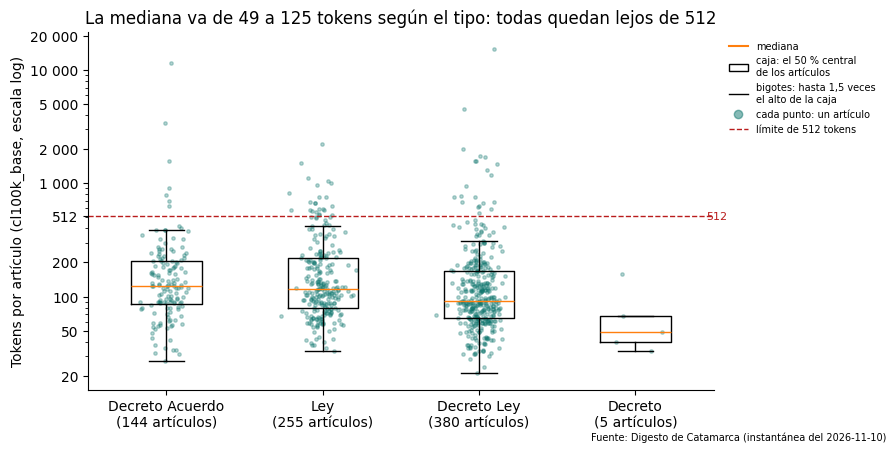

Mediana de tokens por artículo según el tipo de norma: {'Decreto Acuerdo': 125.0, 'Ley': 116.0, 'Decreto Ley': 92.0, 'Decreto': 49.0}
Hallazgo: la mediana va de 49 a 125 tokens; en todos los tipos, la mayoría de los artículos queda por debajo de 512.
Decisión: un mismo criterio de fragmentación para todos los tipos de norma (un artículo por fragmento), y dividir solo los artículos que superan el límite.


In [15]:
# Largo de los artículos según el tipo de norma (la página del Estatuto cuenta como Decreto Ley)
df_art_tok = df_art_tok.drop(columns=["tipo"], errors="ignore").merge(df_manifest[["doc_id", "tipo"]], on="doc_id", how="left")
med_tipo = df_art_tok.groupby("tipo")["tokens"].median().sort_values(ascending=False)
datos = [df_art_tok.loc[df_art_tok["tipo"] == t, "tokens"] for t in med_tipo.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(datos, showfliers=False)
rng = np.random.default_rng(0)
for k, d in enumerate(datos, 1):
    ax.scatter(rng.normal(k, 0.07, len(d)), d, s=6, alpha=0.3, color="#0f766e")
ax.set_xticks(range(1, len(datos) + 1), [f"{t}\n({len(d)} artículos)" for t, d in zip(med_tipo.index, datos)])
ax.set_yscale("log")
ax.axhline(512, color="#b91c1c", linestyle="--", linewidth=1)
ax.text(len(datos) + 0.45, 512, "512", color="#b91c1c", va="center", fontsize=8)
numeros_comunes(ax.yaxis, con_512=True)
# Cómo se lee la caja: la línea naranja es la mediana (el color que matplotlib usa por defecto)
ax.legend(handles=[
    Line2D([0], [0], color="C1", linewidth=1.5, label="mediana"),
    Patch(facecolor="white", edgecolor="black", label="caja: el 50 % central\nde los artículos"),
    Line2D([0], [0], color="black", linewidth=1, label="bigotes: hasta 1,5 veces\nel alto de la caja"),
    Line2D([0], [0], marker="o", linestyle="", color="#0f766e", alpha=0.5, label="cada punto: un artículo"),
    Line2D([0], [0], color="#b91c1c", linestyle="--", linewidth=1, label="límite de 512 tokens"),
], loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=7, frameon=False)
ax.set_ylabel("Tokens por artículo (cl100k_base, escala log)")
ax.set_title(f"La mediana va de {med_tipo.min():.0f} a {med_tipo.max():.0f} tokens según el tipo: todas quedan lejos de 512")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.99, 0.01, FUENTE, ha="right", fontsize=7)
plt.tight_layout()
plt.savefig(FIGS / "eda_tokens_por_tipo.png", dpi=200, bbox_inches="tight")
plt.show()

print("Mediana de tokens por artículo según el tipo de norma:", med_tipo.round(0).to_dict())
print(f"Hallazgo: la mediana va de {med_tipo.min():.0f} a {med_tipo.max():.0f} tokens; en todos los tipos, "
      f"la mayoría de los artículos queda por debajo de 512.")
print("Decisión: un mismo criterio de fragmentación para todos los tipos de norma (un artículo por fragmento), "
      "y dividir solo los artículos que superan el límite.")

**Una fila real con todos los tipos de variable.** Un texto no se puede graficar: primero hay que medirlo,
convirtiéndolo en variables de los otros tipos (cuántos tokens tiene, de qué tipo de norma es, si
está vigente, si fue modificado). Así se ve un artículo del Decreto Acuerdo 636/2021:

In [16]:
art = df_art_tok.merge(df_manifest[["doc_id", "estado", "formato", "relacion_3122"]], on="doc_id")
fila = art[art["doc_id"] == "da636_21"].iloc[1]
pd.DataFrame([
    {"tipo de variable": "numérica discreta", "variable": "tokens", "valor": fila["tokens"]},
    {"tipo de variable": "categórica nominal", "variable": "tipo de norma", "valor": fila["tipo"]},
    {"tipo de variable": "categórica nominal", "variable": "relación con el Estatuto", "valor": fila["relacion_3122"]},
    {"tipo de variable": "binaria", "variable": "estado (Vigente / Derogado)", "valor": fila["estado"]},
    {"tipo de variable": "binaria", "variable": "formato (html / pdf)", "valor": fila["formato"]},
    {"tipo de variable": "binaria", "variable": "tiene nota de modificación", "valor": fila["modificado"]},
    {"tipo de variable": "texto libre", "variable": "texto", "valor": fila["inicio"] + "…"},
])

,tipo de variable,variable,valor
0,numérica discreta,tokens,87
1,categórica nominal,tipo de norma,Decreto Acuerdo
2,categórica nominal,relación con el Estatuto,reglamenta
3,binaria,estado (Vigente / Derogado),Vigente
4,binaria,formato (html / pdf),pdf
5,binaria,tiene nota de modificación,False
6,texto libre,texto,ARTÍCULO 2º.- Apruébase el Sistema de Asamblea...


### 5.3 Palabras vacías

¿Cuánto del texto son palabras vacías, y entre ellas hay palabras que cambian el sentido de una
norma? Se mide el porcentaje por norma (numérica continua) y las 20 más frecuentes.

In [17]:
# Densidad de palabras vacías por norma
def palabras(texto: str) -> list[str]:
    """Separa un texto en palabras en minúscula (solo letras).

    Args:
        texto: un texto.

    Returns:
        La lista de palabras, en orden y con repeticiones.
    """
    return [t for t in re.findall(r"[a-záéíóúüñ]+", texto.lower())]


sw_rows = []
sw_counter = Counter()
for payload in corpus:
    doc_id = payload["doc_id"]
    tok = palabras((CLEAN / f"{doc_id}.txt").read_text(encoding="utf-8"))
    if not tok:
        continue
    sw = [t for t in tok if t in stop_es]
    sw_counter.update(sw)
    sw_rows.append({"doc_id": doc_id, "palabras": len(tok), "pct_vacias": round(100 * len(sw) / len(tok), 1)})
df_sw = pd.DataFrame(sw_rows).sort_values("pct_vacias", ascending=False)
top_sw = pd.DataFrame(sw_counter.most_common(20), columns=["palabra vacía", "veces"])
top_sw["negación (se conserva)"] = top_sw["palabra vacía"].isin(NEGACIONES)

neg = {w: sw_counter[w] for w in NEGACIONES if sw_counter[w]}
print(f"Hallazgo: las palabras vacías son el {df_sw['pct_vacias'].mean():.1f} % del texto en promedio "
      f"(entre {df_sw['pct_vacias'].min():.0f} % y {df_sw['pct_vacias'].max():.0f} % según la norma); negaciones: {neg}.")
print("Decisión: quitarlas solo en el baseline léxico (TF-IDF/BM25), conservando las negaciones; "
      "no quitarlas antes de los embeddings.")
display(df_sw)
top_sw

Hallazgo: las palabras vacías son el 42.8 % del texto en promedio (entre 38 % y 45 % según la norma); negaciones: {'sin': 143, 'ni': 25, 'no': 506}.
Decisión: quitarlas solo en el baseline léxico (TF-IDF/BM25), conservando las negaciones; no quitarlas antes de los embeddings.


,doc_id,palabras,pct_vacias
8,ley4789,161,45.3
5,da636_21,8385,45.0
11,ley5381,21286,44.7
7,estatuto_dl3122,44746,44.2
10,ley5301,191,44.0
9,ley5103,6662,43.4
1,da1092_15,11365,43.3
0,d928_25,1785,43.0
4,da533_21,2226,42.3
6,dl3267,208,41.3


,palabra vacía,veces,negación (se conserva)
0,de,9213,False
1,la,4398,False
2,y,3636,False
3,el,3171,False
4,en,2708,False
5,los,2209,False
6,a,2114,False
7,que,1978,False
8,del,1780,False
9,las,1531,False


### 5.4 Frases que más se repiten

¿Qué frases del dominio no habría que cortar al dividir el texto? Se cuentan los pares y tríos de
palabras seguidas (n-gramas), sin palabras vacías.

In [18]:
# N-gramas de dominio: frases compuestas que no deben separarse
def top_ngrams(texto: str, n: int, k: int = 15):
    """Busca las frases de n palabras seguidas que más se repiten, sin palabras vacías.

    Args:
        texto: un texto.
        n: cantidad de palabras de cada frase (2 = pares, 3 = tríos).
        k: cuántas frases devolver.

    Returns:
        Una lista de (frase, veces), de la más a la menos frecuente.
    """
    tok = [t for t in palabras(texto) if t not in stop_es and len(t) > 1]  # sin letras sueltas (“Ley N°” → “n”)
    return Counter(ngrams(tok, n)).most_common(k)


corpus_all_text = "\n".join((CLEAN / f"{p['doc_id']}.txt").read_text(encoding="utf-8") for p in corpus)
bigramas = top_ngrams(corpus_all_text, 2)
trigramas = top_ngrams(corpus_all_text, 3)
tabla_ngramas = pd.DataFrame({
    "bigrama": [" ".join(g) for g, _ in bigramas], "veces (2)": [c for _, c in bigramas],
    "trigrama": [" ".join(g) for g, _ in trigramas], "veces (3)": [c for _, c in trigramas],
})
NO_SEPARAR = [" ".join(g) for g, _ in bigramas[:10]]
print(f"Hallazgo: la frase más repetida es “{' '.join(bigramas[0][0])}” ({bigramas[0][1]} veces); "
      f"frases de dominio: {NO_SEPARAR[:5]}.")
print("Decisión: no cortar fragmentos dentro de estas frases y usarlas como vocabulario de control del baseline léxico.")
tabla_ngramas

Hallazgo: la frase más repetida es “ministerio educación” (167 veces); frases de dominio: ['ministerio educación', 'ciencia tecnología', 'educación ciencia', 'sistema educativo', 'personal docente'].
Decisión: no cortar fragmentos dentro de estas frases y usarlas como vocabulario de control del baseline léxico.


,bigrama,veces (2),trigrama,veces (3)
0,ministerio educación,167,educación ciencia tecnología,121
1,ciencia tecnología,133,ministerio educación ciencia,112
2,educación ciencia,121,sistema educativo provincial,62
3,sistema educativo,116,técnico docente analista,48
4,personal docente,98,ministerio cultura educación,44
5,técnico docente,92,proyecto educativo supervisión,37
6,junta clasificación,76,director unidad escolar,34
7,decreto acuerdo,72,consejo general educación,33
8,recursos humanos,72,ley estatuto docente,32
9,junta electoral,69,estatuto docente provincial,32


### 5.5 Riqueza del vocabulario (TTR y MATTR)

¿El TTR sirve para comparar normas de distinto largo, o conviene el MATTR? Las dos medidas son
numéricas continuas, entre 0 y 1.

In [19]:
# Riqueza léxica: TTR y MATTR con ventana de 50
def ttr(texto: str, ventana: int | None = None) -> float:
    """Mide la riqueza del vocabulario: palabras distintas sobre palabras totales.

    Sin ventana es el TTR. Con ventana es el MATTR: el promedio del TTR en tramos de ese largo,
    que permite comparar textos de distinto tamaño.

    Args:
        texto: un texto.
        ventana: largo del tramo en palabras (None para el TTR simple).

    Returns:
        Un valor entre 0 y 1 (1 = ninguna palabra se repite).
    """
    tok = palabras(texto)
    if not tok:
        return 0.0
    if ventana is None:
        return len(set(tok)) / len(tok)
    if len(tok) < ventana:
        return len(set(tok)) / len(tok)
    return float(np.mean([len(set(tok[k:k + ventana])) / ventana for k in range(len(tok) - ventana + 1)]))


ttr_rows = []
for payload in corpus:
    texto = (CLEAN / f"{payload['doc_id']}.txt").read_text(encoding="utf-8")
    if texto.strip():
        ttr_rows.append({"doc_id": payload["doc_id"], "palabras": len(palabras(texto)),
                         "ttr": round(ttr(texto), 3), "mattr_50": round(ttr(texto, 50), 3)})
df_ttr = pd.DataFrame(ttr_rows).sort_values("palabras")

print(df_ttr.to_string(index=False))
print(f"Hallazgo: TTR de {df_ttr['ttr'].min():.2f} a {df_ttr['ttr'].max():.2f} (depende de la longitud); "
      f"MATTR de {df_ttr['mattr_50'].min():.2f} a {df_ttr['mattr_50'].max():.2f}.")
print("Decisión: comparar documentos con MATTR, no con TTR; lematizar solo para el baseline léxico y "
      "nunca antes de los embeddings.")

         doc_id  palabras   ttr  mattr_50
        ley4789       161 0.540     0.741
        ley5852       172 0.547     0.748
        ley5301       191 0.487     0.699
         dl3267       208 0.582     0.769
      da2010_13       515 0.357     0.682
        d928_25      1785 0.244     0.742
       da533_21      2226 0.279     0.755
      da1385_92      4320 0.219     0.709
        ley5103      6662 0.200     0.748
       da636_21      8385 0.140     0.737
      da1092_15     11365 0.170     0.760
        ley5381     21286 0.117     0.736
estatuto_dl3122     44746 0.105     0.750
Hallazgo: TTR de 0.10 a 0.58 (depende de la longitud); MATTR de 0.68 a 0.77.
Decisión: comparar documentos con MATTR, no con TTR; lematizar solo para el baseline léxico y nunca antes de los embeddings.


### 5.6 Caracteres especiales

¿El paso de PDF y HTML a texto dejó caracteres raros o errores de codificación?

In [20]:
# Caracteres especiales del texto extraído
chars_esp = Counter(ch for ch in corpus_all_text if ord(ch) > 127)
df_chars = pd.DataFrame([{"caracter": ch, "unicode": f"U+{ord(ch):04X}", "ocurrencias": n}
                         for ch, n in chars_esp.most_common()])
print(df_chars.head(20).to_string(index=False))
esperados = set("áéíóúÁÉÍÓÚñÑüÜ°º«»“”–—¿¡")
raros = df_chars[~df_chars["caracter"].isin(esperados)]
print(f"Hallazgo: {int(df_chars['ocurrencias'].sum())} caracteres no ASCII en {len(df_chars)} tipos; "
      f"{len(raros)} tipos fuera del español esperado.")
print("Decisión: la normalización NFC alcanza para los acentos; los tipos raros se revisan antes de indexar "
      "(no se reemplaza “Nº” por “No”).")

caracter unicode  ocurrencias
       ó  U+00F3         5059
       á  U+00E1         2956
       í  U+00ED         1835
       é  U+00E9         1016
       °  U+00B0          848
       ñ  U+00F1          629
       º  U+00BA          480
       ú  U+00FA          426
       Í  U+00CD          345
       Ó  U+00D3          127
       ü  U+00FC           88
       «  U+00AB           80
       »  U+00BB           80
       “  U+201C           40
       ”  U+201D           40
       •  U+2022           31
       Ú  U+00DA           26
       –  U+2013           22
       É  U+00C9           18
       Ñ  U+00D1           13
Hallazgo: 14175 caracteres no ASCII en 25 tipos; 3 tipos fuera del español esperado.
Decisión: la normalización NFC alcanza para los acentos; los tipos raros se revisan antes de indexar (no se reemplaza “Nº” por “No”).


### 5.7 Similitud entre normas

¿Hay normas casi iguales que el sistema podría confundir al buscar? Se hace en dos pasos:

1. **TF-IDF** convierte cada norma en una lista de números: el peso de cada palabra, que es alto si
   la palabra aparece mucho en esa norma y poco en las demás. Las palabras vacías no se cuentan.
2. La **similitud coseno** compara esas listas de a pares: da 1 si dos normas usan las mismas
   palabras con el mismo peso y 0 si no comparten ninguna (numérica continua, de 0 a 1).

In [21]:
texts = []
labels = []
for payload in corpus:
    doc_id = payload["doc_id"]
    text = (CLEAN / f"{doc_id}.txt").read_text(encoding="utf-8")
    if text.strip():
        labels.append(doc_id)
        texts.append(text)

# Palabras vacías del español (lista corta, sin acentos para coincidir con strip_accents)
STOPWORDS_ES = """de la que el en y a los del se las por un para con una su al lo como mas o pero sus
le ya fue este ha si porque esta son entre cuando muy sobre ser tiene tambien me hasta hay donde quien
desde todo nos durante todos uno les contra otros ese eso ante ellos e esto mi antes algunos que unos
otro otras otra el tanto esa estos mucho quienes nada muchos cual poco ella estar estas algunas algo""".split()
# Las negaciones (no, sin, ni, nunca) NO se quitan: cambian el sentido de la norma.


def tfidf_sim(stop_words=None):
    """Calcula la similitud coseno TF-IDF entre todas las normas (variable global texts).

    Args:
        stop_words: lista de palabras que se ignoran (None para no quitar ninguna).

    Returns:
        Una matriz cuadrada con la similitud de cada par de normas, de 0 a 1.
    """
    v = TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2),
                        min_df=1, stop_words=stop_words)
    return cosine_similarity(v.fit_transform(texts))


sim_raw = tfidf_sim()
sim = tfidf_sim(STOPWORDS_ES)
iu = np.triu_indices(len(labels), 1)
print(f"Similitud mediana entre pares: {np.median(sim_raw[iu]):.2f} con palabras vacías; "
      f"{np.median(sim[iu]):.2f} sin ellas.")

pares_sim = sorted(((float(sim[r, c]), labels[r], labels[c]) for r in range(len(labels)) for c in range(r + 1, len(labels))),
                   reverse=True)[:5]
display(pd.DataFrame(pares_sim, columns=["coseno", "norma A", "norma B"]).round(2))

off = sim.copy()
np.fill_diagonal(off, -1)
a, b = np.unravel_index(off.argmax(), off.shape)
pairs_05 = int((np.triu(sim, 1) > 0.5).sum())
def detectar_boilerplate(docs, umbral=0.4):
    """Busca líneas repetidas en muchos documentos (encabezados, pies, fórmulas fijas).

    Args:
        docs: lista de textos.
        umbral: proporción mínima de documentos en los que tiene que aparecer la línea.

    Returns:
        Un diccionario línea → cantidad de documentos en los que aparece (líneas de más de 25 caracteres).
    """
    lineas = [l.strip() for d in docs for l in set(d.split("\n")) if len(l.strip()) > 25]
    return {l: c for l, c in Counter(lineas).items() if c / len(docs) >= umbral}


boilerplate = detectar_boilerplate(texts)
print(f"Boilerplate (≥ 40 % de los {len(texts)} documentos): {len(boilerplate)} líneas")
for l, c in sorted(boilerplate.items(), key=lambda x: -x[1])[:10]:
    print(f"  {c} docs · {l[:90]}")

print(f"Hallazgo: el par más similar es {labels[a]} / {labels[b]} (coseno {sim[a, b]:.2f}); "
      f"{pairs_05} pares superan 0.5.")
print(f"Hallazgo: con palabras vacías {int((np.triu(sim_raw, 1) > 0.5).sum())} pares superan 0.5: "
      "la similitud bruta está dominada por palabras funcionales.")
print("Decisión: quitar palabras vacías (no las negaciones) en el baseline léxico TF-IDF/BM25; no quitarlas "
      "antes de los embeddings. Los pares que siguen similares llevan preguntas de distinción en el conjunto de evaluación.")

Similitud mediana entre pares: 0.52 con palabras vacías; 0.13 sin ellas.


,coseno,norma A,norma B
0,0.52,da1385_92,estatuto_dl3122
1,0.40,da1092_15,estatuto_dl3122
2,0.37,da636_21,estatuto_dl3122
3,0.35,da533_21,da636_21
4,0.33,estatuto_dl3122,ley5103


Boilerplate (≥ 40 % de los 13 documentos): 1 líneas
  6 docs · DE LA PROVINCIA DE CATAMARCA
Hallazgo: el par más similar es da1385_92 / estatuto_dl3122 (coseno 0.52); 1 pares superan 0.5.
Hallazgo: con palabras vacías 49 pares superan 0.5: la similitud bruta está dominada por palabras funcionales.
Decisión: quitar palabras vacías (no las negaciones) en el baseline léxico TF-IDF/BM25; no quitarlas antes de los embeddings. Los pares que siguen similares llevan preguntas de distinción en el conjunto de evaluación.


### 5b. Normas incluidas en la página del Estatuto y texto duplicado

![Flujo de la separación del compilado y los duplicados](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_a/diagramas/fig23_flujo_compilado.png)

La página del Estatuto en el Digesto no trae solo el Estatuto: también incluye otras normas
relacionadas, y algunas de ellas también se descargan por separado. Sin este paso, ese texto
quedaría dos veces en el corpus.

Primero se corta la página en normas usando sus encabezados (“Decreto Acuerdo Nº …”, “Ley Nº … -
Decreto Nº …”). Después, para saber qué parte repite una norma descargada aparte, se usa el número
de la norma: si coincide, es la misma. La similitud de coseno (TF-IDF) y la proporción de palabras
compartidas lo confirman, pero solas no alcanzan: el Decreto Acuerdo 636/2021 y el Decreto 818/88
tratan los dos sobre interinatos y se parecen casi tanto como dos copias de una misma ley. Cuando
hay duplicado, se queda la versión descargada aparte.

Cada parte lleva también su estado. El Decreto 818/88 (derogado por el Decreto Acuerdo 2010/2013) y
el Decreto E. 541/02 (que la misma página marca como derogado) quedan como derogados. No se borran:
así el sistema puede reconocerlos y dejarlos de lado al responder.

In [22]:
HOST_ID = "estatuto_dl3122"
host_payload = next(p for p in corpus if p["doc_id"] == HOST_ID)
host_text = (CLEAN / f"{HOST_ID}.txt").read_text(encoding="utf-8")
host_man = df_manifest.set_index("doc_id").loc[HOST_ID]

# 1) Segmentación por encabezado de norma (admite la marca “-Derogado-”)
PATRON_NORMA = re.compile(
    r"(?m)^(?:Decreto(?:\s+Ley|\s+Acuerdo|\s+C\.\s*(?:y\s*)?E\.|\s+E\.)?|Ley)\s+N[°º]\s*[\d\.]+(?:/\d+)?"
    r"(?:\s*-\s*Decreto\s+N[°º]\s*\d+)?\s*\.?(?:\s*-Derogado-)?\s*$", re.I)
heads = list(PATRON_NORMA.finditer(host_text))
cortes = [0] + [m.start() for m in heads[1:]] + [len(host_text)]
segmentos = [host_text[a:b].strip() for a, b in zip(cortes[:-1], cortes[1:])]
encabezados = [m.group(0).strip() for m in heads]


def numero_norma(encabezado: str) -> str | None:
    """Obtiene el número de una norma a partir de su encabezado, sin puntos ni año.

    Args:
        encabezado: por ejemplo “Decreto Acuerdo N° 1.385/92”.

    Returns:
        El número (“1385”), o None si el encabezado no tiene número.
    """
    m = re.search(r"N[°º]\s*([\d\.]+)", encabezado)
    return m.group(1).replace(".", "") if m else None


def numero_completo(encabezado: str) -> str:
    """Obtiene el número de una norma con su año, tal como figura en el encabezado.

    Args:
        encabezado: por ejemplo “Decreto Acuerdo N° 1.385/92”.

    Returns:
        El número con año (“1.385/92”), o un texto vacío.
    """
    m = re.search(r"N[°º]\s*([\d\.]+(?:/\d+)?)", encabezado)
    return m.group(1) if m else ""


def tipo_norma(encabezado: str) -> str:
    """Clasifica una norma según su encabezado.

    Args:
        encabezado: encabezado de la norma.

    Returns:
        “Ley”, “Decreto Ley”, “Decreto Acuerdo” o “Decreto”.
    """
    e = encabezado.lower()
    if e.startswith("ley"):
        return "Ley"
    if "decreto ley" in e:
        return "Decreto Ley"
    if "decreto acuerdo" in e:
        return "Decreto Acuerdo"
    return "Decreto"


# Estado y relación con el Estatuto de cada segmento (decisiones registradas del responsable)
SEGMENTOS_DEROGADOS = {"818": "Derogado por el Decreto Acuerdo 2010/2013",
                       "541": "Marcado “-Derogado-” en el compilado (Decreto ECyT 756/2013)"}
RELACION_SEGMENTO = {"3122": "base", "3267": "modifica", "3564": "modifica", "5301": "modifica", "5160": "independiente"}  # el resto: reglamenta
print(f"Normas detectadas en el compilado ({HOST_ID}): {len(heads)}")
for k, h in enumerate(encabezados):
    print(f"  S{k:02d}  {h}{'  → Derogado' if numero_norma(h) in SEGMENTOS_DEROGADOS else ''}")

# 2) Pares por número de norma, con el segmento siguiente si el coseno sube 0,05 o más
individuales = {p["doc_id"]: (CLEAN / f"{p['doc_id']}.txt").read_text(encoding="utf-8")
                for p in corpus if p["doc_id"] != HOST_ID}
vec_dd = TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2))
vec_dd.fit(list(individuales.values()) + segmentos)
coseno = lambda a, b: float(cosine_similarity(vec_dd.transform([a]), vec_dd.transform([b]))[0, 0])
sim_seg = cosine_similarity(vec_dd.transform(list(individuales.values())), vec_dd.transform(segmentos))


def palabras_distintas(t: str) -> set[str]:
    """Arma el conjunto de palabras distintas de un texto, sin acentos.

    Toma palabras de 3 letras o más y números.

    Args:
        t: un texto.

    Returns:
        El conjunto de palabras distintas.
    """
    t = unicodedata.normalize("NFKD", t.lower())
    return set(re.findall(r"[a-zñ]{3,}|\d+", "".join(c for c in t if not unicodedata.combining(c))))


def cobertura(segmento: str, norma: str) -> float:
    """Calcula qué parte de las palabras distintas de un segmento está en otra norma.

    Args:
        segmento: un tramo de la página del Estatuto.
        norma: el texto de una norma descargada aparte.

    Returns:
        El porcentaje (0 a 100) de palabras distintas del segmento que también están en la norma.
    """
    a = palabras_distintas(segmento)
    return 100 * len(a & palabras_distintas(norma)) / max(1, len(a))


UMBRAL_COSENO, UMBRAL_COBERTURA, MEJORA_ANEXO = 0.60, 80.0, 0.05
numero_de = df_normas.set_index("doc_id")["numero"].to_dict()
asociacion = {}
for d, texto in individuales.items():
    ks = [k for k, h in enumerate(encabezados) if numero_norma(h) == numero_de[d]]
    if not ks:
        continue
    k, j = ks[0], 1
    while k + j < len(segmentos) and coseno(texto, "\n".join(segmentos[k:k + j + 1])) >= coseno(texto, "\n".join(segmentos[k:k + j])) + MEJORA_ANEXO:
        j += 1
    seg = "\n".join(segmentos[k:k + j])
    asociacion[d] = {"segmentos": list(range(k, k + j)), "coseno": round(coseno(texto, seg), 3),
                     "cobertura": round(cobertura(seg, texto), 1),
                     "md5_igual": hashlib.md5(re.sub(r"\s+", " ", texto.lower()).encode()).hexdigest()
                                  == hashlib.md5(re.sub(r"\s+", " ", seg.lower()).encode()).hexdigest()}
df_asoc = pd.DataFrame(asociacion).T
print(df_asoc.to_string())
no_confirman = df_asoc[(df_asoc["coseno"] < UMBRAL_COSENO) | (df_asoc["cobertura"] < UMBRAL_COBERTURA)].index.tolist()
assert not no_confirman, f"Pares por número que no confirman (coseno ≥ {UMBRAL_COSENO}, cobertura ≥ {UMBRAL_COBERTURA} %): {no_confirman}"
duplicados = {s: d for d, v in asociacion.items() for s in v["segmentos"]}

# 3) Mapa del compilado
def estado_segmento(k: int) -> str:
    """Asigna el estado de un segmento de la página del Estatuto.

    Args:
        k: número de segmento.

    Returns:
        “Derogado” si su número está en SEGMENTOS_DEROGADOS; si no, “Vigente”.
    """
    return "Derogado" if numero_norma(encabezados[k]) in SEGMENTOS_DEROGADOS else "Vigente"


mapa = pd.DataFrame([{
    "segmento": f"S{k:02d}", "norma": encabezados[k], "numero": numero_norma(encabezados[k]),
    "palabras": len(segmentos[k].split()), "estado": estado_segmento(k),
    "motivo_estado": SEGMENTOS_DEROGADOS.get(numero_norma(encabezados[k]), ""),
    "norma_descargada_aparte": duplicados.get(k, "—"),
    "se_indexa_desde_compilado": k not in duplicados,
} for k in range(len(segmentos))])
mapa.to_csv(ART / "mapa_compilado.csv", index=False)
print(mapa.to_string(index=False))

# 4) Corpus deduplicado, con los metadatos de vigencia y procedencia
man = df_manifest.set_index("doc_id")
corpus_dedup = []
for p in corpus:
    if p["doc_id"] == HOST_ID:
        continue
    m = man.loc[p["doc_id"]]
    corpus_dedup.append({"doc_id": p["doc_id"], "norma_id": m["norma_id"], "tipo": m["tipo"], "titulo": m["titulo"],
                         "estado": m["estado"], "estado_digesto": m["estado_digesto"], "fuente": "Digesto Catamarca",
                         "url_origen": m["url_origen"], "relacion_3122": m["relacion_3122"],
                         "articulo_3122": m["articulo_3122"], "origen": "norma", "formato": m["formato"],
                         "citable": True, "text": individuales[p["doc_id"]]})
for k in range(len(segmentos)):
    if k in duplicados:
        continue
    num = numero_norma(encabezados[k])
    corpus_dedup.append({"doc_id": f"{HOST_ID}__S{k:02d}", "norma_id": f"{tipo_norma(encabezados[k])} {numero_completo(encabezados[k])}",
                         "tipo": tipo_norma(encabezados[k]), "titulo": encabezados[k], "estado": estado_segmento(k),
                         "estado_digesto": f"{host_man['estado_digesto']} (página del compilado)",
                         "fuente": "Digesto Catamarca", "url_origen": host_man["url_origen"],
                         "relacion_3122": RELACION_SEGMENTO.get(num, "reglamenta"), "articulo_3122": "",
                         "origen": f"compilado, segmento S{k:02d}", "formato": "html",
                         "citable": True, "text": segmentos[k]})
with open(ART / "corpus_dedup.jsonl", "w", encoding="utf-8") as f:
    for rec in corpus_dedup:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")
df_dedup = pd.DataFrame(corpus_dedup).drop(columns="text")
df_dedup["palabras"] = [len(r["text"].split()) for r in corpus_dedup]

# 5) Controles
METADATOS = ["norma_id", "tipo", "estado", "estado_digesto", "fuente", "url_origen", "relacion_3122"]
metadatos_ok = bool(df_dedup[METADATOS].replace("", np.nan).notna().all().all())
derogados_ok = set(df_dedup.loc[df_dedup["estado"] == "Derogado", "norma_id"].str.extract(r"(\d+)")[0]) >= {"818", "541", "2010"}
print(f"\nCorpus deduplicado: {len(corpus_dedup)} normas o segmentos; {df_dedup['palabras'].sum()} palabras")
print("Pares confirmados:", {d: v["segmentos"] for d, v in asociacion.items()})
print("Metadatos de vigencia completos:", metadatos_ok, "| 818/88, 541/02 y 2010/2013 derogados:", derogados_ok)

Normas detectadas en el compilado (estatuto_dl3122): 14
  S00  Decreto Ley Nº 3122
  S01  Decreto Acuerdo Nº 1385/92
  S02  DECRETO ACUERDO N° 1483
  S03  Decreto Acuerdo Nº 98/97
  S04  Decreto C. y E. Nº 817/88
  S05  Decreto C. y E. Nº 818/88  → Derogado
  S06  Decreto C.E. N° 413/00
  S07  Decreto E. N° 541 -Derogado-  → Derogado
  S08  Decreto E. Nº 455
  S09  Decreto Ley Nº 3267
  S10  Decreto Ley Nº 3564
  S11  Ley Nº 5103 - Decreto Nº 1220
  S12  Ley Nº 5160 - Decreto Nº 1261
  S13  Ley Nº 5301 - Decreto Nº 1480
          segmentos coseno cobertura md5_igual
da1385_92    [1, 2]  0.999      98.9     False
dl3267          [9]  0.887      89.4     False
ley5103        [11]  0.653      97.9     False
ley5301        [13]  0.859      81.1     False
segmento                         norma numero  palabras   estado                                                motivo_estado norma_descargada_aparte  se_indexa_desde_compilado
     S00           Decreto Ley Nº 3122   3122     12221  Vigen

#### Gráfico 3 (principal) — Vigencia

- **Variables:** palabras por norma (numérica discreta) y estado (binaria: Vigente o Derogado).
- **Pregunta:** ¿cuánto del corpus ya no rige?
- **Gráfico:** barras horizontales ordenadas, con las derogadas en rojo (eje en escala logarítmica, porque el Estatuto es mucho más largo que las demás).
- **Por qué:** compara una cantidad entre categorías (las normas), y el color agrega la variable binaria.
- **Hallazgo:** 3 de las 21 normas del corpus están derogadas: el 12,6 % de las palabras.
- **…y por eso decidimos:** conservar las derogadas con su estado, para que el sistema pueda excluirlas al responder.

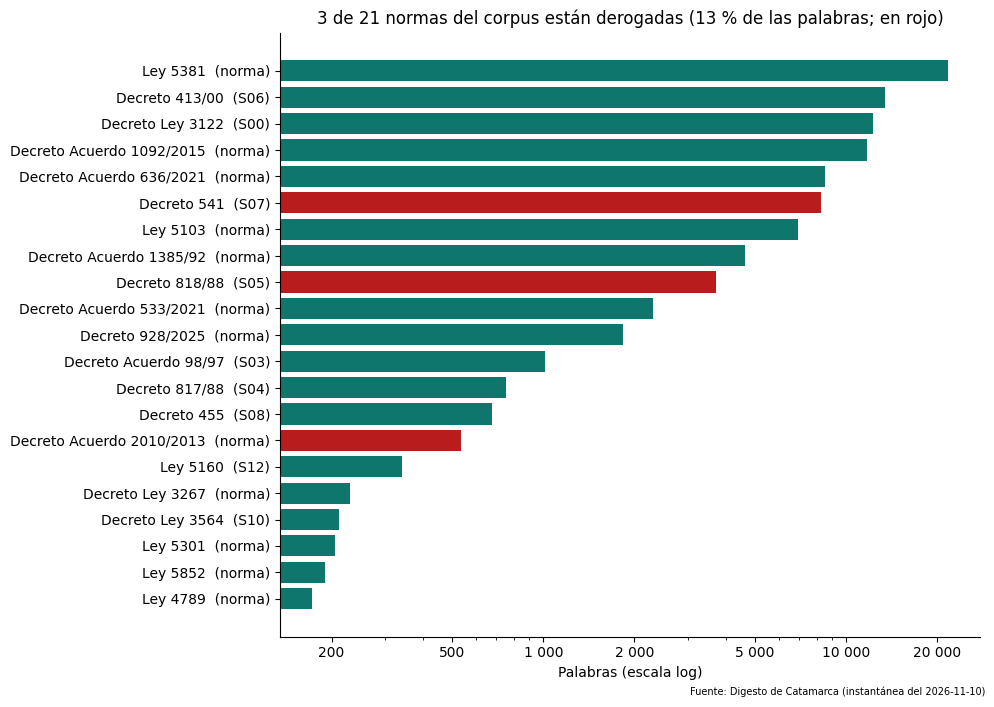

Hallazgo: 3 normas del corpus están derogadas (12.6 % de las palabras).
Decisión: conservar las derogadas con su estado, para que el sistema pueda excluirlas al responder.


In [23]:
# 6) Figura: palabras por norma del corpus deduplicado, según su estado
orden = df_dedup.sort_values("palabras")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(orden["norma_id"] + "  (" + orden["origen"].str.replace("compilado, segmento ", "", regex=False) + ")",
        orden["palabras"], color=np.where(orden["estado"] == "Derogado", "#b91c1c", "#0f766e"))
ax.set_xscale("log")
ax.set_xlabel("Palabras (escala log)")
n_der = int((df_dedup["estado"] == "Derogado").sum())
pct_der = 100 * df_dedup.loc[df_dedup["estado"] == "Derogado", "palabras"].sum() / df_dedup["palabras"].sum()
ax.set_title(f"{n_der} de {len(df_dedup)} normas del corpus están derogadas ({pct_der:.0f} % de las palabras; en rojo)")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.99, 0.0, FUENTE, ha="right", fontsize=7)
numeros_comunes(ax.xaxis)
plt.tight_layout()
plt.savefig(FIGS / "eda_vigencia.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Hallazgo: {n_der} normas del corpus están derogadas ({pct_der:.1f} % de las palabras).")
print("Decisión: conservar las derogadas con su estado, para que el sistema pueda excluirlas al responder.")

#### Gráfico 4 (principal) — Copias y normas parecidas

- **Variables:** similitud coseno TF-IDF de cada par de textos (numérica continua, de 0 a 1) y si el par es la misma norma (binaria).
- **Pregunta:** ¿alcanza la similitud para saber si dos textos son la misma norma?
- **Gráfico:** barras horizontales ordenadas, en verde los pares que son la misma norma y en rojo los pares más parecidos que son normas distintas, con una línea en 0,90.
- **Por qué:** son pocos pares; las barras ordenadas los comparan mejor que un mapa de calor de todos contra todos.
- **Hallazgo:** dos normas distintas (636/2021 y 818/88, 0,79) se parecen más que una copia (Ley 5103, 0,65).
- **…y por eso decidimos:** identificar los duplicados por número de norma; la similitud solo confirma.

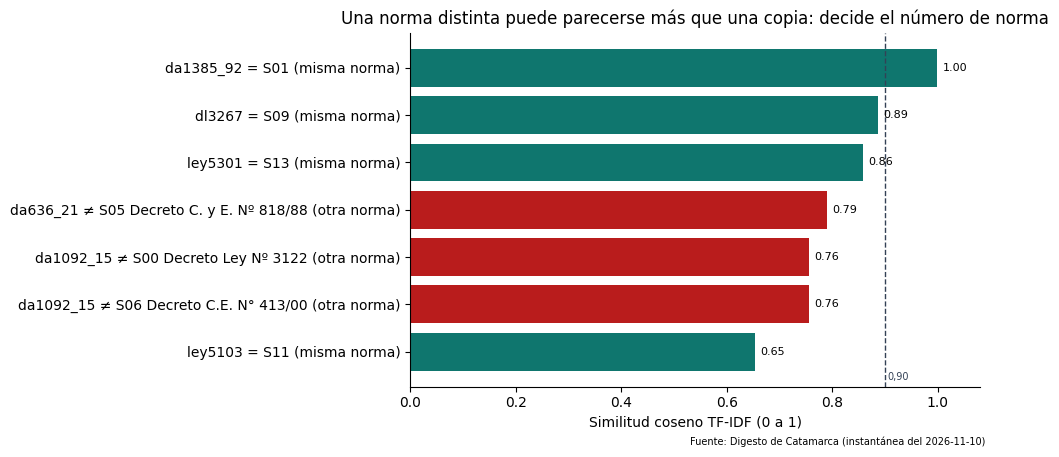

Hallazgo: el par de normas distintas más parecido da 0.79; la copia menos parecida, 0.65.
Hallazgo: el compilado reúne 14 normas; 4 también se descargan aparte; 9 se indexan desde el compilado.
Decisión: indexar cada texto una sola vez (corpus_dedup.jsonl), con su estado, para que el sistema pueda excluir lo derogado al responder.


In [24]:
# 7) Figura: los pares que son la misma norma frente a los pares más parecidos que son normas distintas
pares = [(f"{d} = S{v['segmentos'][0]:02d} (misma norma)", float(v["coseno"]), True) for d, v in asociacion.items()]
otros = sorted(((float(sim_seg[r, c]), d, c) for r, d in enumerate(individuales) for c in range(len(segmentos))
                if duplicados.get(c) != d), reverse=True)[:3]
pares += [(f"{d} ≠ S{c:02d} {encabezados[c]} (otra norma)", round(v, 3), False) for v, d, c in otros]
pares.sort(key=lambda p: p[1])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh([p[0] for p in pares], [p[1] for p in pares], color=["#0f766e" if p[2] else "#b91c1c" for p in pares])
for y, p in enumerate(pares):
    ax.text(p[1] + 0.01, y, f"{p[1]:.2f}", va="center", fontsize=8)
ax.axvline(0.90, color="#334155", linestyle="--", linewidth=1)
ax.text(0.905, -0.6, "0,90", fontsize=7, color="#334155")
ax.set_xlim(0, 1.08)
ax.set_xlabel("Similitud coseno TF-IDF (0 a 1)")
max_otro, min_par = max(p[1] for p in pares if not p[2]), min(p[1] for p in pares if p[2])
ax.set_title("Una norma distinta puede parecerse más que una copia: decide el número de norma" if max_otro > min_par
             else "Las copias se separan de las demás normas")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.99, 0.0, FUENTE, ha="right", fontsize=7)
plt.tight_layout()
plt.savefig(FIGS / "eda_dedup_coseno.png", dpi=200, bbox_inches="tight")
plt.show()

n_dup = len(asociacion)
print(f"Hallazgo: el par de normas distintas más parecido da {max_otro:.2f}; la copia menos parecida, {min_par:.2f}.")
print(f"Hallazgo: el compilado reúne {len(segmentos)} normas; {n_dup} también se descargan aparte; "
      f"{int(mapa['se_indexa_desde_compilado'].sum())} se indexan desde el compilado.")
print("Decisión: indexar cada texto una sola vez (corpus_dedup.jsonl), con su estado, para que el sistema "
      "pueda excluir lo derogado al responder.")

### 5c. Antes y después de la limpieza, vocabulario y costo

Cuatro preguntas más: cuánto texto sacó la limpieza y si saca lo mismo en HTML y en PDF, si cambió
el vocabulario, cuánto se achica el vocabulario al llevar las palabras a su raíz y cuánto costaría
que un modelo de lenguaje pago lea el corpus.

![Flujo de la sección 5c](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_a/diagramas/fig28_flujo_5c.png)

#### Gráfico 5 (de apoyo) — Antes y después de la limpieza

- **Variables:** caracteres y tokens por norma antes y después de limpiar (numéricas discretas), porcentaje quitado (numérica continua) y formato (binaria: HTML o PDF).
- **Pregunta:** ¿la limpieza saca lo mismo en las páginas HTML que en los PDF, o hay un formato donde saca de más?
- **Gráfico:** a la izquierda, barras con el porcentaje de caracteres quitados por norma y la media; a la derecha, tokens antes y después en barras pareadas (escala logarítmica). El color indica el formato.
- **Por qué:** compara cantidades entre categorías (las normas), y el color agrega la variable binaria.
- **Hallazgo:** la limpieza quita el 1,7 % de los tokens. En HTML quita entre el 1,1 % y el 3,5 % de los caracteres (sobre todo espacios repetidos); en PDF, entre el 0,2 % y el 23,9 %. Los porcentajes altos son los PDF más cortos (Leyes 4789 y 5852, de una página, y Decreto Acuerdo 2010/2013), donde el encabezado y el pie pesan más. Lo que se pierde fuera del encabezado y el pie no pasa del 0,08 %.
- **…y por eso decidimos:** el mismo criterio de limpieza para los dos formatos, controlando la pérdida que queda fuera del encabezado y el pie (≤ 5 %), no el porcentaje total.

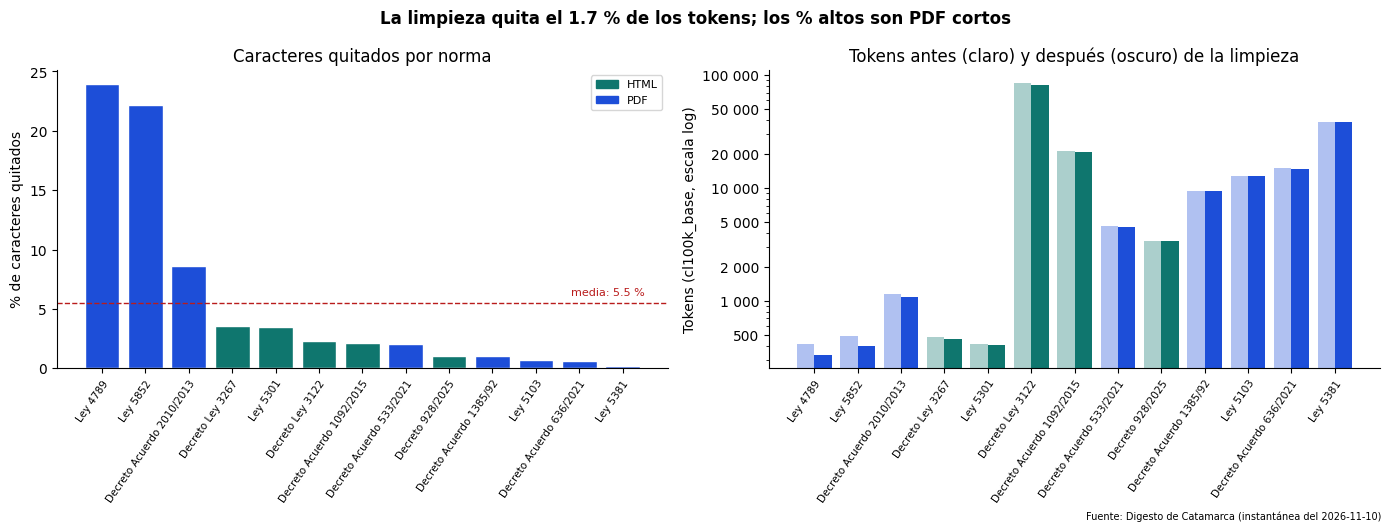

Tokens: 192800 antes y 189582 después (1.7 % menos).
Hallazgo: en HTML se quita entre 1.1 % y 3.5 % de los caracteres; en PDF, entre 0.2 % y 23.9 %. Lo que se pierde fuera del encabezado y el pie no pasa del 0.08 %.
Decisión: el mismo criterio de limpieza para los dos formatos, controlando la pérdida que queda fuera del encabezado y el pie (≤ 5 %), no el porcentaje total.

Ejemplo: Ley 4789 (PDF), primeros 280 caracteres
ANTES:   'Gobierno de Catamarca\nAsesoría General de Gobierno\nLey N° 4789 - Decreto Nº 1179\nCOMPLEMENTASE EL ART. 28 DE LA LEY Nº 3122\nESTATUTO PARA EL PERSONAL DOCENTE\nEL SENADO Y LA CAMARA DE DIPUTADOS\nDE LA PROVINCIA DE CATAMARCA\nSANCIONAN CON FUERZA DE\nLEY:\nARTICULO 1.- Compleméntese el'
DESPUÉS: 'Ley N° 4789 - Decreto Nº 1179\nCOMPLEMENTASE EL ART. 28 DE LA LEY Nº 3122\nESTATUTO PARA EL PERSONAL DOCENTE\nEL SENADO Y LA CAMARA DE DIPUTADOS\nDE LA PROVINCIA DE CATAMARCA\nSANCIONAN CON FUERZA DE\nLEY:\nARTICULO 1.- Compleméntese el artículo 28 de la Ley N° 31

In [25]:
# Gráfico 5: caracteres quitados y tokens antes y después de la limpieza, según el formato
COLOR_FORMATO = {"html": "#0f766e", "pdf": "#1d4ed8"}
df_antes = df_clean[["doc_id", "chars_raw", "chars_clean", "pct_lost"]].merge(
    df_manifest[["doc_id", "norma_id", "formato"]], on="doc_id")
df_antes["pct_quitado"] = 100 * (df_antes["chars_raw"] - df_antes["chars_clean"]) / df_antes["chars_raw"]
texto_extraido = {p["doc_id"]: "\n".join(pg["text"] for pg in p["pages"]) for p in corpus}
df_antes["tokens_antes"] = [len(enc.encode(texto_extraido[d])) for d in df_antes["doc_id"]]
df_antes = df_antes.merge(df_eda[["doc_id", "tokens"]].rename(columns={"tokens": "tokens_despues"}), on="doc_id")
df_antes = df_antes.sort_values("pct_quitado", ascending=False).reset_index(drop=True)
pct_tokens = 100 * (1 - df_antes["tokens_despues"].sum() / df_antes["tokens_antes"].sum())
colores = df_antes["formato"].map(COLOR_FORMATO)
nombres = df_antes["norma_id"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].bar(nombres, df_antes["pct_quitado"], color=colores, edgecolor="white")
axes[0].axhline(df_antes["pct_quitado"].mean(), color="#b91c1c", linestyle="--", linewidth=1)
axes[0].text(len(df_antes) - 0.5, df_antes["pct_quitado"].mean() + 0.6,
             f"media: {df_antes['pct_quitado'].mean():.1f} %", color="#b91c1c", ha="right", fontsize=8)
axes[0].set_ylabel("% de caracteres quitados")
axes[0].set_title("Caracteres quitados por norma")
x = np.arange(len(df_antes))
axes[1].bar(x - 0.2, df_antes["tokens_antes"], 0.4, color=colores, alpha=0.35, label="antes")
axes[1].bar(x + 0.2, df_antes["tokens_despues"], 0.4, color=colores, label="después")
axes[1].set_xticks(x, nombres)
axes[1].set_yscale("log")
axes[1].set_ylabel("Tokens (cl100k_base, escala log)")
axes[1].set_title("Tokens antes (claro) y después (oscuro) de la limpieza")
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=55, ha="right", rotation_mode="anchor", fontsize=7.5)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR_FORMATO.values()],
               labels=["HTML", "PDF"], fontsize=8, loc="upper right")
fig.suptitle(f"La limpieza quita el {pct_tokens:.1f} % de los tokens; los % altos son PDF cortos", fontweight="bold")
fig.text(0.99, 0.0, FUENTE, ha="right", fontsize=7)
numeros_comunes(axes[1].yaxis)
plt.tight_layout()
plt.savefig(FIGS / "eda_limpieza_antes_despues.png", dpi=200, bbox_inches="tight")
plt.show()

rango = df_antes.groupby("formato")["pct_quitado"].agg(["min", "max"]).round(1)
print(f"Tokens: {df_antes['tokens_antes'].sum()} antes y {df_antes['tokens_despues'].sum()} después ({pct_tokens:.1f} % menos).")
print(f"Hallazgo: en HTML se quita entre {rango.loc['html', 'min']} % y {rango.loc['html', 'max']} % de los caracteres; "
      f"en PDF, entre {rango.loc['pdf', 'min']} % y {rango.loc['pdf', 'max']} %. Lo que se pierde fuera del encabezado "
      f"y el pie no pasa del {df_antes['pct_lost'].max():.2f} %.")
print("Decisión: el mismo criterio de limpieza para los dos formatos, controlando la pérdida que queda fuera del "
      "encabezado y el pie (≤ 5 %), no el porcentaje total.")

corta = df_antes.iloc[0]
print(f"\nEjemplo: {corta['norma_id']} ({corta['formato'].upper()}), primeros 280 caracteres")
print("ANTES:  ", repr(texto_extraido[corta["doc_id"]][:280]))
print("DESPUÉS:", repr((CLEAN / f"{corta['doc_id']}.txt").read_text(encoding="utf-8")[:280]))

#### Riqueza del vocabulario antes y después de la limpieza

¿La limpieza cambió el vocabulario? Se calculan el TTR y el MATTR de la sección 5.5 sobre el texto
extraído (antes) y sobre el texto limpio (después).

In [26]:
riqueza_rows = []
for payload in corpus:
    antes = texto_extraido[payload["doc_id"]]
    despues = (CLEAN / f"{payload['doc_id']}.txt").read_text(encoding="utf-8")
    riqueza_rows.append({"doc_id": payload["doc_id"], "formato": payload["formato"],
                         "ttr_antes": round(ttr(antes), 3), "ttr_despues": round(ttr(despues), 3),
                         "mattr_antes": round(ttr(antes, 50), 3), "mattr_despues": round(ttr(despues, 50), 3)})
df_riqueza = pd.DataFrame(riqueza_rows)
df_riqueza.to_csv(ART / "riqueza_antes_despues.csv", index=False)
cambio_mattr = (df_riqueza["mattr_despues"] - df_riqueza["mattr_antes"]).abs().max()
print(f"Hallazgo: el MATTR cambia como máximo {cambio_mattr:.3f} entre antes y después: "
      "la limpieza saca encabezados y pies, no vocabulario de las normas.")
print("Decisión: medir la riqueza del vocabulario sobre el texto limpio; la limpieza no cambia las conclusiones de 5.5.")
df_riqueza

Hallazgo: el MATTR cambia como máximo 0.006 entre antes y después: la limpieza saca encabezados y pies, no vocabulario de las normas.
Decisión: medir la riqueza del vocabulario sobre el texto limpio; la limpieza no cambia las conclusiones de 5.5.


,doc_id,formato,ttr_antes,ttr_despues,mattr_antes,mattr_despues
0,d928_25,html,0.244,0.244,0.742,0.742
1,da1092_15,html,0.170,0.170,0.760,0.760
2,da1385_92,pdf,0.220,0.219,0.710,0.709
3,da2010_13,pdf,0.359,0.357,0.686,0.682
4,da533_21,pdf,0.278,0.279,0.756,0.755
5,da636_21,pdf,0.141,0.140,0.737,0.737
6,dl3267,html,0.582,0.582,0.769,0.769
7,estatuto_dl3122,html,0.105,0.105,0.750,0.750
8,ley4789,pdf,0.551,0.540,0.735,0.741
9,ley5103,pdf,0.201,0.200,0.748,0.748


#### Reducción de las palabras a su raíz

¿Cuánto se achica el vocabulario si cada palabra se lleva a su raíz (por ejemplo, “otorga”,
“otorgado” y “otorgamiento” pasan a “otorg”)? Se usa el reductor del español de NLTK (Snowball).

In [27]:
stemmer = SnowballStemmer("spanish")
vocabulario = set(palabras(corpus_all_text))
por_raiz = defaultdict(set)
for w in vocabulario:
    por_raiz[stemmer.stem(w)].add(w)
reduccion = 100 * (1 - len(por_raiz) / len(vocabulario))
ejemplos_raiz = sorted(por_raiz.items(), key=lambda x: (-len(x[1]), x[0]))[:5]
tabla_raices = pd.DataFrame([{"raíz": r, "palabras distintas": len(ws), "algunas": ", ".join(sorted(ws)[:6])}
                             for r, ws in ejemplos_raiz])
print(f"Hallazgo: las {len(vocabulario)} palabras distintas del corpus se reducen a {len(por_raiz)} raíces "
      f"({reduccion:.0f} % menos).")
print("Decisión: usar la reducción a la raíz solo en la búsqueda por palabras (BM25), para que “otorga” encuentre "
      "“otorgamiento”; no aplicarla al texto que se guarda ni antes de los embeddings.")
tabla_raices

Hallazgo: las 7095 palabras distintas del corpus se reducen a 3403 raíces (52 % menos).
Decisión: usar la reducción a la raíz solo en la búsqueda por palabras (BM25), para que “otorga” encuentre “otorgamiento”; no aplicarla al texto que se guarda ni antes de los embeddings.


,raíz,palabras distintas,algunas
0,aplic,19,"aplica, aplicabilidad, aplicable, aplicables, ..."
1,indic,19,"indica, indicaciones, indicación, indicada, in..."
2,continu,18,"continua, continuación, continuada, continuado..."
3,integr,17,"integración, integrada, integradas, integrado,..."
4,consider,16,"considera, consideración, considerada, conside..."


#### Costo en tokens

¿Cuánto costaría que un modelo de lenguaje pago lea el corpus o responda consultas? Se toma el precio
publicado de un modelo económico (DeepSeek, opción considerada para generar las respuestas). Los
tokens se cuentan con `cl100k_base` y cada modelo cuenta algo distinto, así que las cifras son
aproximadas. Los embeddings con un modelo abierto se calculan en Colab y no se pagan por token.

In [28]:
# Precio de referencia en USD por millón de tokens: DeepSeek, modelo flash, horario pico (el más caro).
# Fuente: https://api-docs.deepseek.com/quick_start/pricing, consultada el 2026-11-12. Puede cambiar.
PRECIO_ENTRADA_USD, PRECIO_SALIDA_USD = 0.30, 1.20
ARTICULOS_POR_CONSULTA = 5   # artículos que se le pasan al modelo en cada pregunta (supuesto)
TOKENS_RESPUESTA = 300       # largo de una respuesta (supuesto)


def costo_usd(tokens_entrada: float, tokens_salida: float = 0) -> float:
    """Calcula el costo de una llamada al modelo con el precio de referencia.

    Args:
        tokens_entrada: tokens que lee el modelo.
        tokens_salida: tokens que escribe el modelo.

    Returns:
        El costo en dólares.
    """
    return (tokens_entrada * PRECIO_ENTRADA_USD + tokens_salida * PRECIO_SALIDA_USD) / 1_000_000


tokens_dedup = [len(enc.encode(r["text"])) for r in corpus_dedup]
tokens_total = sum(tokens_dedup)
tokens_vigente = sum(t for t, r in zip(tokens_dedup, corpus_dedup) if r["estado"] == "Vigente")
tokens_consulta = ARTICULOS_POR_CONSULTA * df_art_tok["tokens"].mean()
tabla_costo = pd.DataFrame([
    {"escenario": "Leer todo el corpus una vez", "tokens": tokens_total, "USD": costo_usd(tokens_total)},
    {"escenario": "Leer solo lo vigente una vez", "tokens": tokens_vigente, "USD": costo_usd(tokens_vigente)},
    {"escenario": "Corpus 10 veces más grande, una vez", "tokens": 10 * tokens_total, "USD": costo_usd(10 * tokens_total)},
    {"escenario": f"1000 consultas ({ARTICULOS_POR_CONSULTA} artículos + respuesta de {TOKENS_RESPUESTA} tokens)",
     "tokens": round(1000 * (tokens_consulta + TOKENS_RESPUESTA)),
     "USD": costo_usd(1000 * tokens_consulta, 1000 * TOKENS_RESPUESTA)},
])
tabla_costo["USD"] = tabla_costo["USD"].round(3)
print(f"Hallazgo: leer todo el corpus deduplicado ({tokens_total} tokens) cuesta unos {costo_usd(tokens_total):.2f} USD; "
      f"1000 consultas, unos {tabla_costo['USD'].iloc[-1]:.2f} USD.")
print("Decisión: el costo no limita la prueba de concepto; como lo que más pesa son las consultas, cada consulta "
      "le pasa al modelo solo los artículos recuperados, no la norma entera.")
tabla_costo

Hallazgo: leer todo el corpus deduplicado (178351 tokens) cuesta unos 0.05 USD; 1000 consultas, unos 0.69 USD.
Decisión: el costo no limita la prueba de concepto; como lo que más pesa son las consultas, cada consulta le pasa al modelo solo los artículos recuperados, no la norma entera.


,escenario,tokens,USD
0,Leer todo el corpus una vez,178351,0.054
1,Leer solo lo vigente una vez,156668,0.047
2,"Corpus 10 veces más grande, una vez",1783510,0.535
3,1000 consultas (5 artículos + respuesta de 300...,1414273,0.694


In [29]:
findings = pd.DataFrame([
    {
        "hallazgo": f"{int((df_eda['tokens'] > 512).sum())} de {len(df_eda)} documentos superan 512 tokens de referencia.",
        "decision": "Aplicar chunking por estructura legal y medir con el tokenizador del modelo de embeddings.",
    },
    {
        "hallazgo": f"{int((~df_text['sin_texto']).sum())} de {len(df_text)} normas tienen texto extraíble ({int((df_text['formato'] == 'html').sum())} páginas HTML y {int((df_text['formato'] == 'pdf').sum())} PDF).",
        "decision": "Trabajar directamente con el texto extraído.",
    },
    {
        "hallazgo": f"{len(difieren)} norma(s) con un estado decidido distinto del de la ficha del Digesto.",
        "decision": "Guardar los dos campos (estado_digesto y estado) y usar el decidido para filtrar.",
    },
    {
        "hallazgo": f"{n_der} normas del corpus están derogadas ({pct_der:.1f} % de las palabras).",
        "decision": "Conservarlas con estado Derogado y excluirlas al responder.",
    },
    {
        "hallazgo": f"El documento con más artículos es {df_eda.sort_values('articles', ascending=False).iloc[0]['doc_id']}.",
        "decision": "Usar artículos, títulos y capítulos como separadores de chunk.",
    },
    {
        "hallazgo": f"{df_eda.iloc[0]['doc_id']} concentra el {df_eda.iloc[0]['pct_corpus']} % de los tokens.",
        "decision": "Estratificar las preguntas de evaluación y reportar métricas por documento para que el documento dominante no oculte fallas.",
    },
    {
        "hallazgo": f"Mediana de {df_art_tok['tokens'].median():.0f} tokens por artículo; "
                    f"{100 * (df_art_tok['tokens'] > 512).mean():.1f} % supera 512.",
        "decision": "Chunk por artículo y subdivisión solo de los artículos largos.",
    },
    {
        "hallazgo": f"El compilado ({HOST_ID}) reúne {len(segmentos)} normas; {n_dup} también se descargan aparte (identificadas por número).",
        "decision": "Limpieza de corpus: indexar los individuales y solo los segmentos no duplicados (corpus_dedup.jsonl).",
    },
    {
        "hallazgo": f"{int((df_art_tok['categoria'] == 'Requiere sub-chunking').sum())} artículos superan {UMBRAL_LARGO} tokens y "
                    f"{int((df_art_tok['categoria'] == 'Demasiado corto').sum())} tienen menos de {UMBRAL_CORTO}.",
        "decision": "Subdividir los artículos largos y agrupar los muy cortos con su contexto (título o capítulo).",
    },
    {
        "hallazgo": f"Las palabras vacías son el {df_sw['pct_vacias'].mean():.1f} % del texto.",
        "decision": "Quitarlas solo en el baseline léxico, conservando las negaciones; no antes de los embeddings.",
    },
    {
        "hallazgo": f"Frases de dominio frecuentes: {', '.join(NO_SEPARAR[:3])}.",
        "decision": "No cortar chunks dentro de estas frases.",
    },
    {
        "hallazgo": f"MATTR entre {df_ttr['mattr_50'].min():.2f} y {df_ttr['mattr_50'].max():.2f}; el TTR depende de la longitud.",
        "decision": "Comparar con MATTR; lematizar solo para el baseline léxico.",
    },
    {
        "hallazgo": f"{int(df_art_tok['modificado'].sum())} artículos tienen marca de modificación; DNI ocultos: {int(df_clean['dni_ocultos'].sum())}.",
        "decision": "Guardar la norma modificatoria y su fecha como metadato; no inferir vigencia automáticamente.",
    },
    {
        "hallazgo": f"La limpieza quita el {pct_tokens:.1f} % de los tokens; en PDF de una página llega al "
                    f"{df_antes['pct_quitado'].max():.0f} % de los caracteres (encabezado y pie).",
        "decision": "Mismo criterio de limpieza para HTML y PDF; controlar la pérdida fuera del encabezado y el pie.",
    },
    {
        "hallazgo": f"El MATTR cambia como máximo {cambio_mattr:.3f} entre antes y después de la limpieza.",
        "decision": "Medir la riqueza del vocabulario sobre el texto limpio.",
    },
    {
        "hallazgo": f"Llevar las palabras a su raíz reduce el vocabulario un {reduccion:.0f} %.",
        "decision": "Usarlo solo en la búsqueda por palabras (BM25), no antes de los embeddings.",
    },
    {
        "hallazgo": f"Leer el corpus cuesta unos {costo_usd(tokens_total):.2f} USD y 1000 consultas, unos "
                    f"{tabla_costo['USD'].iloc[-1]:.2f} USD (precio de referencia).",
        "decision": "Pasarle al modelo solo los artículos recuperados en cada consulta.",
    },
])
findings.to_csv(ART / "hallazgos_decisiones.csv", index=False)
findings

,hallazgo,decision
0,9 de 13 documentos superan 512 tokens de refer...,Aplicar chunking por estructura legal y medir ...
1,13 de 13 normas tienen texto extraíble (5 pági...,Trabajar directamente con el texto extraído.
2,4 norma(s) con un estado decidido distinto del...,Guardar los dos campos (estado_digesto y estad...
3,3 normas del corpus están derogadas (12.6 % de...,Conservarlas con estado Derogado y excluirlas ...
4,El documento con más artículos es estatuto_dl3...,"Usar artículos, títulos y capítulos como separ..."
5,estatuto_dl3122 concentra el 43.6 % de los tok...,Estratificar las preguntas de evaluación y rep...
6,Mediana de 108 tokens por artículo; 6.5 % supe...,Chunk por artículo y subdivisión solo de los a...
7,El compilado (estatuto_dl3122) reúne 14 normas...,Limpieza de corpus: indexar los individuales y...
8,22 artículos superan 800 tokens y 361 tienen m...,Subdividir los artículos largos y agrupar los ...
9,Las palabras vacías son el 42.8 % del texto.,"Quitarlas solo en el baseline léxico, conserva..."


## 6. Entidades (NER) con expresiones regulares

![Flujo de la extracción de entidades](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_a/diagramas/fig24_flujo_entidades.png)

Se buscan normas citadas, artículos, fechas, cargos, organismos, expedientes, modificaciones y
montos. Como el texto ya tiene los DNI ocultos, esos solo se cuentan. Se guarda una muestra para
revisarla a mano.

In [30]:
PATTERNS = {
    "NORMA": r"\b(?:LEY|DECRETO(?:\s+LEY|\s+ACUERDO|\s+C\.\s*y\s*E\.)?)\s+N[°º]?\s*[\d\./]+",
    "ARTICULO": r"\bART(?:[IÍ]CULO|\.)\s*\d+[°º]?(?:\s*,?\s*inc(?:iso|\.)\s*\w+\)?)?",
    "FECHA": r"\b\d{1,2}\s+de\s+[A-Za-zÁÉÍÓÚáéíóúñ]+\s+(?:de\s+)?\d\.?\d{3}\b|\b\d{1,2}/\d{1,2}/\d{2,4}\b",
    "MODIFICACION": r"Modificad[oa]\s+por:?\s*(?:Art\.?\s*\d+\.?\s*)?Ley\s+N?[°º]?\s*[\d\.]+(?:\s*\((?:B\.?\s*O\.?\s*)?[\d/\.\s]+\))?",
    "CARGO": r"\b(?:Vicedirector|Director|Supervisor|Secretario|Regente|Preceptor|Maestro|Profesor)(?:es|as|a)?\b(?:\s+(?:titular|interino|suplente)(?:s|es)?)?",
    "ORGANISMO": r"(?:Ministerio de|Consejo General|Juntas? de Clasificaci[oó]n|Comit[eé] Ejecutivo)[^\n,;\.]{0,80}",
    "DNI": r"D\.?\s*N\.?\s*I\.?\s*N?[°º]?\.?\s*[\dX\.]{6,}",  # en el texto limpio, los dígitos ya son X
    "EXPEDIENTE": r"Expediente\s+N[°º]?\s*[\w\-/\.]+",
    "MONTO": r"\$\s?[\d\.\,]+|\b\d[\d\.]*\s*(?:pesos|unidades tributarias|UT)\b",
}

MESES = {
    "enero": "01", "febrero": "02", "marzo": "03", "abril": "04",
    "mayo": "05", "junio": "06", "julio": "07", "agosto": "08",
    "septiembre": "09", "setiembre": "09", "octubre": "10",
    "noviembre": "11", "diciembre": "12",
}


def normalize_date(value: str) -> str:
    """Lleva una fecha al formato AAAA-MM-DD.

    Acepta “12 de marzo de 1.992” y “12/03/92”.

    Args:
        value: la fecha tal como aparece en el texto.

    Returns:
        La fecha normalizada, o el mismo texto si no la reconoce.
    """
    m = re.match(r"(\d{1,2})\s+de\s+([A-Za-zÁÉÍÓÚáéíóúñ]+)\s+(?:de\s+)?(\d\.?\d{3})", value, re.I)
    if m:
        day, month, year = m.groups()
        year = year.replace(".", "")
        mm = MESES.get(month.lower(), "00")
        return f"{year}-{mm}-{int(day):02d}"
    m = re.match(r"(\d{1,2})/(\d{1,2})/(\d{2,4})", value)
    if m:
        day, month, year = m.groups()
        year = f"20{year}" if len(year) == 2 else year
        return f"{year}-{int(month):02d}-{int(day):02d}"
    return value


def normalize_entity(kind: str, value: str) -> str:
    """Normaliza una entidad según su tipo.

    Args:
        kind: tipo de entidad (FECHA, DNI, NORMA…).
        value: el texto encontrado.

    Returns:
        El texto sin espacios repetidos; las fechas en AAAA-MM-DD y los DNI con X en lugar de dígitos.
    """
    v = re.sub(r"\s+", " ", value).strip()
    if kind == "FECHA":
        return normalize_date(v)
    if kind == "DNI":
        return re.sub(r"\d", "X", v)  # nunca se guarda un número de documento
    return v


def extract_entities(text: str, doc_id: str) -> list[dict]:
    """Busca en un texto todas las entidades de PATTERNS.

    Args:
        text: texto limpio de una norma.
        doc_id: identificador de la norma.

    Returns:
        Una lista con un diccionario por entidad: norma, tipo, texto, valor normalizado y posición.
    """
    rows = []
    for kind, pattern in PATTERNS.items():
        for m in re.finditer(pattern, text, re.I):
            rows.append({
                "doc_id": doc_id,
                "type": kind,
                "value": m.group(0),
                "normalized": normalize_entity(kind, m.group(0)),
                "start": m.start(),
                "end": m.end(),
            })
    return rows


entities = []
for payload in corpus:
    doc_id = payload["doc_id"]
    text = (CLEAN / f"{doc_id}.txt").read_text(encoding="utf-8")
    entities.extend(extract_entities(text, doc_id))

df_entities = pd.DataFrame(entities)
df_entities.to_csv(ART / "entities.csv", index=False)
df_entities.head(20)

,doc_id,type,value,normalized,start,end
0,d928_25,NORMA,DECRETO ACUERDO N° 636/2021,DECRETO ACUERDO N° 636/2021,141,168
1,d928_25,NORMA,Ley Nº 3.122,Ley Nº 3.122,1045,1057
2,d928_25,NORMA,Decreto Nº 884/2025,Decreto Nº 884/2025,1271,1290
3,d928_25,NORMA,Decreto Acuerdo N° 636,Decreto Acuerdo N° 636,2269,2291
4,d928_25,NORMA,Ley N° 5.893,Ley N° 5.893,2689,2701
5,d928_25,NORMA,Ley Nº 3.122,Ley Nº 3.122,4070,4082
6,d928_25,NORMA,Decreto Acuerdo N° 636,Decreto Acuerdo N° 636,5168,5190
7,d928_25,NORMA,Ley N° 5.893,Ley N° 5.893,5611,5623
8,d928_25,NORMA,Decreto Acuerdo N° 636/2021,Decreto Acuerdo N° 636/2021,7089,7116
9,d928_25,NORMA,Ley N° 5.893,Ley N° 5.893,8403,8415


¿Qué entidades aparecen lo suficiente como para usarlas como filtros de búsqueda? La tabla cuenta
las menciones (numérica discreta) por tipo de entidad (categórica nominal).

In [31]:
counts = df_entities.groupby("type").size().sort_values(ascending=False)
print(f"Hallazgo: domina {counts.index[0]} ({counts.iloc[0]} menciones); la menos frecuente es {counts.index[-1]} "
      f"({counts.iloc[-1]}); {df_entities.loc[df_entities['type'] == 'MODIFICACION', 'doc_id'].nunique()} norma(s) con modificaciones detectadas.")
print("Decisión: validar una muestra y filtrar falsos positivos antes de usar las entidades como metadatos.")
counts.rename("menciones").to_frame()

Hallazgo: domina ARTICULO (1143 menciones); la menos frecuente es EXPEDIENTE (4); 2 norma(s) con modificaciones detectadas.
Decisión: validar una muestra y filtrar falsos positivos antes de usar las entidades como metadatos.


,menciones
type,
ARTICULO,1143
CARGO,753
ORGANISMO,437
NORMA,183
FECHA,153
DNI,9
MODIFICACION,7
EXPEDIENTE,4


In [32]:
sample = df_entities.groupby("type", group_keys=False).head(5).copy()
sample["correcto"] = ""
sample.to_csv(ART / "entities_validation_sample.csv", index=False)
print("Muestra para validación manual guardada en artifacts/entities_validation_sample.csv")
sample

Muestra para validación manual guardada en artifacts/entities_validation_sample.csv


,doc_id,type,value,normalized,start,end,correcto
0,d928_25,NORMA,DECRETO ACUERDO N° 636/2021,DECRETO ACUERDO N° 636/2021,141,168,
1,d928_25,NORMA,Ley Nº 3.122,Ley Nº 3.122,1045,1057,
2,d928_25,NORMA,Decreto Nº 884/2025,Decreto Nº 884/2025,1271,1290,
3,d928_25,NORMA,Decreto Acuerdo N° 636,Decreto Acuerdo N° 636,2269,2291,
4,d928_25,NORMA,Ley N° 5.893,Ley N° 5.893,2689,2701,
11,d928_25,ARTICULO,Artículo 22°,Artículo 22°,990,1002,
12,d928_25,ARTICULO,artículo 40°,artículo 40°,2602,2614,
13,d928_25,ARTICULO,Artículo 22°,Artículo 22°,4015,4027,
14,d928_25,ARTICULO,artículo 40°,artículo 40°,5524,5536,
15,d928_25,ARTICULO,Artículo 149°,Artículo 149°,5851,5864,


## 7. Controles del corpus

![Flujo de los controles](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_a/diagramas/fig29_flujo_controles.png)

Se muestran dos registros del corpus, se comprueban sus cifras y se corren los controles automáticos
del corpus (todos tienen que dar `True`). Las secciones 8 a 12 parten de `corpus_dedup.jsonl` y de las variables ya calculadas.


**Cómo quedan los registros del corpus.** Dos registros de `corpus_dedup.jsonl`, el corpus sin
duplicados que se fragmenta en las secciones 8 y 9: una norma vigente y una derogada, con el texto recortado.


In [33]:
for estado in ["Vigente", "Derogado"]:
    registro = next(r for r in corpus_dedup if r["estado"] == estado)
    print(f"artifacts/corpus_dedup.jsonl, una norma con estado {estado}:")
    pprint(recortar(registro), sort_dicts=False, width=110)
    print()

artifacts/corpus_dedup.jsonl, una norma con estado Vigente:
{'doc_id': 'd928_25',
 'norma_id': 'Decreto 928/2025',
 'tipo': 'Decreto',
 'titulo': 'Decreto E.C.yT. - T.P. yR.H. N° 928 DERÓGASE EN TODAS SUS PARTES EL DECRETO E.C. Y T. - T.P. Y '
           'R.H. N° 884/2025. RESTABL',
 'estado': 'Vigente',
 'estado_digesto': 'Vigente',
 'fuente': 'Digesto Catamarca',
 'url_origen': 'https://digesto.catamarca.gob.ar/decreto/decreto_detail/5202',
 'relacion_3122': 'reglamenta',
 'articulo_3122': '',
 'origen': 'norma',
 'formato': 'html',
 'citable': True,
 'text': 'Decreto E.C.yT. - T.P. yR.H. N° 928\n'
         '\n'
         'DERÓGASE EN TODAS SUS PARTES EL DECRETO E.C. Y T. - T.P. Y R.H. N° 884/2025.\n'
         '\n'
         'RESTABLÉCESE VIGENCIA DEL DECRETO ACUERDO N° 636/2021\n'
         '\n'
         'San Fernando del Valle de Catamarca, 26 de Mayo de 2025.\n'
         '\n'
         'VISTO:\n'
         '\n'
         'El Expediente EX-2025-01044005-CAT-DPRHED#MTPRH y el Decreto E.C…

**Las cifras del corpus.** Los tamaños de los fragmentos (200 y 512 tokens) se decidieron con el EDA
de este corpus: 21 registros sin duplicados (normas y segmentos del compilado), 3 de ellos derogados,
con 178 351 tokens y 99 624 palabras. Si alguna cifra cambia sin que nadie lo haya decidido (por
ejemplo, un archivo dañado en la instantánea o otra versión de una librería), el notebook se
detiene antes de fragmentar, para no partir un corpus que el EDA no analizó.

Esto no impide ampliar el corpus: agregar normas es un paso deliberado. Se agrega la norma a la
instantánea, se corre el notebook, se revisa que las decisiones del EDA sigan valiendo (por
ejemplo, el largo de los artículos frente a 512 tokens) y se actualizan estas cuatro cifras.

In [34]:
CIFRAS_ESPERADAS = {
    "Registros del corpus sin duplicados": 21,
    "Registros derogados": 3,
    "Tokens del corpus sin duplicados": 178351,
    "Palabras del corpus sin duplicados": 99624,
}
cifras = {
    "Registros del corpus sin duplicados": len(corpus_dedup),
    "Registros derogados": sum(r["estado"] == "Derogado" for r in corpus_dedup),
    "Tokens del corpus sin duplicados": sum(len(enc.encode(r["text"])) for r in corpus_dedup),
    "Palabras del corpus sin duplicados": sum(len(r["text"].split()) for r in corpus_dedup),
}
df_cifras = pd.DataFrame({"esperado": CIFRAS_ESPERADAS, "obtenido": cifras})
df_cifras["coincide"] = df_cifras["esperado"] == df_cifras["obtenido"]
assert df_cifras["coincide"].all(), "El corpus no tiene las cifras esperadas:\n" + df_cifras.to_string()
print("Cifras del corpus como se esperaban: se puede fragmentar.")
df_cifras

Cifras del corpus como se esperaban: se puede fragmentar.


,esperado,obtenido,coincide
Registros del corpus sin duplicados,21,21,True
Registros derogados,3,3,True
Tokens del corpus sin duplicados,178351,178351,True
Palabras del corpus sin duplicados,99624,99624,True


In [35]:
# Ningún DNI con dígitos en los artefactos del corpus
DNI_DIGITOS = re.compile(r"\b(?:D\.?\s?N\.?\s?I\.?|M\.?\s?I\.?|L\.?\s?C\.?)\s*(?:N[°º]\.?|Nro\.?)?\s*:?\s*\d{1,2}\.?\d{3}\.?\d{3}\b", re.I)
artefactos_texto = list(CLEAN.glob("*.txt")) + [ART / "corpus_dedup.jsonl",
                                               ART / "entities.csv", ART / "entities_validation_sample.csv"]
con_dni = [p.name for p in artefactos_texto if DNI_DIGITOS.search(p.read_text(encoding="utf-8"))]
urls = df_manifest["url_origen"].tolist()

checks = {
    "13 normas de la instantánea con su SHA-256": len(df_manifest) == EXPECTED_DOCS and all(hash_inst.values()),
    "Título esperado en cada norma": bool(df_manifest["titulo_esperado"].all()),
    "Estado de la ficha leído en las 13 normas": bool(df_manifest["estado_digesto"].notna().all()),
    "Texto extraído en las 13 normas": not df_text["sin_texto"].any(),
    "Sin restos de la interfaz del sitio": int(df_text["restos_interfaz"].sum()) == 0,
    "Fuente: solo el Digesto": all(u.startswith(DIGESTO) for u in urls),
    "5 gráficos del EDA": len(list(FIGS.glob("eda_*.png"))) >= 5,
    "Riqueza léxica antes y después en las 13 normas": len(df_riqueza) == EXPECTED_DOCS,
    "Entidades extraídas": len(df_entities) > 0,
    "Pérdida de limpieza ≤ 5 %": bool((df_clean["pct_lost"] <= MAX_LOSS_PCT).all()),
    "Limpieza preserva negaciones, artículos y fechas": bool(df_clean["preserva_todo"].all()),
    "Ningún DNI con dígitos en los artefactos": not con_dni,
    "Compilado segmentado en normas": len(segmentos) >= 10,
    "Duplicados por número confirmados (coseno y cobertura)": not no_confirman and len(asociacion) >= 4,
    "818/88, 541/02 y 2010/2013 marcados como derogados": derogados_ok,
    "Metadatos de vigencia completos": metadatos_ok,
    "Mapa del compilado y corpus deduplicado": (ART / "mapa_compilado.csv").exists() and (ART / "corpus_dedup.jsonl").exists(),
    "Manifiesto con hashes": (ART / "manifest.csv").exists() and (ART / "manifest.json").exists(),
}
print("Artefactos con DNI:", con_dni or "ninguno")
pd.Series(checks)

Artefactos con DNI: ninguno


,0
13 normas de la instantánea con su SHA-256,True
Título esperado en cada norma,True
Estado de la ficha leído en las 13 normas,True
Texto extraído en las 13 normas,True
Sin restos de la interfaz del sitio,True
Fuente: solo el Digesto,True
5 gráficos del EDA,True
Riqueza léxica antes y después en las 13 normas,True
Entidades extraídas,True
Pérdida de limpieza ≤ 5 %,True


## 8. Fragmentos por artículo (estrategia E2)

![Flujo de los fragmentos por artículo (E2)](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_b/diagramas/fig36_flujo_e2.png)

Un modelo de lenguaje no puede leer una norma larga entera, y el buscador tiene que devolver el
pedazo que responde, no la norma completa. Por eso el corpus se parte en fragmentos. Se preparan
tres maneras de hacerlo, que después se comparan en la búsqueda; cada una cambia una sola cosa
respecto de la anterior:

| Estrategia | Cómo corta | Qué cambia respecto de la anterior | Sección |
|---|---|---|---|
| **E0** | Todas las normas en un solo texto, cortado en tramos de 200 tokens | Es el punto de partida: un fragmento puede mezclar dos normas | 9 |
| **E1** | Cada norma por separado, cortada en tramos de 200 tokens | Nunca mezcla normas | 9 |
| **E2** | Cada norma por separado, un artículo por fragmento | Respeta la estructura de la norma | 8 |

El tamaño se mide en tokens con el mismo codificador de la sección 5 (`cl100k_base`).

Reglas de E2, en orden:

1. **Cada norma** (o segmento del compilado) se fragmenta por separado: nunca se mezcla con otra.
2. **El cuerpo y cada anexo** se tratan por separado. Un anexo empieza en una línea “ANEXO …”.
3. **Un artículo por fragmento.** El artículo empieza en “ARTICULO n” o en la forma abreviada
   “Art. n°.-” que usan algunas normas del compilado. Las notas de modificación (“* Modificado
   por…”, “*Inciso b) abrogada…”) quedan al final de su artículo, porque el Digesto las pone ahí.
4. **El texto antes del primer artículo** (encabezado, VISTO y CONSIDERANDO) es su propio fragmento.
5. **Los títulos y capítulos** (“TITULO I — DISPOSICIONES GENERALES”) no quedan dentro de ningún
   artículo: pasan a ser el **contexto** de los fragmentos que siguen.
6. **Un anexo** es su propio fragmento, con su encabezado real como contexto. Si tiene artículos, se
   fragmenta por artículo; si tiene puntos numerados (“1.-”, “2.-”), cada punto es un fragmento.
7. **Un fragmento que supera 512 tokens** (contando el contexto) se divide por párrafo, por inciso
   y, si hace falta, por oración, con un 10 % de solapamiento. Cada parte se identifica como
   “ARTICULO n — parte k/m”. Una tabla se divide por filas y cada parte repite su encabezado.

Cada fragmento lleva los metadatos de su norma (identificador, tipo, estado de vigencia, estado en
el Digesto, fuente, URL, relación con el Estatuto, citabilidad) y los suyos: título y capítulo,
artículo o anexo, parte, contexto, tokens y página (solo en las normas en PDF). Un artículo
derogado por sí solo (“Artículo derogado por…”) lleva estado **Derogado** aunque su norma esté
vigente. Un inciso derogado dentro de un artículo vigente no cambia el estado del artículo: queda
anotado en `incisos_derogados`.


In [36]:
# Funciones de la fragmentación. Usan el codificador `enc` (sección 5) y el texto por página (TEXT).

MAX_TOKENS = 512          # límite por fragmento de E2, contando el contexto
SOLAPAMIENTO = 0.10       # al dividir un artículo largo, cada parte arranca con ~10 % del final de la anterior
TAM_FIJO = 200            # tamaño de los fragmentos de E0 y E1

# Encabezado de artículo al comienzo de línea: “ARTICULO 12.-”, “* ARTICULO 3.-” o la forma abreviada
# “Art. 4°.-”, que usan algunas normas del compilado. La abreviada exige la puntuación de encabezado,
# para no confundirla con una cita (“Art. 103 de la Ley…”).
ART_SPLIT = re.compile(r"(?m)^\*?[ \t]*(?:ART[IÍ]CULO\s+(\d+)|Art\.\s*(\d+)\s*[°º]?\s*(?:\.-|\.|:|-|–))")


def num_art(m) -> str:
    return m.group(1) or m.group(2)
# Encabezado de anexo: una línea corta que empieza con “ANEXO”
ANEXO_RE = re.compile(r"(?m)^[ \t]*ANEXO\b[^\n]{0,60}$")
# Encabezados de título, capítulo o sección: una línea corta (“TITULO VII”, “CAPÍTULO II”)
HEAD_RE = re.compile(r"(?m)^[ \t]*(?:T[IÍ]TULO|CAP[IÍ]TULO|SECCI[OÓ]N)\s+[IVXLCDM\d]+\b[^\n]{0,80}$", re.I)
# Puntos numerados de un anexo: “1.-”, “12.-” o “3-”
PUNTO_RE = re.compile(r"(?m)^[ \t]*(\d{1,3})\s*\.?-\s")
# Inciso al comienzo de línea: “a)”, “b)”, “12)”, “iv)”
INCISO_RE = re.compile(r"(?m)^[ \t]*\*?\s*(?:[a-zñ]|\d{1,2}|[ivx]{1,4})\)\s")
# Artículo derogado entero: su cuerpo es solo la nota (“Artículo derogado por…”, “Derogado por…”)
DEROGADO_RE = re.compile(r"^\W*(?:Art[ií]culo\s+)?derogad[oa]\b", re.I)
# Inciso derogado dentro de un artículo vigente: “*d) Derogado por…”
INCISO_DEROGADO_RE = re.compile(r"(?mi)^[ \t]*\*?\s*([a-zñ]|\d{1,2})\)\s*derogad[oa]\b")


def ntok(t: str) -> int:
    """Tokens de un texto con el codificador de la sección 5 (cl100k_base)."""
    return len(enc.encode(t))


def npal(t: str) -> int:
    return len(t.split())


def normaliza(t: str) -> str:
    """Mayúsculas, sin tildes y con un solo espacio: para buscar un fragmento en el texto de una página."""
    t = unicodedata.normalize("NFKD", t.upper())
    t = "".join(c for c in t if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", t).strip()


def separa_encabezados(cuerpo: str) -> tuple[str, str]:
    """Separa del final de una unidad los encabezados de título o capítulo que anuncian la unidad siguiente.

    Returns:
        (cuerpo sin los encabezados, bloque de encabezados; vacío si no hay).
    """
    m = HEAD_RE.search(cuerpo)
    if not m:
        return cuerpo, ""
    return cuerpo[:m.start()].rstrip(), cuerpo[m.start():].strip()


def actualiza_contexto(ctx: dict, bloque: str) -> None:
    """Actualiza el título y el capítulo vigentes con un bloque de encabezados.

    Un “TITULO” reinicia el capítulo; la línea que sigue a un encabezado es su nombre.
    """
    nivel = None
    for linea in [l.strip() for l in bloque.split("\n") if l.strip()]:
        if re.match(r"T[IÍ]TULO\b", linea, re.I):
            ctx["titulo"], ctx["capitulo"], nivel = linea, "", "titulo"
        elif re.match(r"(?:CAP[IÍ]TULO|SECCI[OÓ]N)\b", linea, re.I):
            ctx["capitulo"], nivel = linea, "capitulo"
        elif nivel:
            ctx[nivel] = f"{ctx[nivel]} — {linea}" if " — " not in ctx[nivel] else f"{ctx[nivel]} {linea}"


def texto_contexto(ctx: dict) -> str:
    return " > ".join(v for v in (ctx["anexo"], ctx["titulo"], ctx["capitulo"]) if v)


def unidades_menores(texto: str, limite: int) -> list[str]:
    """Parte un texto en unidades que entren en `limite` tokens: párrafo, inciso, oración y, como último recurso, palabras."""
    out = []
    for par in [p.strip() for p in re.split(r"\n\s*\n", texto) if p.strip()]:
        if ntok(par) <= limite:
            out.append(par)
            continue
        inicios = [m.start() for m in INCISO_RE.finditer(par)]
        trozos = [par[a:b].strip() for a, b in zip([0] + inicios, inicios + [len(par)]) if par[a:b].strip()] if inicios else [par]
        for tr in trozos:
            if ntok(tr) <= limite:
                out.append(tr)
                continue
            for s in [s.strip() for s in re.split(r"(?<=[.;:])\s+", tr) if s.strip()]:
                if ntok(s) <= limite:
                    out.append(s)
                else:  # oración excepcionalmente larga: se corta por palabras
                    pal, actual = s.split(), []
                    for p in pal:
                        if actual and ntok(" ".join(actual + [p])) > limite:
                            out.append(" ".join(actual))
                            actual = []
                        actual.append(p)
                    if actual:
                        out.append(" ".join(actual))
    return out


def es_tabla(texto: str) -> bool:
    """Una tabla del Digesto llega como una celda por párrafo: muchos párrafos muy cortos."""
    pars = [p for p in re.split(r"\n\s*\n|\n", texto) if p.strip()]
    return len(pars) >= 20 and sum(npal(p) <= 4 for p in pars) / len(pars) >= 0.6


def divide(texto: str, contexto: str) -> list[tuple[str, int]]:
    """Divide un texto que, con su contexto, supera MAX_TOKENS.

    Returns:
        Lista de (parte, palabras nuevas): las palabras nuevas excluyen el solapamiento y el encabezado
        repetido de una tabla, para controlar la conservación.
    """
    limite = MAX_TOKENS - ntok(contexto + "\n") if contexto else MAX_TOKENS
    if ntok(texto) <= limite:
        return [(texto, npal(texto))]
    cabecera = ""
    if es_tabla(texto):  # cada parte repite el encabezado de la tabla (las celdas antes del primer número)
        celdas = [c.strip() for c in re.split(r"\n\s*\n|\n", texto) if c.strip()]
        k = next((i for i, c in enumerate(celdas) if re.fullmatch(r"[\d\.,\s]+", c)), 0)
        cab = celdas[:k] if 0 < k <= 8 else []
        if cab and ntok("\n".join(cab)) <= limite // 4:
            cabecera = "\n".join(cab)
            texto = "\n\n".join(celdas[k:])
            limite -= ntok(cabecera + "\n")
    us = unidades_menores(texto, limite)
    partes, actual, nuevas = [], [], 0
    for u in us:
        if actual and ntok("\n".join(actual + [u])) > limite:
            partes.append(("\n".join(actual), nuevas))
            cola, t = [], 0
            for prev in reversed(actual):
                t += ntok(prev)
                if t > limite * SOLAPAMIENTO:
                    break
                cola.insert(0, prev)
            while cola and ntok("\n".join(cola + [u])) > limite:
                cola.pop(0)
            actual, nuevas = cola, 0
        actual.append(u)
        nuevas += npal(u)
    if actual:
        partes.append(("\n".join(actual), nuevas))
    if cabecera:  # la cabecera cuenta como palabras nuevas solo en la primera parte
        partes = [(cabecera + "\n" + p, n + (npal(cabecera) if i == 0 else 0)) for i, (p, n) in enumerate(partes)]
    return partes


def zonas(texto: str) -> list[tuple[str, int, int]]:
    """Cuerpo de la norma y cada anexo, como (nombre del anexo o "", inicio, fin)."""
    anexos = list(ANEXO_RE.finditer(texto))
    if not anexos:
        return [("", 0, len(texto))]
    out = [("", 0, anexos[0].start())] if texto[:anexos[0].start()].strip() else []
    for k, m in enumerate(anexos):
        fin = anexos[k + 1].start() if k + 1 < len(anexos) else len(texto)
        out.append((m.group(0).strip(), m.start(), fin))
    return out


def unidades_de_zona(texto: str, anexo: str) -> list[tuple[str, str]]:
    """Unidades de una zona como (etiqueta, texto): preámbulo, artículos, puntos de un anexo o el anexo entero."""
    marcas = [(m.start(), f"ARTICULO {num_art(m)}") for m in ART_SPLIT.finditer(texto)]
    if not marcas and anexo:
        puntos = list(PUNTO_RE.finditer(texto))
        if len(puntos) >= 2:
            marcas = [(m.start(), f"PUNTO {m.group(1)}") for m in puntos]
    if not marcas:
        return [(anexo or "TEXTO COMPLETO", texto)]
    out = []
    if texto[:marcas[0][0]].strip():
        out.append((anexo or "PREÁMBULO", texto[:marcas[0][0]]))
    for k, (ini, etiqueta) in enumerate(marcas):
        fin = marcas[k + 1][0] if k + 1 < len(marcas) else len(texto)
        out.append((etiqueta, texto[ini:fin]))
    return out


def paginas_de(rec: dict) -> list[tuple[int, str]]:
    """Páginas normalizadas del PDF de una norma; vacío si la norma es HTML (sin página)."""
    if rec["formato"] != "pdf":
        return []
    pags = json.loads((TEXT / f"{rec['doc_id']}.json").read_text(encoding="utf-8"))["pages"]
    return [(p["page"], normaliza(p["text"])) for p in pags]


def pagina_de(cuerpo: str, paginas: list, desde: int | None) -> int | None:
    """Primera página, a partir de `desde`, que contiene las primeras palabras del fragmento."""
    if not paginas:
        return None
    clave = normaliza(" ".join(cuerpo.split()[:8]))
    for pg, t in paginas:
        if desde is not None and pg < desde:
            continue
        if clave and clave in t:
            return pg
    return desde


def fragmenta_e2(rec: dict) -> tuple[list[dict], dict]:
    """Fragmentos por estructura legal de una norma o segmento, y su control de conservación."""
    frags, paginas, pag = [], paginas_de(rec), None
    palabras_frag = 0
    for anexo, z0, z1 in zonas(rec["text"]):
        ctx = {"anexo": anexo, "titulo": "", "capitulo": ""}
        for etiqueta, bruto in unidades_de_zona(rec["text"][z0:z1], anexo):
            cuerpo, bloque = separa_encabezados(bruto.strip())
            # Encabezado de anexo: la línea “ANEXO …” y su nombre son el título del fragmento, no texto
            if anexo and etiqueta == anexo:
                lineas = [l for l in cuerpo.split("\n") if l.strip()]
                nombre = next((l.strip() for l in lineas[1:3] if npal(l) > 2), "")
                ctx["anexo"] = f"{anexo} — {nombre}" if nombre else anexo
            if cuerpo:
                contexto = texto_contexto(ctx)
                pag = pagina_de(cuerpo, paginas, pag)
                derogado = etiqueta.startswith("ARTICULO") and bool(DEROGADO_RE.match(ART_SPLIT.sub("", cuerpo, count=1).lstrip(" .-–:°º\n")))
                partes = divide(cuerpo, contexto)
                palabras_frag += sum(n for _, n in partes)  # palabras de las partes, sin el solapamiento
                for j, (parte, _) in enumerate(partes, 1):
                    frags.append({
                        "articulo": etiqueta,
                        "parte": f"{j}/{len(partes)}",
                        "anexo": anexo,
                        "titulo_seccion": ctx["titulo"],
                        "capitulo": ctx["capitulo"],
                        "contexto": contexto,
                        "texto": parte,
                        "pagina": pag,
                        "estado_articulo": "Derogado" if derogado else "",
                        "incisos_derogados": INCISO_DEROGADO_RE.findall(cuerpo),
                        "modificado": cuerpo.lstrip().startswith("*") or bool(re.search(r"(?mi)^\s*\*|Modificad[oa]\s+por", cuerpo)),
                    })
            if bloque:
                palabras_frag += npal(bloque)
                actualiza_contexto(ctx, bloque)
    return frags, {"doc_id": rec["doc_id"], "palabras_corpus": npal(rec["text"]), "palabras_fragmentos": palabras_frag}


def cortes_fijos(texto: str, tam: int = TAM_FIJO) -> list[tuple[int, int]]:
    """Cortes de `tam` tokens sin solapamiento, sin partir palabras: lista de (inicio, fin) en caracteres."""
    pal = list(re.finditer(r"\S+", texto))
    cortes, i = [], 0
    while i < len(pal):
        ini, j = pal[i].start(), i + 1
        # búsqueda por saltos: avanza mientras el tramo entre en `tam` tokens
        paso = 64
        while paso:
            if j + paso <= len(pal) and ntok(texto[ini:pal[j + paso - 1].end()]) <= tam:
                j += paso
            else:
                paso //= 2
        cortes.append((ini, pal[j - 1].end()))
        i = j
    return cortes


def spans_articulos(texto: str) -> list[tuple[int, int]]:
    ini = [m.start() for m in ART_SPLIT.finditer(texto)]
    return [(a, ini[k + 1] if k + 1 < len(ini) else len(texto)) for k, a in enumerate(ini)]


def corta_articulo(a: int, b: int, arts: list[tuple[int, int]]) -> bool:
    """El fragmento [a, b) corta un artículo si toma solo una parte de alguno."""
    return any(s < b and e > a and not (a <= s and e <= b) for s, e in arts)


In [37]:
# Fragmentación E2 de las 21 normas o segmentos, con los metadatos de cada norma
CAMPOS_NORMA = ["doc_id", "norma_id", "tipo", "estado_digesto", "fuente", "url_origen", "relacion_3122", "citable"]

fragmentos, control = [], []
for rec in corpus_dedup:
    frs, ctrl = fragmenta_e2(rec)
    for k, f in enumerate(frs, 1):
        etiqueta = re.sub(r"\W+", "", f["articulo"])[:24]
        estado_art = f.pop("estado_articulo")
        fragmentos.append({
            "fragment_id": f"{rec['doc_id']}#e2-{k:03d}-{etiqueta}",
            **{c: rec[c] for c in CAMPOS_NORMA},
            "estado": estado_art or rec["estado"],  # un artículo derogado por sí solo pasa a Derogado
            "estado_norma": rec["estado"],
            **f,
            "tokens": ntok((f["contexto"] + "\n" if f["contexto"] else "") + f["texto"]),
        })
    control.append(ctrl)

df_frag = pd.DataFrame(fragmentos)
df_ctrl = pd.DataFrame(control)

# Controles de E2
conservacion = 100 * (df_ctrl["palabras_fragmentos"].sum() - df_ctrl["palabras_corpus"].sum()) / df_ctrl["palabras_corpus"].sum()
enc_por_frag = df_frag["texto"].apply(lambda t: len(ART_SPLIT.findall(t)))
# Sin mezclar normas: el final de cada fragmento está en el texto de su propia norma
# (el final, porque las partes de una tabla empiezan con su encabezado repetido)
texto_de = {r["doc_id"]: re.sub(r"\s+", " ", r["text"]) for r in corpus_dedup}
de_su_norma = df_frag.apply(lambda f: re.sub(r"\s+", " ", f["texto"])[-80:] in texto_de[f["doc_id"]], axis=1)
pdf_ids = {r["doc_id"] for r in corpus_dedup if r["formato"] == "pdf"}
pagina_ok = bool(df_frag.loc[df_frag["doc_id"].isin(pdf_ids), "pagina"].notna().all()
                 and df_frag.loc[~df_frag["doc_id"].isin(pdf_ids), "pagina"].isna().all())
derogado_suelto = df_frag[(df_frag["estado"] == "Derogado") & (df_frag["estado_norma"] == "Vigente")]
divididos = df_frag[df_frag["parte"] != "1/1"]

print(f"E2: {len(df_frag)} fragmentos de {df_frag['doc_id'].nunique()} normas o segmentos | "
      f"máximo {df_frag['tokens'].max()} tokens | mediana {df_frag['tokens'].median():.0f}")
print(f"Artículos: {int((df_frag['articulo'].str.startswith('ARTICULO') & df_frag['parte'].str.startswith('1/')).sum())} | "
      f"puntos de anexo: {int(df_frag['articulo'].str.startswith('PUNTO').sum())} | "
      f"partes de fragmentos divididos: {len(divididos)} (de {divididos.groupby(['doc_id', 'articulo']).ngroups} unidades)")
print(f"Conservación de palabras: {conservacion:+.2f} % | con contexto: {100 * (df_frag['contexto'] != '').mean():.0f} %")
print("Artículos derogados por sí solos (norma vigente):", derogado_suelto[["norma_id", "articulo"]].values.tolist())
print("Incisos derogados dentro de artículos vigentes:",
      [(r.norma_id, r.articulo, r.incisos_derogados) for r in df_frag.itertuples() if r.incisos_derogados])

assert df_frag["tokens"].max() <= MAX_TOKENS, "Hay fragmentos por encima del límite de tokens"
assert (enc_por_frag <= 1).all(), "Hay fragmentos con más de un encabezado de artículo"
assert de_su_norma.all(), "Hay fragmentos cuyo texto no sale de su propia norma"
assert abs(conservacion) <= 2.0, f"La conservación de palabras ({conservacion:+.2f} %) supera el 2 %"
assert df_frag["fragment_id"].is_unique, "Hay identificadores de fragmento repetidos"
assert pagina_ok, "La página falta en un fragmento de PDF o aparece en uno de HTML"

# Un ejemplo: un artículo del Estatuto con su contexto
ejemplo = df_frag[(df_frag["doc_id"] == "estatuto_dl3122__S00") & (df_frag["articulo"] == "ARTICULO 3")].iloc[0]
print("\nEjemplo —", ejemplo["fragment_id"])
print("Contexto:", ejemplo["contexto"])
print("Texto:", ejemplo["texto"][:300], "…")
df_frag[["fragment_id", "norma_id", "articulo", "parte", "contexto", "estado", "pagina", "tokens"]].head(10)


E2: 1066 fragmentos de 21 normas o segmentos | máximo 512 tokens | mediana 152
Artículos: 860 | puntos de anexo: 58 | partes de fragmentos divididos: 191 (de 66 unidades)
Conservación de palabras: +0.00 % | con contexto: 81 %
Artículos derogados por sí solos (norma vigente): [['Decreto Ley 3122', 'ARTICULO 164']]
Incisos derogados dentro de artículos vigentes: [('Decreto Acuerdo 1385/92', 'ARTICULO 5', ['d'])]

Ejemplo — estatuto_dl3122__S00#e2-004-ARTICULO3
Contexto: TITULO I — DISPOSICIONES GENERALES > CAPITULO I — DEL PERSONAL DOCENTE
Texto: * ARTICULO 3.- El estado docente se adquiere desde el momento en que el agente se hace cargo de la función para la que fuera designado y comprende las siguientes categorías:

a) ACTIVA: corresponde a todo el personal que se desempeña en las funciones específicas que se mencionan en el artículo anter …


,fragment_id,norma_id,articulo,parte,contexto,estado,pagina,tokens
0,d928_25#e2-001-PREÁMBULO,Decreto 928/2025,PREÁMBULO,1/7,,Vigente,NaN,375
1,d928_25#e2-002-PREÁMBULO,Decreto 928/2025,PREÁMBULO,2/7,,Vigente,NaN,498
2,d928_25#e2-003-PREÁMBULO,Decreto 928/2025,PREÁMBULO,3/7,,Vigente,NaN,405
3,d928_25#e2-004-PREÁMBULO,Decreto 928/2025,PREÁMBULO,4/7,,Vigente,NaN,378
4,d928_25#e2-005-PREÁMBULO,Decreto 928/2025,PREÁMBULO,5/7,,Vigente,NaN,460
5,d928_25#e2-006-PREÁMBULO,Decreto 928/2025,PREÁMBULO,6/7,,Vigente,NaN,472
6,d928_25#e2-007-PREÁMBULO,Decreto 928/2025,PREÁMBULO,7/7,,Vigente,NaN,508
7,d928_25#e2-008-ARTICULO1,Decreto 928/2025,ARTICULO 1,1/1,,Vigente,NaN,48
8,d928_25#e2-009-ARTICULO2,Decreto 928/2025,ARTICULO 2,1/1,,Vigente,NaN,158
9,d928_25#e2-010-ARTICULO3,Decreto 928/2025,ARTICULO 3,1/1,,Vigente,NaN,39


### 8b. Entidades de cada fragmento

Cada fragmento lleva las entidades de su propio texto, con los mismos patrones y la misma
normalización de la sección 6. El “ARTICULO n” del propio encabezado no cuenta como cita a otro
artículo. Las entidades quedan marcadas como no validadas hasta revisar a mano la muestra de la
sección 6. Los DNI ya llegan ocultos desde la limpieza: se controla que ninguno tenga dígitos.


In [38]:
# Entidades del texto de cada fragmento, con los patrones de la sección 6
TIPOS_ENT = [t for t in PATTERNS if t != "DNI"]
for f in fragmentos:
    encabezado = ART_SPLIT.match(f["texto"])  # el “ARTICULO n” propio no es una cita a otro artículo
    agrupadas = {}
    for e in extract_entities(f["texto"], f["doc_id"]):
        if e["type"] == "DNI" or (e["type"] == "ARTICULO" and encabezado and e["start"] < encabezado.end()):
            continue
        valores = agrupadas.setdefault(e["type"], [])
        if e["normalized"] not in valores:
            valores.append(e["normalized"])
    f["entidades"] = agrupadas
    f["entidades_validadas"] = False

df_frag = pd.DataFrame(fragmentos)
with open(ART / "fragmentos_e2.jsonl", "w", encoding="utf-8") as fh:
    for f in fragmentos:
        fh.write(json.dumps(f, ensure_ascii=False) + "\n")

sin_dni_e2 = DNI_DIGITOS.search((ART / "fragmentos_e2.jsonl").read_text(encoding="utf-8")) is None
cob_ent = pd.Series({t: 100 * df_frag["entidades"].apply(lambda d: t in d).mean() for t in TIPOS_ENT}).sort_values(ascending=False)
con_alguna = 100 * df_frag["entidades"].apply(bool).mean()
print(f"El {con_alguna:.0f} % de los fragmentos tiene al menos una entidad | ningún DNI con dígitos: {sin_dni_e2}")
assert sin_dni_e2, "Quedó un DNI con dígitos en fragmentos_e2.jsonl"


El 52 % de los fragmentos tiene al menos una entidad | ningún DNI con dígitos: True


## 9. Fragmentos de tamaño fijo (estrategias E0 y E1)

![Flujo de los fragmentos fijos](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_b/diagramas/fig37_flujo_fijos.png)

Los tramos de 200 tokens no tienen solapamiento y no parten palabras. **E1** corta cada norma por
separado y conserva sus metadatos. **E0** corta todas las normas juntas, en el orden del corpus sin
duplicados; un tramo puede mezclar dos normas, así que no lleva metadatos de norma, solo su
posición en el texto. Para comparar con E2 se cuenta cuántos tramos mezclan normas y cuántos cortan
un artículo (toman solo una parte de él).


In [39]:
# E1: cada norma por separado, en tramos de 200 tokens
fijos_e1 = []
for rec in corpus_dedup:
    arts = spans_articulos(rec["text"])
    for k, (a, b) in enumerate(cortes_fijos(rec["text"]), 1):
        fijos_e1.append({
            "fragment_id": f"{rec['doc_id']}#e1-{k:03d}",
            **{c: rec[c] for c in CAMPOS_NORMA}, "estado": rec["estado"],
            "tokens": ntok(rec["text"][a:b]),
            "corta_articulo": corta_articulo(a, b, arts),
            "texto": rec["text"][a:b],
        })

# E0: todas las normas en un solo texto, en el orden del corpus deduplicado
SEP = "\n\n"
limites, arts_e0, partes_txt, pos = [], [], [], 0
for rec in corpus_dedup:
    limites.append((pos, pos + len(rec["text"]), rec["doc_id"]))
    arts_e0 += [(pos + s, pos + e) for s, e in spans_articulos(rec["text"])]
    partes_txt.append(rec["text"])
    pos += len(rec["text"]) + len(SEP)
corpus_unido = SEP.join(partes_txt)
fijos_e0 = []
for k, (a, b) in enumerate(cortes_fijos(corpus_unido), 1):
    normas = [d for s, e, d in limites if s < b and e > a]
    fijos_e0.append({
        "fragment_id": f"e0-{k:04d}", "inicio": a, "fin": b,
        "tokens": ntok(corpus_unido[a:b]),
        "mezcla_normas": len(normas) > 1,
        "corta_articulo": corta_articulo(a, b, arts_e0),
        "texto": corpus_unido[a:b],
    })

df_e1, df_e0 = pd.DataFrame(fijos_e1), pd.DataFrame(fijos_e0)
for nombre, filas in [("fragmentos_e1.jsonl", fijos_e1), ("fragmentos_e0.jsonl", fijos_e0)]:
    with open(ART / nombre, "w", encoding="utf-8") as fh:
        for f in filas:
            fh.write(json.dumps(f, ensure_ascii=False) + "\n")

e1_una_norma = bool(df_e1.apply(lambda f: f["texto"] in next(r["text"] for r in corpus_dedup if r["doc_id"] == f["doc_id"]), axis=1).all())
sin_dni_fijos = all(DNI_DIGITOS.search((ART / n).read_text(encoding="utf-8")) is None
                    for n in ["fragmentos_e1.jsonl", "fragmentos_e0.jsonl"])
print(f"E1: {len(df_e1)} tramos | máximo {df_e1['tokens'].max()} tokens | cortan un artículo: "
      f"{int(df_e1['corta_articulo'].sum())} ({100 * df_e1['corta_articulo'].mean():.0f} %)")
print(f"E0: {len(df_e0)} tramos | máximo {df_e0['tokens'].max()} tokens | mezclan normas: "
      f"{int(df_e0['mezcla_normas'].sum())} | cortan un artículo: {int(df_e0['corta_articulo'].sum())} "
      f"({100 * df_e0['corta_articulo'].mean():.0f} %)")
assert max(df_e1["tokens"].max(), df_e0["tokens"].max()) <= TAM_FIJO, "Hay tramos fijos por encima de 200 tokens"
assert e1_una_norma, "Hay tramos de E1 que mezclan normas"
assert sin_dni_fijos, "Quedó un DNI con dígitos en los tramos fijos"


E1: 904 tramos | máximo 200 tokens | cortan un artículo: 815 (90 %)
E0: 896 tramos | máximo 200 tokens | mezclan normas: 20 | cortan un artículo: 812 (91 %)


## 10. Análisis de los fragmentos

![Flujo del análisis de los fragmentos](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_b/diagramas/fig38_flujo_analisis_fragmentos.png)

Se comprueba que la fragmentación cumple lo que se decidió en el EDA del corpus: el tamaño de los
fragmentos, cómo se reparten entre normas y estados de vigencia, y cuánto rompen la estructura los
cortes de tamaño fijo. Cada gráfico termina en una decisión.


#### Gráfico 1 (principal) — Tamaño de los fragmentos

- **Variable:** tokens por fragmento de E2 (numérica discreta), contando el contexto.
- **Pregunta:** ¿los fragmentos por artículo entran en el límite, y qué tan distintos son de los tramos fijos de 200 tokens?
- **Gráfico:** histograma, con líneas en 200 (tamaño de E0 y E1), en 512 (límite de E2) y en la mediana.
- **Por qué:** muestra la distribución de una variable numérica. E0 y E1 no se dibujan: casi todos sus
  tramos tienen 200 tokens, así que se resumen en el título.


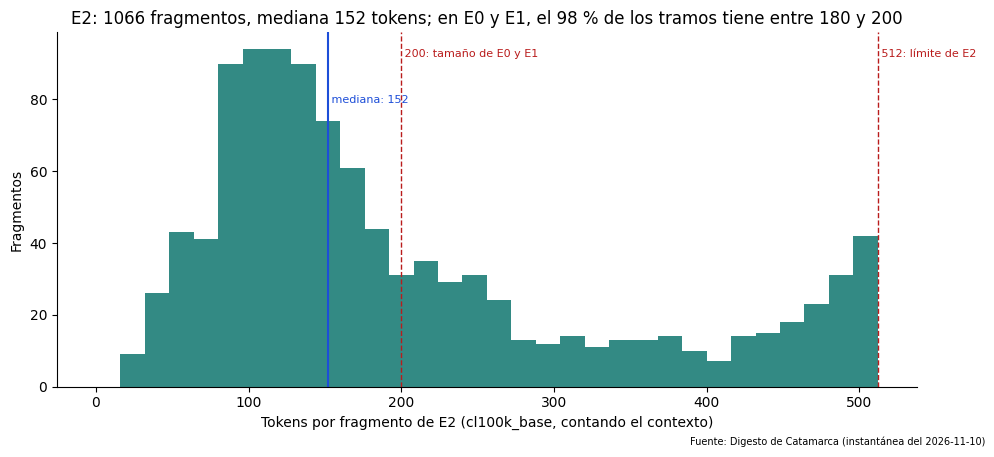

Hallazgo: los fragmentos de E2 tienen mediana 152 tokens y van de 19 a 512; 40 tienen menos de 50 y 69 quedan cerca del límite (son partes de artículos largos). En E0 y E1 casi todos los tramos tienen 200 tokens (98 % de E1 entre 180 y 200).
Decisión: mantener el artículo como unidad aunque haya fragmentos cortos, porque conservan su cita; su contexto (título y capítulo) va como metadato.


In [40]:
# Gráfico 1: tokens por fragmento de E2 (E0 y E1 se resumen en el título: casi todos tienen 200)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(df_frag["tokens"], bins=np.arange(0, MAX_TOKENS + 1, 16), color="#0f766e", alpha=0.85)
for x, txt in [(TAM_FIJO, "200: tamaño de E0 y E1"), (MAX_TOKENS, "512: límite de E2")]:
    ax.axvline(x, color="#b91c1c", linestyle="--", linewidth=1)
    ax.text(x, ax.get_ylim()[1] * 0.93, f" {txt}", color="#b91c1c", fontsize=8)
med = df_frag["tokens"].median()
ax.axvline(med, color="#1d4ed8", linewidth=1.5)
ax.text(med, ax.get_ylim()[1] * 0.80, f" mediana: {med:.0f}", color="#1d4ed8", fontsize=8)
ax.set_xlabel("Tokens por fragmento de E2 (cl100k_base, contando el contexto)")
ax.set_ylabel("Fragmentos")
pct_e1_lleno = 100 * (df_e1["tokens"] >= 180).mean()
ax.set_title(f"E2: {len(df_frag)} fragmentos, mediana {med:.0f} tokens; "
             f"en E0 y E1, el {pct_e1_lleno:.0f} % de los tramos tiene entre 180 y 200")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.99, 0.0, FUENTE, ha="right", fontsize=7)
plt.tight_layout()
plt.savefig(FIGS / "frag_tokens.png", dpi=200, bbox_inches="tight")
plt.show()

cortos = int((df_frag["tokens"] < 50).sum())
llenos = int((df_frag["tokens"] > MAX_TOKENS - 32).sum())
print(f"Hallazgo: los fragmentos de E2 tienen mediana {med:.0f} tokens y van de {df_frag['tokens'].min()} a "
      f"{df_frag['tokens'].max()}; {cortos} tienen menos de 50 y {llenos} quedan cerca del límite (son partes de "
      f"artículos largos). En E0 y E1 casi todos los tramos tienen 200 tokens ({pct_e1_lleno:.0f} % de E1 entre 180 y 200).")
print("Decisión: mantener el artículo como unidad aunque haya fragmentos cortos, porque conservan su cita; "
      "su contexto (título y capítulo) va como metadato.")


#### Gráfico 2 (principal) — Fragmentos por norma y por vigencia

- **Variables:** fragmentos de E2 por norma (numérica discreta) y estado (binaria: Vigente o Derogado).
- **Pregunta:** ¿cómo se reparten los fragmentos entre las normas, y cuántos son de normas o artículos derogados?
- **Gráfico:** barras horizontales apiladas, con lo derogado en rojo.
- **Por qué:** compara una cantidad entre categorías, y el color agrega el estado.


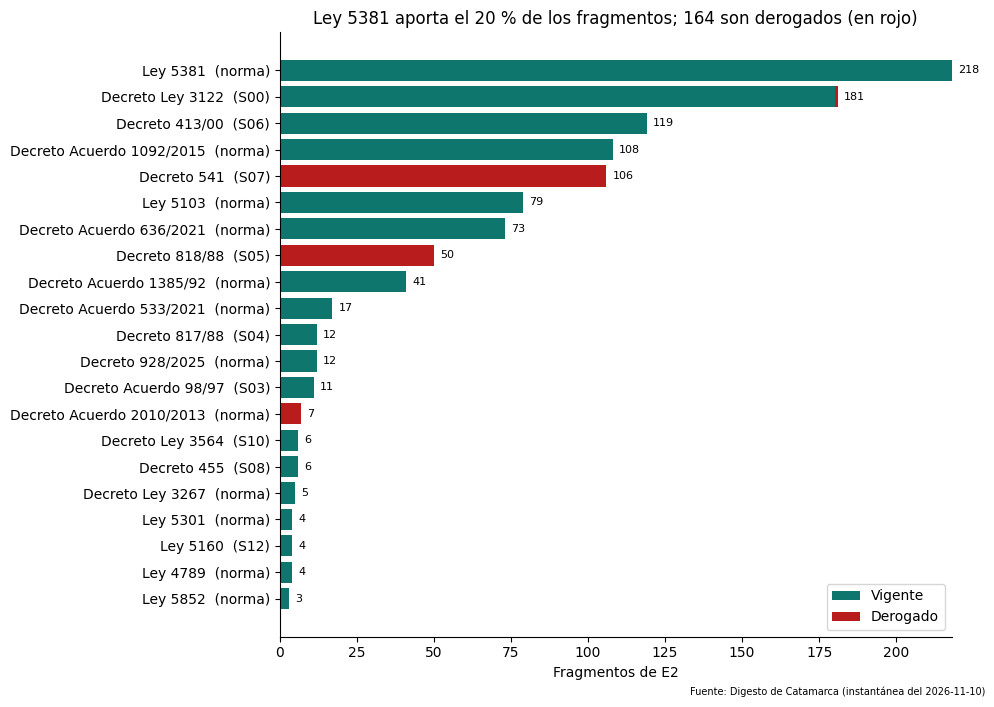

Hallazgo: Ley 5381 aporta el 20 % de los fragmentos y 5 normas o segmentos tienen 5 fragmentos o menos; 164 fragmentos (15 %) son derogados.
Decisión: armar las preguntas de evaluación por norma, para que las normas chicas también se midan, y medir la búsqueda con y sin el filtro de vigencia.


In [41]:
# Gráfico 2: fragmentos de E2 por norma, según su estado
tabla_estado = (df_frag.assign(etiqueta=df_frag["norma_id"] + "  (" + df_frag["doc_id"].str.extract(r"__(S\d+)", expand=False).fillna("norma") + ")")
                .pivot_table(index="etiqueta", columns="estado", values="fragment_id", aggfunc="count", fill_value=0)
                .reindex(columns=["Vigente", "Derogado"], fill_value=0))
tabla_estado = tabla_estado.loc[tabla_estado.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(tabla_estado.index, tabla_estado["Vigente"], color="#0f766e", label="Vigente")
ax.barh(tabla_estado.index, tabla_estado["Derogado"], left=tabla_estado["Vigente"], color="#b91c1c", label="Derogado")
for y, total in enumerate(tabla_estado.sum(axis=1)):
    ax.text(total + 2, y, str(total), va="center", fontsize=8)
n_der = int((df_frag["estado"] == "Derogado").sum())
mayor = tabla_estado.sum(axis=1).idxmax()
pct_mayor = 100 * tabla_estado.sum(axis=1).max() / len(df_frag)
ax.set_xlabel("Fragmentos de E2")
ax.set_title(f"{mayor.split('  (')[0]} aporta el {pct_mayor:.0f} % de los fragmentos; {n_der} son derogados (en rojo)")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.99, 0.0, FUENTE, ha="right", fontsize=7)
plt.tight_layout()
plt.savefig(FIGS / "frag_por_norma_y_estado.png", dpi=200, bbox_inches="tight")
plt.show()

chicas = int((tabla_estado.sum(axis=1) <= 5).sum())
print(f"Hallazgo: {mayor.split('  (')[0]} aporta el {pct_mayor:.0f} % de los fragmentos y {chicas} normas o segmentos "
      f"tienen 5 fragmentos o menos; {n_der} fragmentos ({100 * n_der / len(df_frag):.0f} %) son derogados.")
print("Decisión: armar las preguntas de evaluación por norma, para que las normas chicas también se midan, "
      "y medir la búsqueda con y sin el filtro de vigencia.")


#### Gráfico 3 (principal) — Cuánto rompen la estructura los cortes fijos

- **Variables:** proporción de fragmentos que cortan un artículo y que mezclan normas (numéricas) por estrategia (categórica).
- **Pregunta:** ¿cuánto rompen la estructura de las normas los tramos de 200 tokens?
- **Gráfico:** barras agrupadas por estrategia.
- **Por qué:** compara dos proporciones entre pocas categorías.


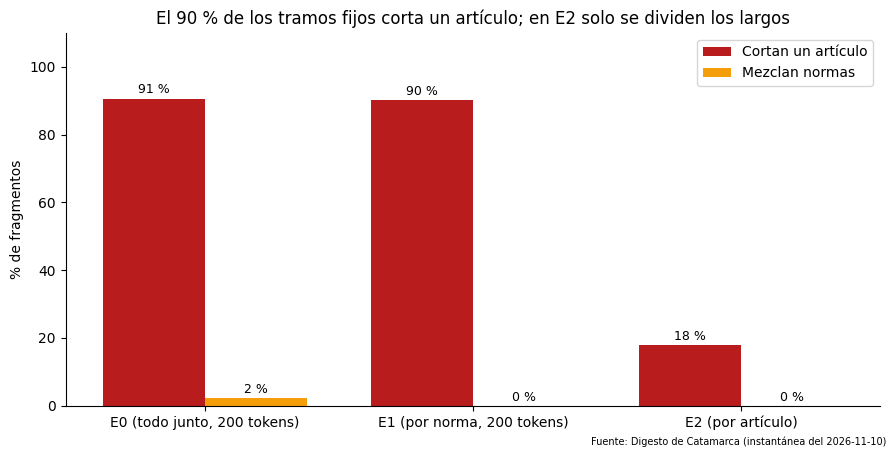

Hallazgo: el 91 % de los tramos de E0 y el 90 % de los de E1 cortan un artículo; 20 tramos de E0 mezclan dos normas. En E2, el 18 % de los fragmentos son partes de un artículo largo.
Decisión: comparar E0, E1 y E2 con el mismo conjunto de preguntas y el mismo buscador; la hipótesis es que cortar artículos y mezclar normas empeora la búsqueda y la cita.


In [42]:
# Gráfico 3: cuánto rompen la estructura los tramos fijos
rotura = pd.DataFrame({
    "Cortan un artículo": [100 * df_e0["corta_articulo"].mean(), 100 * df_e1["corta_articulo"].mean(),
                           100 * (df_frag["parte"] != "1/1").mean()],
    "Mezclan normas": [100 * df_e0["mezcla_normas"].mean(), 0.0, 0.0],
}, index=["E0", "E1", "E2"])
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(rotura))
for i, (col, color) in enumerate([("Cortan un artículo", "#b91c1c"), ("Mezclan normas", "#f59e0b")]):
    barras = ax.bar(x + (i - 0.5) * 0.38, rotura[col], width=0.38, color=color, label=col)
    for b, v in zip(barras, rotura[col]):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f} %", ha="center", fontsize=9)
ax.set_xticks(x, ["E0 (todo junto, 200 tokens)", "E1 (por norma, 200 tokens)", "E2 (por artículo)"])
ax.set_ylabel("% de fragmentos")
ax.set_ylim(0, 110)
ax.set_title(f"El {rotura.loc['E1', 'Cortan un artículo']:.0f} % de los tramos fijos corta un artículo; "
             f"en E2 solo se dividen los largos")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.99, 0.0, FUENTE, ha="right", fontsize=7)
plt.tight_layout()
plt.savefig(FIGS / "frag_cortes.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Hallazgo: el {rotura.loc['E0', 'Cortan un artículo']:.0f} % de los tramos de E0 y el "
      f"{rotura.loc['E1', 'Cortan un artículo']:.0f} % de los de E1 cortan un artículo; "
      f"{int(df_e0['mezcla_normas'].sum())} tramos de E0 mezclan dos normas. En E2, el "
      f"{rotura.loc['E2', 'Cortan un artículo']:.0f} % de los fragmentos son partes de un artículo largo.")
print("Decisión: comparar E0, E1 y E2 con el mismo conjunto de preguntas y el mismo buscador; "
      "la hipótesis es que cortar artículos y mezclar normas empeora la búsqueda y la cita.")


### 10b. Metadatos y entidades

Dos tablas: qué parte de los fragmentos de E2 tiene cada metadato y qué parte tiene cada tipo de
entidad. Después, la tabla de hallazgos y decisiones de los fragmentos (`hallazgos_fragmentos.csv`).


In [43]:
# Cobertura de metadatos y de entidades en E2
OBLIGATORIOS = ["fragment_id", "doc_id", "norma_id", "tipo", "estado", "estado_digesto", "fuente", "url_origen",
                "relacion_3122", "articulo", "parte", "texto", "tokens", "citable"]
OPCIONALES = ["titulo_seccion", "capitulo", "anexo", "contexto"]
con_valor = lambda c: df_frag[c].notna() & (df_frag[c].astype(str) != "")
df_cob = pd.DataFrame({
    "metadato": OBLIGATORIOS + OPCIONALES + ["pagina (solo PDF)"],
    "obligatorio": [True] * len(OBLIGATORIOS) + [False] * (len(OPCIONALES) + 1),
    "% de fragmentos con valor": [round(100 * con_valor(c).mean(), 1) for c in OBLIGATORIOS + OPCIONALES]
                                 + [round(100 * df_frag.loc[df_frag["doc_id"].isin(pdf_ids), "pagina"].notna().mean(), 1)],
})
metadatos_ok = bool(df_cob.loc[df_cob["obligatorio"], "% de fragmentos con valor"].eq(100).all())
display(df_cob)
display(cob_ent.round(1).rename("% de fragmentos con el tipo de entidad").to_frame())

hallazgos_frag = pd.DataFrame([
    {"hallazgo": f"E2: {len(df_frag)} fragmentos, mediana {df_frag['tokens'].median():.0f} tokens, máximo {df_frag['tokens'].max()}; {cortos} tienen menos de 50.",
     "decision": "El artículo es la unidad de E2; los largos se dividen con solapamiento y los cortos conservan su cita."},
    {"hallazgo": f"{mayor.split('  (')[0]} aporta el {pct_mayor:.0f} % de los fragmentos; {n_der} son derogados.",
     "decision": "Preguntas de evaluación por norma; búsqueda medida con y sin el filtro de vigencia."},
    {"hallazgo": f"Cortan un artículo: E0 {rotura.loc['E0', 'Cortan un artículo']:.0f} %, E1 {rotura.loc['E1', 'Cortan un artículo']:.0f} %; {int(df_e0['mezcla_normas'].sum())} tramos de E0 mezclan normas.",
     "decision": "Comparar E0, E1 y E2 con el mismo conjunto de preguntas y el mismo buscador."},
    {"hallazgo": f"Metadatos obligatorios completos: {metadatos_ok}; contexto en el {100 * con_valor('contexto').mean():.0f} % de los fragmentos.",
     "decision": "La cita usa norma y artículo siempre; título, capítulo y página cuando existen."},
    {"hallazgo": f"El {con_alguna:.0f} % de los fragmentos tiene al menos una entidad; la más frecuente es {cob_ent.idxmax()} ({cob_ent.max():.0f} %).",
     "decision": "Las entidades del fragmento quedan como metadatos, marcadas como no validadas hasta revisar la muestra."},
])
hallazgos_frag.to_csv(ART / "hallazgos_fragmentos.csv", index=False)
hallazgos_frag


,metadato,obligatorio,% de fragmentos con valor
0,fragment_id,True,100.0
1,doc_id,True,100.0
2,norma_id,True,100.0
3,tipo,True,100.0
4,estado,True,100.0
5,estado_digesto,True,100.0
6,fuente,True,100.0
7,url_origen,True,100.0
8,relacion_3122,True,100.0
9,articulo,True,100.0


,% de fragmentos con el tipo de entidad
ORGANISMO,27.6
CARGO,17.4
ARTICULO,14.9
NORMA,8.0
FECHA,6.5
MODIFICACION,0.7
EXPEDIENTE,0.3
MONTO,0.0


,hallazgo,decision
0,"E2: 1066 fragmentos, mediana 152 tokens, máxim...",El artículo es la unidad de E2; los largos se ...
1,Ley 5381 aporta el 20 % de los fragmentos; 164...,Preguntas de evaluación por norma; búsqueda me...
2,"Cortan un artículo: E0 91 %, E1 90 %; 20 tramo...","Comparar E0, E1 y E2 con el mismo conjunto de ..."
3,Metadatos obligatorios completos: True; contex...,"La cita usa norma y artículo siempre; título, ..."
4,El 52 % de los fragmentos tiene al menos una e...,Las entidades del fragmento quedan como metada...


## 11. Controles de la fragmentación

![Flujo de los controles de la fragmentación](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_b/diagramas/fig39_flujo_controles_fragmentos.png)

Todos tienen que dar `True`.


In [44]:
controles_frag = {
    "E2: ningún fragmento supera 512 tokens (con el contexto)": bool(df_frag["tokens"].max() <= MAX_TOKENS),
    "E2: un encabezado de artículo por fragmento como máximo": bool((enc_por_frag <= 1).all()),
    "E2: cada fragmento sale de su propia norma": bool(de_su_norma.all()),
    "E2: conservación de palabras ≤ 2 %": abs(conservacion) <= 2.0,
    "E2: identificadores únicos": bool(df_frag["fragment_id"].is_unique),
    "E2: metadatos obligatorios completos": metadatos_ok,
    "E2: página solo y siempre en los fragmentos de PDF": pagina_ok,
    "E2: artículo 164 del Estatuto derogado por sí solo": bool(((derogado_suelto["doc_id"] == "estatuto_dl3122__S00")
                                                             & (derogado_suelto["articulo"] == "ARTICULO 164")).any()),
    "E2: las normas derogadas tienen todos sus fragmentos derogados": bool(df_frag.loc[df_frag["estado_norma"] == "Derogado", "estado"].eq("Derogado").all()),
    "E2: entidades en cada fragmento, sin validar": bool(df_frag["entidades"].apply(lambda d: isinstance(d, dict)).all()
                                                       and not df_frag["entidades_validadas"].any()),
    "E0 y E1: tramos de 200 tokens como máximo": bool(max(df_e0["tokens"].max(), df_e1["tokens"].max()) <= TAM_FIJO),
    "E1: cada tramo sale de una sola norma": e1_una_norma,
    "Ningún DNI con dígitos en los fragmentos": sin_dni_e2 and sin_dni_fijos,
    "3 gráficos de los fragmentos": len(list(FIGS.glob("frag_*.png"))) >= 3,
    "Fragmentos y hallazgos exportados": all((ART / n).exists() for n in ["fragmentos_e0.jsonl", "fragmentos_e1.jsonl",
                                                                         "fragmentos_e2.jsonl", "hallazgos_fragmentos.csv"]),
}
pd.Series(controles_frag)


,0
E2: ningún fragmento supera 512 tokens (con el contexto),True
E2: un encabezado de artículo por fragmento como máximo,True
E2: cada fragmento sale de su propia norma,True
E2: conservación de palabras ≤ 2 %,True
E2: identificadores únicos,True
E2: metadatos obligatorios completos,True
E2: página solo y siempre en los fragmentos de PDF,True
E2: artículo 164 del Estatuto derogado por sí solo,True
E2: las normas derogadas tienen todos sus fragmentos derogados,True
"E2: entidades en cada fragmento, sin validar",True


# Post-RAG: consulta, búsqueda y respuesta

Lo que pasa cuando llega una consulta: el buscador elige los fragmentos más parecidos y un modelo
de lenguaje redacta la respuesta con ellos. Cada paso se mide por separado (la búsqueda con hit@k
y MRR; la respuesta con su corrección y su fidelidad), y las dos mediciones usan el mismo conjunto
de preguntas, que es lo primero de esta etapa (sección 12).

## 12. Conjunto de evaluación

![Flujo del conjunto de evaluación](https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_b/diagramas/fig43_flujo_conjunto_evaluacion.png)

Para medir el sistema hace falta un conjunto de preguntas escritas a mano, cada una con la evidencia
que la responde: una frase de la norma, tal cual, de 30 palabras como máximo. Con eso, saber si un
fragmento recuperado sirve es automático: sirve si contiene la evidencia. No alcanza con que sea de
la norma correcta, porque lo que recibe el modelo es el fragmento, no la norma.

Las preguntas se propusieron y se revisaron una por una (aceptar, corregir o descartar). Están en
`conjunto_evaluacion.csv`, en el repositorio, y se descargan como la instantánea. Hay cinco tipos:

| Tipo | Qué mide | Cuándo se acierta |
|---|---|---|
| Directa | Que encuentre el artículo que responde | El fragmento recuperado contiene la evidencia |
| Distinción entre normas | Que no confunda normas que tratan lo mismo | Ídem, en la norma correcta |
| Artículo modificado | Que responda con la versión vigente | Ídem |
| Sin respuesta | Que diga que no lo encontró en lugar de inventar | La respuesta dice que no lo encontró |
| Norma o artículo derogado | Que no responda con una norma que ya no rige | No usa el fragmento derogado; si una norma vigente lo deroga, la cita |

Unas preguntas están redactadas como las haría un docente y otras con el vocabulario de la norma,
para ver si la búsqueda por palabras depende de repetir los términos del texto. Además se informa
si cada evidencia cabe entera en algún tramo de E0 y de E1: si queda partida entre dos tramos, esa
estrategia no puede acertar esa pregunta.


In [45]:
# Conjunto de evaluación: se descarga del repositorio (o se usa una copia local, como la instantánea)
CONJUNTO_URL = "https://raw.githubusercontent.com/Alberto919/diiaa-trabajo-final/master/corte_b/conjunto_evaluacion.csv"
CONJUNTO_LOCAL = ROOT / "conjunto_evaluacion.csv"  # si existe (copia local del repositorio), se usa en lugar de la URL
if CONJUNTO_LOCAL.exists():
    texto_csv = CONJUNTO_LOCAL.read_text(encoding="utf-8")
else:
    resp = requests.get(CONJUNTO_URL, headers=HEADERS, timeout=60)
    resp.raise_for_status()
    texto_csv = resp.content.decode("utf-8")
(ART / "conjunto_evaluacion.csv").write_text(texto_csv, encoding="utf-8")
df_conj = pd.read_csv(io.StringIO(texto_csv), dtype=str).fillna("")

TIPOS_PREGUNTA = ["Directa", "Distinción entre normas", "Artículo modificado", "Sin respuesta", "Norma o artículo derogado"]
espacios = lambda t: re.sub(r"\s+", " ", t).strip()
por_id = {f["fragment_id"]: f for f in fragmentos}
textos_e0 = [espacios(t) for t in df_e0["texto"]]
textos_e1 = [espacios(t) for t in df_e1["texto"]]


def revisa(p) -> dict:
    """Verifica una pregunta contra los fragmentos: evidencia, vigencia y si cabe entera en E0 y E1."""
    f = por_id.get(p["fragment_id"]) if p["fragment_id"] else None
    d = por_id.get(p["fragmento_derogado"]) if p["fragmento_derogado"] else None
    ev = espacios(p["evidencia"])
    return {
        "fragmento_existe": (f is not None) if p["fragment_id"] else True,
        "evidencia_en_fragmento": (ev in espacios(f["texto"])) if f else not ev,
        "fragmento_vigente": (f["estado"] == "Vigente") if f else True,
        "misma_norma": (f["doc_id"] == p["doc_id"]) if f else True,
        "derogado_ok": (d is not None and d["estado"] == "Derogado") if p["fragmento_derogado"] else True,
        "palabras_evidencia": len(p["evidencia"].split()),
        "entera_en_E0": any(ev in t for t in textos_e0) if ev else None,
        "entera_en_E1": any(ev in t for t in textos_e1) if ev else None,
    }


df_conj = pd.concat([df_conj, df_conj.apply(revisa, axis=1, result_type="expand")], axis=1)
con_evidencia = df_conj[df_conj["evidencia"] != ""]
print(f"Conjunto de evaluación: {len(df_conj)} preguntas de {df_conj.loc[df_conj['doc_id'] != '', 'doc_id'].nunique()} normas o segmentos")
print(f"Evidencia en su fragmento: {int(con_evidencia['evidencia_en_fragmento'].sum())} de {len(con_evidencia)} | "
      f"entera en algún tramo de E0: {int(con_evidencia['entera_en_E0'].sum())} | de E1: {int(con_evidencia['entera_en_E1'].sum())}")
partidas = con_evidencia[~con_evidencia["entera_en_E0"].astype(bool) | ~con_evidencia["entera_en_E1"].astype(bool)]
print("Preguntas cuya evidencia queda partida en E0 o en E1 (esa estrategia no puede acertarlas):")
print(partidas[["id", "entera_en_E0", "entera_en_E1", "evidencia"]].to_string(index=False, max_colwidth=70))

# Cuántas preguntas hay de cada tipo y de cada estilo de redacción
display(pd.crosstab(df_conj["tipo"], df_conj["redaccion"], margins=True, margins_name="Total").reindex(TIPOS_PREGUNTA + ["Total"]))
display(df_conj[df_conj["norma_id"] != ""].groupby("norma_id").size().sort_values(ascending=False).rename("preguntas").to_frame())


def marca(fid: str, ev: str, n: int = 160) -> str:
    """El texto del fragmento alrededor de la evidencia, con la evidencia entre [[ ]]."""
    t = espacios(por_id[fid]["texto"]); i = t.find(espacios(ev)); j = i + len(espacios(ev))
    return ("…" if i > n else "") + t[max(0, i - n):i] + "[[" + t[i:j] + "]]" + t[j:j + n] + ("…" if j + n < len(t) else "")


for pid in ["P01", "P29", "P35"]:
    p = df_conj[df_conj["id"] == pid].iloc[0]
    print(f"\n{p['id']} ({p['tipo']}) — {p['pregunta']}\nRespuesta esperada: {p['respuesta_esperada']}\n"
          f"Fragmento {p['fragment_id']}:\n  {marca(p['fragment_id'], p['evidencia'])}")


Conjunto de evaluación: 36 preguntas de 18 normas o segmentos
Evidencia en su fragmento: 32 de 32 | entera en algún tramo de E0: 27 | de E1: 26
Preguntas cuya evidencia queda partida en E0 o en E1 (esa estrategia no puede acertarlas):
 id entera_en_E0 entera_en_E1                                                              evidencia
P02        False         True Los reajustes de bonificaciones por antigüedad se harán en los mese...
P03         True        False Lasa sanciones especificadas en los incisos c), d), e), f), g) y h)...
P04         True        False El ingreso en la docencia se hará con no menos de seis horas, ni má...
P07        False         True la prescripción del Procedimiento Sumarial se producirá a los seis ...
P16        False        False El personal femenino gozará hasta ciento veinte (120) días corridos...
P20        False         True Los cargos vacantes directivos interino o suplente se cubrirán segú...
P21         True        False realizar los cambios de Situ

redaccion,Como pregunta un docente,Vocabulario de la norma,Total
tipo,,,
Directa,12,10,22
Distinción entre normas,3,1,4
Artículo modificado,2,2,4
Sin respuesta,2,1,3
Norma o artículo derogado,2,1,3
Total,21,15,36


,preguntas
norma_id,
Decreto Ley 3122,7
Decreto Acuerdo 1092/2015,3
Ley 5381,3
Decreto Acuerdo 533/2021,3
Decreto Acuerdo 1385/92,2
Decreto Ley 3564,2
Decreto Acuerdo 636/2021,2
Decreto 413/00,1
Decreto 455,1



P01 (Directa) — ¿Cada cuánto se hacen los concursos para ascender?
Respuesta esperada: Dos veces al año.
Fragmento estatuto_dl3122__S00#e2-035-ARTICULO32:
  ARTICULO 32.- [[Los concursos para ascenso se harán dos veces al año.]]

P29 (Artículo modificado) — ¿Hasta qué edad puedo entrar como maestro de primaria?
Respuesta esperada: Hasta los 50 años a la fecha de la designación.
Fragmento estatuto_dl3122__S00#e2-077-ARTICULO74:
  * ARTICULO 74.- Para ingresar a la docencia primaria se requerirá [[contar como máximo con CINCUENTA (50) años de edad a la fecha de la designación]], poseer aptitud psicofísica y una conducta acorde con la función docente. Podrán solicitar su ingreso en las condiciones de este Estatuto, aquellas personas de…

P35 (Norma o artículo derogado) — ¿Qué establece el artículo 164 del Estatuto del Docente?
Respuesta esperada: Está derogado: el artículo 4 del Decreto Ley 3564 lo deroga expresamente.
Fragmento estatuto_dl3122__S10#e2-005-ARTICULO4:
  ARTICULO 4 - [[Der

Todos tienen que dar `True`.

In [46]:
con_respuesta = df_conj["tipo"].isin(["Directa", "Distinción entre normas", "Artículo modificado"])
obligatorios = ["id", "tipo", "redaccion", "pregunta", "respuesta_esperada"]
de_norma = ["norma_id", "doc_id", "articulo", "url_origen", "fragment_id", "evidencia"]
controles_conjunto = {
    "Entre 30 y 40 preguntas": 30 <= len(df_conj) <= 40,
    "Identificadores únicos": bool(df_conj["id"].is_unique),
    "Los cinco tipos de pregunta presentes": set(TIPOS_PREGUNTA) <= set(df_conj["tipo"]),
    "Campos obligatorios completos": bool((df_conj[obligatorios] != "").all().all()),
    "Norma, artículo, URL, fragmento y evidencia en las preguntas con respuesta": bool((df_conj.loc[con_respuesta, de_norma] != "").all().all()),
    "Sin fragmento ni evidencia en las preguntas sin respuesta": bool((df_conj.loc[df_conj["tipo"] == "Sin respuesta", ["fragment_id", "evidencia"]] == "").all().all()),
    "Cada fragmento existe y es de la norma indicada": bool(df_conj["fragmento_existe"].all() and df_conj["misma_norma"].all()),
    "Cada evidencia está tal cual en su fragmento": bool(df_conj["evidencia_en_fragmento"].all()),
    "Evidencias de 30 palabras como máximo": bool((df_conj["palabras_evidencia"] <= 30).all()),
    "Las preguntas con respuesta se apoyan en fragmentos vigentes": bool(df_conj.loc[con_respuesta, "fragmento_vigente"].all()),
    "Las preguntas de norma derogada señalan un fragmento derogado": bool(df_conj.loc[df_conj["tipo"] == "Norma o artículo derogado", "fragmento_derogado"].ne("").all()
                                                                       and df_conj["derogado_ok"].all()),
    "Página solo en las preguntas sobre normas en PDF": bool(df_conj.apply(lambda p: (p["pagina"] != "") == (p["doc_id"] in pdf_ids), axis=1)[df_conj["doc_id"] != ""].all()),
    "Ningún DNI con dígitos en el conjunto": DNI_DIGITOS.search(texto_csv) is None,
}
pd.Series(controles_conjunto)


,0
Entre 30 y 40 preguntas,True
Identificadores únicos,True
Los cinco tipos de pregunta presentes,True
Campos obligatorios completos,True
"Norma, artículo, URL, fragmento y evidencia en las preguntas con respuesta",True
Sin fragmento ni evidencia en las preguntas sin respuesta,True
Cada fragmento existe y es de la norma indicada,True
Cada evidencia está tal cual en su fragmento,True
Evidencias de 30 palabras como máximo,True
Las preguntas con respuesta se apoyan en fragmentos vigentes,True


### Árbol de carpetas

Los archivos que generó el notebook, por carpeta (ver la tabla de la sección 1.1).

In [47]:
def arbol(raiz: Path) -> None:
    """Muestra las carpetas de trabajo y sus archivos, con el tamaño de cada uno.

    Args:
        raiz: carpeta raíz del notebook (ROOT).

    Returns:
        None. Imprime el árbol; de las carpetas con muchos archivos muestra los primeros 5.
    """
    print(f"{raiz.name}/")
    for carpeta in sorted(p for p in raiz.iterdir() if p.is_dir()):
        archivos = sorted(p for p in carpeta.iterdir() if p.is_file())
        print(f"├── {carpeta.name}/  ({len(archivos)} archivos)")
        for k, p in enumerate(archivos[:5]):
            ultimo = k == len(archivos) - 1
            print(f"│   {'└──' if ultimo else '├──'} {p.name}  ({p.stat().st_size / 1024:.1f} KB)")
        if len(archivos) > 5:
            print(f"│   └── … y {len(archivos) - 5} más")


arbol(ROOT)

normativa_docente/
├── artifacts/  (17 archivos)
│   ├── articles_tokens.csv  (88.9 KB)
│   ├── cleaning_stats.csv  (0.9 KB)
│   ├── conjunto_evaluacion.csv  (14.8 KB)
│   ├── corpus_dedup.jsonl  (670.6 KB)
│   ├── eda_stats.csv  (0.8 KB)
│   └── … y 12 más
├── clean/  (13 archivos)
│   ├── d928_25.txt  (11.4 KB)
│   ├── da1092_15.txt  (76.5 KB)
│   ├── da1385_92.txt  (30.6 KB)
│   ├── da2010_13.txt  (3.4 KB)
│   ├── da533_21.txt  (15.3 KB)
│   └── … y 8 más
├── figuras/  (8 archivos)
│   ├── eda_dedup_coseno.png  (142.3 KB)
│   ├── eda_limpieza_antes_despues.png  (187.5 KB)
│   ├── eda_tokens_por_articulo.png  (108.4 KB)
│   ├── eda_tokens_por_tipo.png  (197.2 KB)
│   ├── eda_vigencia.png  (215.4 KB)
│   └── … y 3 más
├── raw/  (21 archivos)
│   ├── d928_25.html  (29.1 KB)
│   ├── da1092_15.html  (167.5 KB)
│   ├── da1385_92.pdf  (81.3 KB)
│   ├── da2010_13.pdf  (41.6 KB)
│   ├── da533_21.pdf  (55.8 KB)
│   └── … y 16 más
├── text/  (13 archivos)
│   ├── d928_25.json  (12.1 KB)
│   ├─

### Para revisar después de ejecutar

**Corpus (secciones 2 a 7)**

- [ ] Los 13 hashes coinciden con el manifiesto, cada norma tiene su título y su estado.
- [ ] El control contra el Digesto se informó (igual, cambió o sin acceso).
- [ ] Todas las normas tienen texto y no quedan restos del sitio (menú, comentarios).
- [ ] La limpieza pierde menos del 5 % y no toca negaciones, artículos ni fechas.
- [ ] La página del Estatuto quedó separada en normas, los duplicados se confirmaron y el 818/88,
      el 541/02 y el 2010/2013 figuran como derogados.
- [ ] Están la tabla de entidades y la muestra para revisar a mano.
- [ ] La tabla de cifras y los controles de la sección 7 están todos en `True`.

**Fragmentos (secciones 8 a 11)**

- [ ] Ningún fragmento de E2 supera 512 tokens ni tiene más de un encabezado de artículo.
- [ ] El contexto de los artículos del Estatuto muestra su título y su capítulo.
- [ ] El artículo 164 del Estatuto figura como Derogado, y las normas derogadas tienen todos sus fragmentos derogados.
- [ ] Los fragmentos de E0 y E1 tienen 200 tokens como máximo; E1 nunca mezcla normas.
- [ ] Los controles de la sección 11 están todos en `True`.

**Conjunto de evaluación (sección 12)**

- [ ] El conjunto tiene entre 30 y 40 preguntas, con los cinco tipos.
- [ ] Cada evidencia está tal cual en su fragmento y las preguntas con respuesta se apoyan en normas vigentes.
- [ ] Se informaron las preguntas cuya evidencia queda partida en E0 o en E1.
- [ ] Los controles de la sección 12 están todos en `True`.

**En todo el notebook**

- [ ] Ningún archivo generado tiene un DNI con números.
- [ ] Cada gráfico termina con una decisión calculada a partir de los datos, y están las tablas de
      5c (riqueza, raíces y costo) y de 10b (metadatos y entidades).
- [ ] El árbol muestra las carpetas `raw`, `text`, `clean`, `artifacts` y `figuras` con sus archivos,
      incluidos los tres archivos de fragmentos.
